# STEP04. Q2 본 분석 — 플랫폼 간 동일사업 매칭과 정보 명시성

## 검수 상태
- 사람 검수 완료, 확정분 기준
- 매칭: 72쌍 모두 확정(미해결 0)
- 항목: 128단위 모두 확정(미해결 0)
- 중복 검수 불일치 17건은 제3자 판정(김지우, 2026-11-11)으로 조정
- PART B–E: 규칙 기반 잠정값(검수 전 기록)
- PART H: 사람 확정 기준 최종 결과

## 분석 질문
- SSIS와 보조금24 자동 연결 후보의 등급(A/B/C/U)별 규모와 정확도
- 연결 쌍 안에서 두 플랫폼 설명문의 항목별 명시 수준
- 핵심 6항목: 연령, 소득, 신청방법, 신청기간, 구비서류, 문의처
- 보조 항목: 거주(핵심 지표 제외)

## 입력
| 구분 | 경로 | 용도 |
|---|---|---|
| 서비스 마스터 | `data/processed/services_master.csv` | SSIS 5,288건 |
| 자동 연결 후보 | `data/processed/q2_match.csv` | 등급, gov_shared |
| 항목 명시성 v3.1 | `data/processed/q2_items_v3_1.csv` 외 | 규칙 라벨 |
| 보조금24 내부 불일치 | `data/processed/q2_gov24_internal.csv` | 읽기 전용 |
| 검수 원본 | `logs/validation/q2_match/human/`, `q2_item_rules/human/` | 읽기 전용 |
| 검수 정정본 | `logs/validation/q2_final/` | 정정 사본, 정정 로그, 내용 비교 원문 대조 판정 |
| Q1 엄격 S2 사본 | `data/processed/q2_q1_youth_layer.csv` | Q1 PR #42(`0ffe286`) 청년 대상 676건, 읽기 전용 |

## 출력
| 유형 | 경로 | 내용 |
|---|---|---|
| 표 | `outputs/04_q2/tables/*.csv` | 검수 전 기록(규칙 기반) |
| 표(최종) | `outputs/04_q2/tables/final/*.csv` | 확정 현황, 정확도, 명시율, 일치도 |
| 그림 | `outputs/04_q2/figures/*.png` | 검수 전 기록(규칙 기반) |
| 표(보완) | `outputs/04_q2/tables/final/supp_*.csv` | 보정 명시율, A 등급 민감도, 화면 점검, 이분 일치도, 가중 정확도 구간, 정확도 범위(미해결 0건), 쌍별 일치율 |
| 표(완성도) | `outputs/04_q2/tables/final/svc_*.csv`, `youth_*.csv`, `content_*.csv`, `storyline.csv` | 서비스 단위 완성도, 통합 이득, 청년 영역별, 내용 비교 |
| 그림(최종) | `outputs/04_q2/figures/final/*.png` | 완성도, 통합 이득, 청년 영역, 내용 비교, 매칭 정확도, 명시율, text 대 all, 규칙 정확도 |

## 구성
- PART A 입력 검증
- PART B 연결 후보 등급 분포
- PART C 항목 명시성(규칙 기반)
- PART D 판단 가능성(규칙 기반)
- PART E 보조금24 내부 불일치, 출생 규칙 변경, 거주
- PART F 검수 파일 현황
- PART H 검수 확정 후 최종 분석(H-8 보완 분석 포함)
- PART I 서비스 단위 완성도, 청년 대상, 내용 비교, 종합

## 범위와 한계
- 새 판정 규칙, 점수 도입 없음
- 사례 단위 목록: 사람 확정 동일 쌍의 내용 비교 사례(`final/content_cases_human_same.csv`)만 제시
- 등급: 이름, 기관, 지역 기준 자동 후보
- 명시성 라벨: 규칙 v3.1 라벨
- 보조금24 쪽 단위: 쌍 단위, 고유 서비스 수 아님
- SSIS 구비서류, 신청기한 필드 없음 → 일부 미명시는 구조적 부재 가능
- 조사 시점 차이: SSIS 2026-10-30, 보조금24 2026-10-31

## 전체 수행 흐름
- 입력 확인: 행 수, 키, 메타 해시, 원자료 존재
- 연결 후보 분포: 등급별 건수, 쌍 2,215 부분합
- 항목 명시성: 쌍 집합 2종 × 범위 2종 × 항목 7개 × 플랫폼 2개
- 판단 가능성: 자격(연령, 소득), 신청(방법, 기간)
- 보조 집계: 보조금24 내부 불일치, 출생 규칙 변경, 거주
- 검수 파일 현황: 행 수, 판정 입력 건수
- 최종 분석: 정정 사본 기준 확정 단위만 집계

In [1]:
import os, sys, textwrap, platform, subprocess, json, hashlib, shutil, tempfile
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from IPython.display import display, Markdown, Image
from src.preprocess import q2_items_v3 as V, q2_items_v31 as V31, q2_gov_internal as GI, q2_codebook as CB, q2_review as RV, q2_item_review as IR, q2_final as QF


_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": ([f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans KR"] if f in _fonts][:1] or ["sans-serif"]),
    "axes.unicode_minus": False, "figure.dpi": 100, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#a3a29d",
    "axes.labelcolor": "#3f3e3b", "xtick.color": "#3f3e3b", "ytick.color": "#3f3e3b",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9,
})
INK, INK2, MUTED = "#1f1f1d", "#52514e", "#8a8984"
C_DARK, C_MID, C_LIGHT, C_ORANGE, C_GRAY = "#1d4f91", "#2a78d6", "#86b4ec", "#eb6834", "#c9c8c3"
TABLES = {}


def save_csv(df, name):
    """표시한 객체를 그대로 CSV(utf-8-sig, index 없음)로 저장한다. 표 객체는 TABLES에 보관한다."""
    df.to_csv(TBL / f"{name}.csv", index=False, encoding="utf-8-sig")
    TABLES[name] = df
    return df


def save_fig(fig, name, note, folder=None):
    """하단에 대상·표본·분모·검수 상태 캡션을 붙여 PNG(200dpi)로 저장하고 표시한다."""
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    fig.text(bb.x0 / fig.get_figwidth(), bb.y0 / fig.get_figheight() - 0.03, textwrap.fill(note, 125), ha="left", va="top",
             fontsize=8.5, color=MUTED, transform=fig.transFigure)
    path = (folder or FIG) / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white", pad_inches=0.25)
    plt.close(fig)
    display(Image(filename=str(path), width=980))
    return path


def save_final(df, name):
    """검수 확정 후 표를 outputs/04_q2/tables/final/<name>.csv(utf-8-sig, LF)로 저장한다. TABLES 키는 'final/<name>'."""
    df.to_csv(FTBL / f"{name}.csv", index=False, encoding="utf-8-sig", lineterminator="\n")
    TABLES["final/" + name] = df
    return df


def show_table(df, title, fmt=None, note=None, max_rows=None):
    """읽기용 표시(원본 수치는 CSV에 따로 저장). 행이 많으면 앞부분만 보이고 전체는 CSV에 있다."""
    shown = df if max_rows is None else df.head(max_rows)
    st = shown.style.hide(axis="index").format(fmt or {}, na_rep="—")
    st = st.set_table_styles([{"selector": "th", "props": "background:#f3f2ee;color:#1f1f1d;font-weight:600;text-align:center;padding:4px 8px"},
                              {"selector": "td", "props": "padding:3px 8px"}])
    display(Markdown(f"**{title}**" + (f" (앞 {max_rows}행만 표시, 전체 {len(df)}행은 CSV)" if max_rows and len(df) > max_rows else "")))
    display(st)
    if note:
        display(Markdown(f"<span style='color:#8a8984;font-size:90%'>{note}</span>"))


def md(text):
    display(Markdown(text))


def pc(x, d=1):
    return "—" if pd.isna(x) else f"{100 * x:.{d}f}%"


def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def rel(p):
    return str(Path(p).relative_to(ROOT)).replace(os.sep, "/")


STAGE = "04_q2"
OUT = ROOT / "outputs" / STAGE; TBL, FIG = OUT / "tables", OUT / "figures"
FTBL, FFIG = TBL / "final", FIG / "final"
TBL.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True); FTBL.mkdir(parents=True, exist_ok=True); FFIG.mkdir(parents=True, exist_ok=True)
PROC = ROOT / "data" / "processed"; RULES = ROOT / "logs" / "validation" / "q2_item_rules"; MATCHV = ROOT / "logs" / "validation" / "q2_match"
BASE_COMMIT = "a04aed2"

# 이 노트북이 읽는 입력 파일: 시작·끝 sha256 비교 대상
INPUT_FILES = ([PROC / f for f in ["services_master.csv", "services_master.meta.json", "q2_match.csv", "q2_match.meta.json", "q2_items_v3.csv", "q2_items_v3.meta.json",
                                   "q2_items_v3_1.csv", "q2_items_v3_1.meta.json", "q2_items_v3_1_judgeable.csv", "q2_gov24_internal.csv"]]
               + sorted((ROOT / "data" / "raw" / "gov24").glob("*.csv")) + [RULES / "gov24_default_check.csv", MATCHV / "match_review_sheet.csv"]
               + sorted((MATCHV / "human").glob("*.csv")) + sorted((RULES / "human").glob("*.csv")))
HASH0 = {rel(p): sha256(p) for p in INPUT_FILES}

head = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, cwd=ROOT).stdout.strip()
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | git HEAD {head} | 입력 파일 {len(HASH0)}개 해시 기록")

python 3.14.5 | pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2 | git HEAD 41ee865 | 입력 파일 25개 해시 기록


# PART A. 입력 검증

### Decision Box 1 — 단계 번호 재배치
- **문제:** 연구질문 번호와 단계 번호 불일치
- **선택:** Q1 `03_q1`, Q2 `04_q2`, Q3 `05_q3`. 공백 지수 `06_gap_index`, 추천 `07_recommend`(예정)
- **근거:** 사용자 지시, 노트북과 `outputs/` ID 통일
- **영향:** 문서만 변경, 폴더와 코드 이름 유지

## 1단계. 행 수, 키, 메타 해시, 원자료 존재 점검
- `fail`: 실행 중단
- `mismatch`: 해시 차이 기록, 아래 이력 감사로 사용 컬럼 동일 여부 확인
- `note`: 참고 사실

In [2]:
from src.preprocess import q2_provenance
provenance, provenance_info = q2_provenance.audit(ROOT)
save_csv(provenance, "master_column_audit")
save_csv(pd.DataFrame([provenance_info]), "master_provenance")
assert provenance_info['used_columns_unchanged']
show_table(provenance[provenance.n_changed.gt(0)], "마스터 변경 컬럼 — Q2 매칭·비교·검수 표시 사용 컬럼은 변경 0건", max_rows=60)
print(provenance_info)
master = V.read(PROC / "services_master.csv")
m = V.read(PROC / "q2_match.csv")
d31 = V.read(PROC / "q2_items_v3_1.csv")
d3 = V.read(PROC / "q2_items_v3.csv")
jg = V.read(PROC / "q2_items_v3_1_judgeable.csv")
gi = V.read(GI.OUT)
pairs = m[m["tier"].ne("U") & m["gov_id"].ne("")].copy()
N_MASTER, N_PAIRS = len(master), len(pairs)
N_UNITS_PER_PAIR = 2 * 2 * len(V.ITEMS)        # side 2 × scope 2 × 항목
mj = {n: json.loads((PROC / f"{n}.meta.json").read_text(encoding="utf-8")) for n in ["q2_match", "q2_items_v3_1", "services_master"]}
rows = []
def chk(name, expected, observed, ok, note="", status=None):
    rows.append({"check": name, "expected": str(expected), "observed": str(observed), "status": status or ("pass" if ok else "fail"), "note": note})

chk("services_master 행 수", 5288, N_MASTER, N_MASTER == 5288)
chk("services_master servId 유일", "중복 0", int(master["servId"].duplicated().sum()), not master["servId"].duplicated().any())
chk("q2_match 행 수", 5288, len(m), len(m) == 5288)
chk("q2_match servId = 마스터 servId", "집합 일치", f"{len(set(m['servId']) ^ set(master['servId']))}건 차이", set(m["servId"]) == set(master["servId"]))
chk("q2_match servId 유일", "중복 0", int(m["servId"].duplicated().sum()), not m["servId"].duplicated().any())
tier_n = m["tier"].value_counts()
chk("등급 A·B·C 합(쌍 수)", 2215, N_PAIRS, N_PAIRS == 2215, f"A {tier_n.get('A', 0)} + B {tier_n.get('B', 0)} + C {tier_n.get('C', 0)}. U {tier_n.get('U', 0)}건은 후보 없음이라 쌍에 들어 있지 않다")
chk("쌍의 gov_id 비어 있지 않음", "빈 값 0", int(pairs["gov_id"].eq("").sum()), not pairs["gov_id"].eq("").any())
chk("q2_items_v3_1 행 수", 62020, len(d31), len(d31) == 62020)
chk("행 수 = 쌍 × 28(side 2 × scope 2 × 항목 7)", N_PAIRS * N_UNITS_PER_PAIR, len(d31), len(d31) == N_PAIRS * N_UNITS_PER_PAIR)
ik = set(zip(d31["servId"], d31["gov_id"])); pk = set(zip(pairs["servId"], pairs["gov_id"]))
chk("items 쌍 집합 = q2_match 쌍 집합", "일치", f"{len(ik ^ pk)}쌍 차이", ik == pk)
chk("items 단위 키 중복", 0, int(d31.duplicated(["servId", "gov_id", "side", "scope", "item"]).sum()), not d31.duplicated(["servId", "gov_id", "side", "scope", "item"]).any())
n_conf = int(d31["match_confirmed"].eq("True").sum())
chk("match_confirmed 참인 단위", 0, n_conf, n_conf == 0, "사람이 같은 서비스로 확인한 쌍이 아직 없다", status="pass" if n_conf == 0 else "note")
chk("judgeable 행 수 = 쌍 × 4(side × scope)", N_PAIRS * 4, len(jg), len(jg) == N_PAIRS * 4)
chk("q2_gov24_internal 행 수 = 쌍 수", N_PAIRS, len(gi), len(gi) == N_PAIRS)
chk("q2_match.meta rows", 5288, mj["q2_match"]["rows"]["q2_match"], mj["q2_match"]["rows"]["q2_match"] == len(m))
chk("q2_items_v3_1.meta rows", 62020, mj["q2_items_v3_1"]["rows"]["q2_items_v3_1"], mj["q2_items_v3_1"]["rows"]["q2_items_v3_1"] == len(d31))
for meta_name in ["q2_match", "q2_items_v3_1"]:
    for p, h in mj[meta_name]["inputs_sha256"].items():
        actual = sha256(ROOT / p)
        chk(f"{meta_name}.meta 입력 해시: {p}", h[:12] + "…", actual[:12] + "…", actual == h,
            "" if actual == h else "메타 기록과 현재 파일이 다르다(생성 이후 파일이 바뀜). 값은 맞추지 않고 그대로 표시한다", status=None if actual == h else "mismatch")
for f in ["gov24_serviceList.csv", "gov24_serviceDetail.csv", "gov24_supportConditions.csv"]:
    chk(f"data/raw/gov24/{f} 존재", "있음", "있음" if (ROOT / "data/raw/gov24" / f).exists() else "없음", (ROOT / "data/raw/gov24" / f).exists())
chk("fields_absent가 비어 있지 않은 단위(scope=text)", "참고", int(((d31["scope"] == "text") & d31["fields_absent"].ne("")).sum()), True,
    f"scope=all에서는 {int(((d31['scope'] == 'all') & d31['fields_absent'].ne('')).sum()):,}단위(SSIS 구비서류·신청기한·신청방식 분류 필드 없음)", status="note")
val = save_csv(pd.DataFrame(rows), "input_validation")
show_table(val[val["status"].ne("pass")][["check", "expected", "observed", "status", "note"]], "표 A-1. 입력 검증에서 pass가 아닌 항목", note="전체 항목은 `input_validation.csv`.")
if val["status"].eq("fail").any():
    raise RuntimeError("input_validation에 fail이 있어 중단합니다:\n" + val[val["status"].eq("fail")].to_string())

**마스터 변경 컬럼 — Q2 매칭·비교·검수 표시 사용 컬럼은 변경 0건** (앞 60행만 표시, 전체 66행은 CSV)

column,role,old_exists,current_exists,n_changed
age_evidence,unused,True,True,11
age_max,unused,True,True,115
age_max_v1,unused,False,True,5288
age_method,unused,True,True,5
age_min,unused,True,True,112
age_min_v1,unused,False,True,5288
app_domain,unused,True,True,3932
app_domain_evidence,unused,True,True,3239
app_domain_method,unused,True,True,2254
app_domain_partial,unused,False,True,5288


{'historical_commit': '7973062a82f59a0dfaab7c967ec30f88156476da', 'matching_created_at': '2026-11-05T07:07:47+00:00', 'historical_sha256': '06bb164bdef55c32b6b64fc7e0882bd7372659b6a32693189b051323509753e7', 'current_sha256': '269005564d843cb53988422465e1ba56824341d8a26c3d1b655908ca6ef83d6e', 'rows_old': 5288, 'rows_current': 5288, 'servId_symmetric_difference': 0, 'old_columns': 128, 'current_columns': 155, 'matching_code_sha256': 'cb424308ac658a0de9303fd91a121d2ceda3b8ef0ffd3c213887c0053e355ce8', 'current_code_sha256': 'cb424308ac658a0de9303fd91a121d2ceda3b8ef0ffd3c213887c0053e355ce8', 'other_inputs_unchanged': True, 'used_columns_unchanged': True}


**표 A-1. 입력 검증에서 pass가 아닌 항목**

check,expected,observed,status,note
q2_match.meta 입력 해시: data/processed/services_master.csv,06bb164bdef5…,269005564d84…,mismatch,메타 기록과 현재 파일이 다르다(생성 이후 파일이 바뀜). 값은 맞추지 않고 그대로 표시한다
fields_absent가 비어 있지 않은 단위(scope=text),참고,0,note,"scope=all에서는 4,763단위(SSIS 구비서류·신청기한·신청방식 분류 필드 없음)"


<span style='color:#8a8984;font-size:90%'>전체 항목은 `input_validation.csv`.</span>

In [3]:
cnt = val["status"].value_counts()
mm = val[val["status"].eq("mismatch")]
mm_txt = (": " + ", ".join(mm["check"].str.replace(".meta 입력 해시", "", regex=False))) if len(mm) else ""
md(f"""**관찰**
- 점검 {len(val)}개: pass {cnt.get('pass', 0)}, note {cnt.get('note', 0)}, mismatch {cnt.get('mismatch', 0)}, fail {cnt.get('fail', 0)}
- 마스터 {N_MASTER:,}행, q2_match {len(m):,}행
- 연결 후보 쌍 {N_PAIRS:,}, 항목 단위 {len(d31):,}행(쌍 × {N_UNITS_PER_PAIR})
- 사람 확인 쌍(`match_confirmed`) {n_conf}건
- 메타 해시 불일치 {len(mm)}개{mm_txt}

**해석**
- 행 수, 키 일치
- servId 집합 마스터와 동일
- 메타 해시 불일치 = 연결 후보 생성 이후 입력 파일 재생성
- 현재 파일 상태 그대로 사용

**한계**
- 사용 컬럼별 영향은 아래 이력 감사 결과로 구분""")
md(f"""**관찰**
- 매칭 생성 시각 {provenance_info['matching_created_at']}
- 기록된 마스터 SHA-256 = Git {provenance_info['historical_commit'][:7]} 파일과 일치
- 마스터 재생성 후 {provenance_info['old_columns']} → {provenance_info['current_columns']}컬럼, 파생 라벨 변경
- 일부 원문 보존 컬럼의 바이트 차이 = 줄바꿈 직렬화 차이
- 두 버전 모두 5,288행, servId 집합 차이 0건
- 매칭 사용 컬럼: servId, source, servNm, org, region_sido, region_sgg
- 명시성 비교 사용 컬럼: summary_text, overview_text, target_text, criteria_text, benefit_text, apply_text, apply_cat, contact_json, law_json
- 검수 표시 컬럼 org_dept 포함, 모든 사용 컬럼 키별 변경 0건
- 보조금24 입력 해시, q2_match.py 코드 해시 동일

**해석**
- 파일 전체 변화는 Q2 미사용 컬럼의 변화
- 기존 Q2 매칭, 명시성 입력에는 변화 없음
- 코드 SHA-256 일치로 당시 코드와 현재 코드 동일 확인
- 원본 매칭, 메타데이터는 재생성하거나 해시를 고치지 않음

**한계**
- 메타데이터에 당시 Git 커밋 기록 없음
- 근거 파일: master_column_audit.csv, master_provenance.csv
- 새로운 입력 차이가 생기면 audit()가 중단""")

**관찰**
- 점검 25개: pass 23, note 1, mismatch 1, fail 0
- 마스터 5,288행, q2_match 5,288행
- 연결 후보 쌍 2,215, 항목 단위 62,020행(쌍 × 28)
- 사람 확인 쌍(`match_confirmed`) 0건
- 메타 해시 불일치 1개: q2_match: data/processed/services_master.csv

**해석**
- 행 수, 키 일치
- servId 집합 마스터와 동일
- 메타 해시 불일치 = 연결 후보 생성 이후 입력 파일 재생성
- 현재 파일 상태 그대로 사용

**한계**
- 사용 컬럼별 영향은 아래 이력 감사 결과로 구분

**관찰**
- 매칭 생성 시각 2026-11-05T07:07:47+00:00
- 기록된 마스터 SHA-256 = Git 7973062 파일과 일치
- 마스터 재생성 후 128 → 155컬럼, 파생 라벨 변경
- 일부 원문 보존 컬럼의 바이트 차이 = 줄바꿈 직렬화 차이
- 두 버전 모두 5,288행, servId 집합 차이 0건
- 매칭 사용 컬럼: servId, source, servNm, org, region_sido, region_sgg
- 명시성 비교 사용 컬럼: summary_text, overview_text, target_text, criteria_text, benefit_text, apply_text, apply_cat, contact_json, law_json
- 검수 표시 컬럼 org_dept 포함, 모든 사용 컬럼 키별 변경 0건
- 보조금24 입력 해시, q2_match.py 코드 해시 동일

**해석**
- 파일 전체 변화는 Q2 미사용 컬럼의 변화
- 기존 Q2 매칭, 명시성 입력에는 변화 없음
- 코드 SHA-256 일치로 당시 코드와 현재 코드 동일 확인
- 원본 매칭, 메타데이터는 재생성하거나 해시를 고치지 않음

**한계**
- 메타데이터에 당시 Git 커밋 기록 없음
- 근거 파일: master_column_audit.csv, master_provenance.csv
- 새로운 입력 차이가 생기면 audit()가 중단

# PART B. 연결 후보 등급 분포

## 2단계. 등급별 건수와 쌍 구성
- 목적: SSIS 5,288건 중 보조금24 자동 연결 후보 규모
- 쌍 2,215: A, B, C 합계(U는 후보 없음으로 제외)
- gov_shared: 보조금24 서비스 하나에 SSIS 여러 건이 연결된 쌍

In [4]:
rows = []
for t in ["A", "B", "C", "U"]:
    g = m[m["tier"].eq(t)]
    rows.append({"row_type": "tier", "tier": t, "n": len(g), "share_of_5288": len(g) / len(m),
                 "in_pairs": bool(g["tier"].ne("U").all() and g["gov_id"].ne("").all()), "n_gov_shared": int(g["gov_shared"].eq("True").sum())})
t2 = pd.DataFrame(rows)
abc = t2[t2["in_pairs"]]
t2 = pd.concat([t2, pd.DataFrame([
    {"row_type": "subtotal", "tier": "A+B+C", "n": int(abc["n"].sum()), "share_of_5288": abc["n"].sum() / len(m), "in_pairs": True, "n_gov_shared": int(abc["n_gov_shared"].sum())},
    {"row_type": "total", "tier": "A+B+C+U", "n": int(t2["n"].sum()), "share_of_5288": t2["n"].sum() / len(m), "in_pairs": False, "n_gov_shared": int(t2["n_gov_shared"].sum())}])], ignore_index=True)
assert t2.loc[t2.row_type.eq("subtotal"), "n"].iloc[0] == N_PAIRS and t2.loc[t2.row_type.eq("total"), "n"].iloc[0] == len(m)
t2 = save_csv(t2, "match_tier_distribution")
show_table(t2, "표 B-1. 자동 연결 후보 등급 분포(5,288건 기준)", fmt={"n": "{:,}", "share_of_5288": "{:.4f}"},
           note="in_pairs: 쌍(2,215)에 들어가는 등급이면 True. 합계 행의 in_pairs는 의미 없음(False 표기). 등급은 자동 연결 후보이며 사람 확인 전.")

**표 B-1. 자동 연결 후보 등급 분포(5,288건 기준)**

row_type,tier,n,share_of_5288,in_pairs,n_gov_shared
tier,A,"1,094",0.2069,True,68
tier,B,245,0.0463,True,19
tier,C,876,0.1657,True,248
tier,U,"3,073",0.5811,False,0
subtotal,A+B+C,"2,215",0.4189,True,335
total,A+B+C+U,"5,288",1.0000,False,335


<span style='color:#8a8984;font-size:90%'>in_pairs: 쌍(2,215)에 들어가는 등급이면 True. 합계 행의 in_pairs는 의미 없음(False 표기). 등급은 자동 연결 후보이며 사람 확인 전.</span>

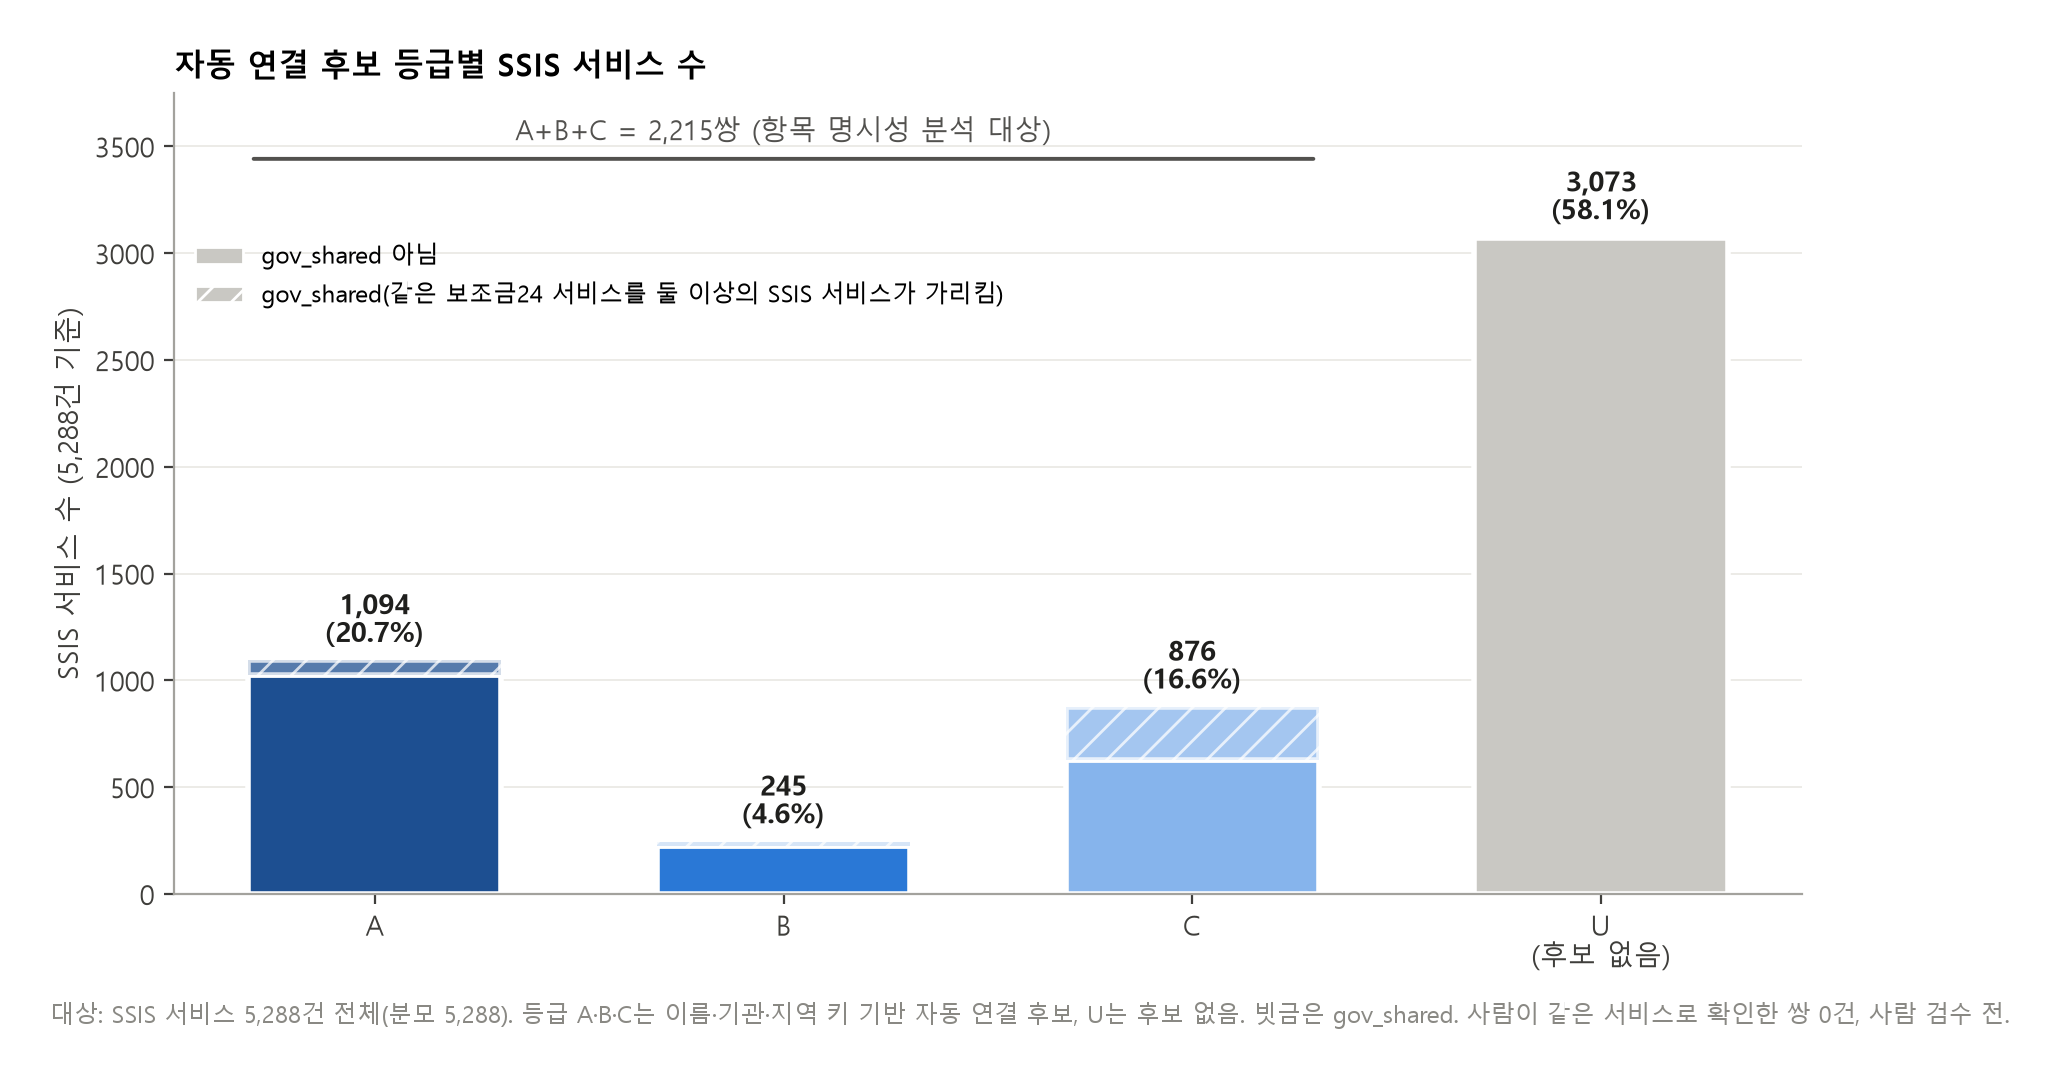

WindowsPath('outputs/04_q2/figures/01_match_tier_distribution.png')

In [5]:
tt = t2[t2.row_type.eq("tier")].set_index("tier")
fig, ax = plt.subplots(figsize=(10.5, 5.2))
cols = {"A": C_DARK, "B": C_MID, "C": C_LIGHT, "U": C_GRAY}
for i, t in enumerate(["A", "B", "C", "U"]):
    n, sh = int(tt.loc[t, "n"]), int(tt.loc[t, "n_gov_shared"])
    ax.bar(i, n - sh, color=cols[t], edgecolor="white", linewidth=2, width=0.62)
    if sh:
        ax.bar(i, sh, bottom=n - sh, color=cols[t], edgecolor="white", linewidth=2, width=0.62, hatch="//", alpha=0.75)
    ax.text(i, n + 60, f"{n:,}\n({100 * n / len(m):.1f}%)", ha="center", va="bottom", fontsize=10, color=INK, fontweight="bold")
ax.set_xticks(range(4), ["A", "B", "C", "U\n(후보 없음)"])
ax.set_ylabel("SSIS 서비스 수 (5,288건 기준)"); ax.set_ylim(0, tt["n"].max() * 1.22)
ax.grid(axis="x", visible=False)
ax.annotate("", xy=(-0.31, tt["n"].max() * 1.12), xytext=(2.31, tt["n"].max() * 1.12), arrowprops=dict(arrowstyle="-", color=INK2, lw=1.4))
ax.text(1, tt["n"].max() * 1.14, f"A+B+C = {N_PAIRS:,}쌍 (항목 명시성 분석 대상)", ha="center", va="bottom", fontsize=10, color=INK2)
ax.legend(handles=[Patch(facecolor=C_GRAY, edgecolor="white", label="gov_shared 아님"), Patch(facecolor=C_GRAY, edgecolor="white", hatch="//", label="gov_shared(같은 보조금24 서비스를 둘 이상의 SSIS 서비스가 가리킴)")], loc="upper left", bbox_to_anchor=(0.0, 0.84), fontsize=8.5)
ax.set_title("자동 연결 후보 등급별 SSIS 서비스 수")
save_fig(fig, "01_match_tier_distribution", f"대상: SSIS 서비스 {len(m):,}건 전체(분모 5,288). 등급 A·B·C는 이름·기관·지역 키 기반 자동 연결 후보, U는 후보 없음. 빗금은 gov_shared. 사람이 같은 서비스로 확인한 쌍 0건, 사람 검수 전.")

In [6]:
sub = t2[t2.row_type.eq("subtotal")].iloc[0]
md(f"""**관찰**
- 5,288건 중 A {int(tt.loc['A','n']):,}건({pc(tt.loc['A','share_of_5288'])}), B {int(tt.loc['B','n']):,}건({pc(tt.loc['B','share_of_5288'])}), C {int(tt.loc['C','n']):,}건({pc(tt.loc['C','share_of_5288'])}), U {int(tt.loc['U','n']):,}건({pc(tt.loc['U','share_of_5288'])})
- A+B+C {int(sub['n']):,}쌍({pc(sub['share_of_5288'])})
- gov_shared 쌍: A {int(tt.loc['A','n_gov_shared'])}, B {int(tt.loc['B','n_gov_shared'])}, C {int(tt.loc['C','n_gov_shared'])}, 합계 {int(sub['n_gov_shared'])}쌍, U는 없음

**해석**
- 건수 = 자동 연결 후보 분포, 같은 서비스 쌍의 수 아님
- C 등급은 gov_shared 비중이 상대적으로 큼
- U {int(tt.loc['U','n']):,}건 = 규칙이 후보를 찾지 못한 건, 연결되지 않았다는 뜻 아님

**한계**
- 한 보조금24 서비스에 여러 SSIS 서비스가 연결된 경우 포함
- 보조금24 쪽 단위는 고유 서비스 수가 아니라 쌍 단위
- 사람 검수 전""")

**관찰**
- 5,288건 중 A 1,094건(20.7%), B 245건(4.6%), C 876건(16.6%), U 3,073건(58.1%)
- A+B+C 2,215쌍(41.9%)
- gov_shared 쌍: A 68, B 19, C 248, 합계 335쌍, U는 없음

**해석**
- 건수 = 자동 연결 후보 분포, 같은 서비스 쌍의 수 아님
- C 등급은 gov_shared 비중이 상대적으로 큼
- U 3,073건 = 규칙이 후보를 찾지 못한 건, 연결되지 않았다는 뜻 아님

**한계**
- 한 보조금24 서비스에 여러 SSIS 서비스가 연결된 경우 포함
- 보조금24 쪽 단위는 고유 서비스 수가 아니라 쌍 단위
- 사람 검수 전

# PART C. 항목 명시성(규칙 기반)

### Decision Box 2 — 비교 모집단과 범위
- **선택:** 주 모집단 `AB_nonshared`(A·B, gov_shared 아님), 참고 `ABC_all`
- **선택:** 주 범위 `text`(설명문), 참고 `all`(구조화 필드 포함)
- **근거:** 사람 검수 표본의 모집단 정의와 동일. `text`는 두 플랫폼의 같은 종류 정보만 비교
- **영향:** 주 모집단 밖 쌍은 표에만 포함

### Decision Box 3 — 메타 라벨 분리
- **선택:** 분모 = 명시 + 부분 + 미명시. 해당없음, 필드없음, 판단불가는 별도 건수
- **근거:** 해당없음, 필드없음은 정보 부재가 아님
- **영향:** 메타 라벨이 많은 항목은 분모 감소

### Decision Box 4 — 거주는 보조 지표
- **선택:** 표와 그림에 표시, 핵심 지표(`core_metric`)에서 제외
- **근거:** 코드북의 거주 규칙 재설계 전 제외 결정

## 3단계. 쌍 집합 × 범위 × 항목 × 플랫폼별 명시성 분포
- 단위: (쌍, side, scope, 항목) 한 행
- 수준: 명시, 부분, 미명시

In [7]:
d = d31.copy()
d["lab"] = V.label(d)
LEVELS, METAS = CB.LEVELS, CB.META                 # 명시·부분·미명시 / 해당없음·필드없음·판단불가
PAIR_SETS = {"ABC_all": d["tier"].isin(["A", "B", "C"]), "AB_nonshared": d["tier"].isin(["A", "B"]) & d["gov_shared"].eq("False")}
ITEMS = list(V.ITEMS)
assert d["lab"].isin(LEVELS + METAS).all()
rows = []
for ps, mask in PAIR_SETS.items():
    s = d[mask]
    for scope in ["text", "all"]:
        for item in ITEMS:
            for side in ["ssis", "gov"]:
                g = s[(s["scope"] == scope) & (s["item"] == item) & (s["side"] == side)]
                vc = g["lab"].value_counts()
                n = {k: int(vc.get(k, 0)) for k in LEVELS + METAS}
                den = n["명시"] + n["부분"] + n["미명시"]
                assert sum(n.values()) == len(g)
                rows.append({"pair_set": ps, "scope": scope, "item": item, "side": side, "core_metric": item in CB.CORE_ITEMS, "n_units": len(g),
                             "n_명시": n["명시"], "n_부분": n["부분"], "n_미명시": n["미명시"], "n_해당없음": n["해당없음"], "n_필드없음": n["필드없음"], "n_판단불가": n["판단불가"],
                             "n_level_denominator": den,
                             "share_명시": n["명시"] / den if den else np.nan, "share_부분": n["부분"] / den if den else np.nan, "share_미명시": n["미명시"] / den if den else np.nan,
                             "n_fields_absent": int(g["fields_absent"].ne("").sum())})
t3 = save_csv(pd.DataFrame(rows), "item_explicitness_distribution")
KO = {"age": "연령", "income": "소득", "residence": "거주(핵심 제외)", "channel": "신청방법", "period": "신청기간", "documents": "구비서류", "contact": "문의처"}
SIDE_KO = {"ssis": "SSIS", "gov": "보조금24"}
main_ = t3[(t3.pair_set == "AB_nonshared") & (t3.scope == "text")].copy()
view = main_.assign(항목=main_["item"].map(KO), 플랫폼=main_["side"].map(SIDE_KO))[["항목", "플랫폼", "n_units", "n_명시", "n_부분", "n_미명시", "n_해당없음", "n_판단불가", "share_명시", "share_부분", "share_미명시"]]
show_table(view, "표 C-1. 항목별 명시성 분포 — AB_nonshared, scope=text (규칙 기반 잠정 분포)",
           fmt={c: "{:.1%}" for c in ["share_명시", "share_부분", "share_미명시"]} | {"n_units": "{:,}"},
           note="비율의 분모는 명시+부분+미명시(해당없음·판단불가 제외). 전체(ABC_all, scope=all 포함)는 `item_explicitness_distribution.csv`. 사람 검수 전.")

**표 C-1. 항목별 명시성 분포 — AB_nonshared, scope=text (규칙 기반 잠정 분포)**

항목,플랫폼,n_units,n_명시,n_부분,n_미명시,n_해당없음,n_판단불가,share_명시,share_부분,share_미명시
연령,SSIS,"1,252",606,232,414,0,0,48.4%,18.5%,33.1%
연령,보조금24,"1,252",562,228,462,0,0,44.9%,18.2%,36.9%
소득,SSIS,"1,252",501,40,711,0,0,40.0%,3.2%,56.8%
소득,보조금24,"1,252",439,44,769,0,0,35.1%,3.5%,61.4%
거주(핵심 제외),SSIS,"1,252",681,93,478,0,0,54.4%,7.4%,38.2%
거주(핵심 제외),보조금24,"1,252",600,73,579,0,0,47.9%,5.8%,46.2%
신청방법,SSIS,"1,252",983,77,192,0,0,78.5%,6.2%,15.3%
신청방법,보조금24,"1,252",1224,11,17,0,0,97.8%,0.9%,1.4%
신청기간,SSIS,"1,252",152,4,1060,36,0,12.5%,0.3%,87.2%
신청기간,보조금24,"1,252",86,4,1052,110,0,7.5%,0.4%,92.1%


<span style='color:#8a8984;font-size:90%'>비율의 분모는 명시+부분+미명시(해당없음·판단불가 제외). 전체(ABC_all, scope=all 포함)는 `item_explicitness_distribution.csv`. 사람 검수 전.</span>

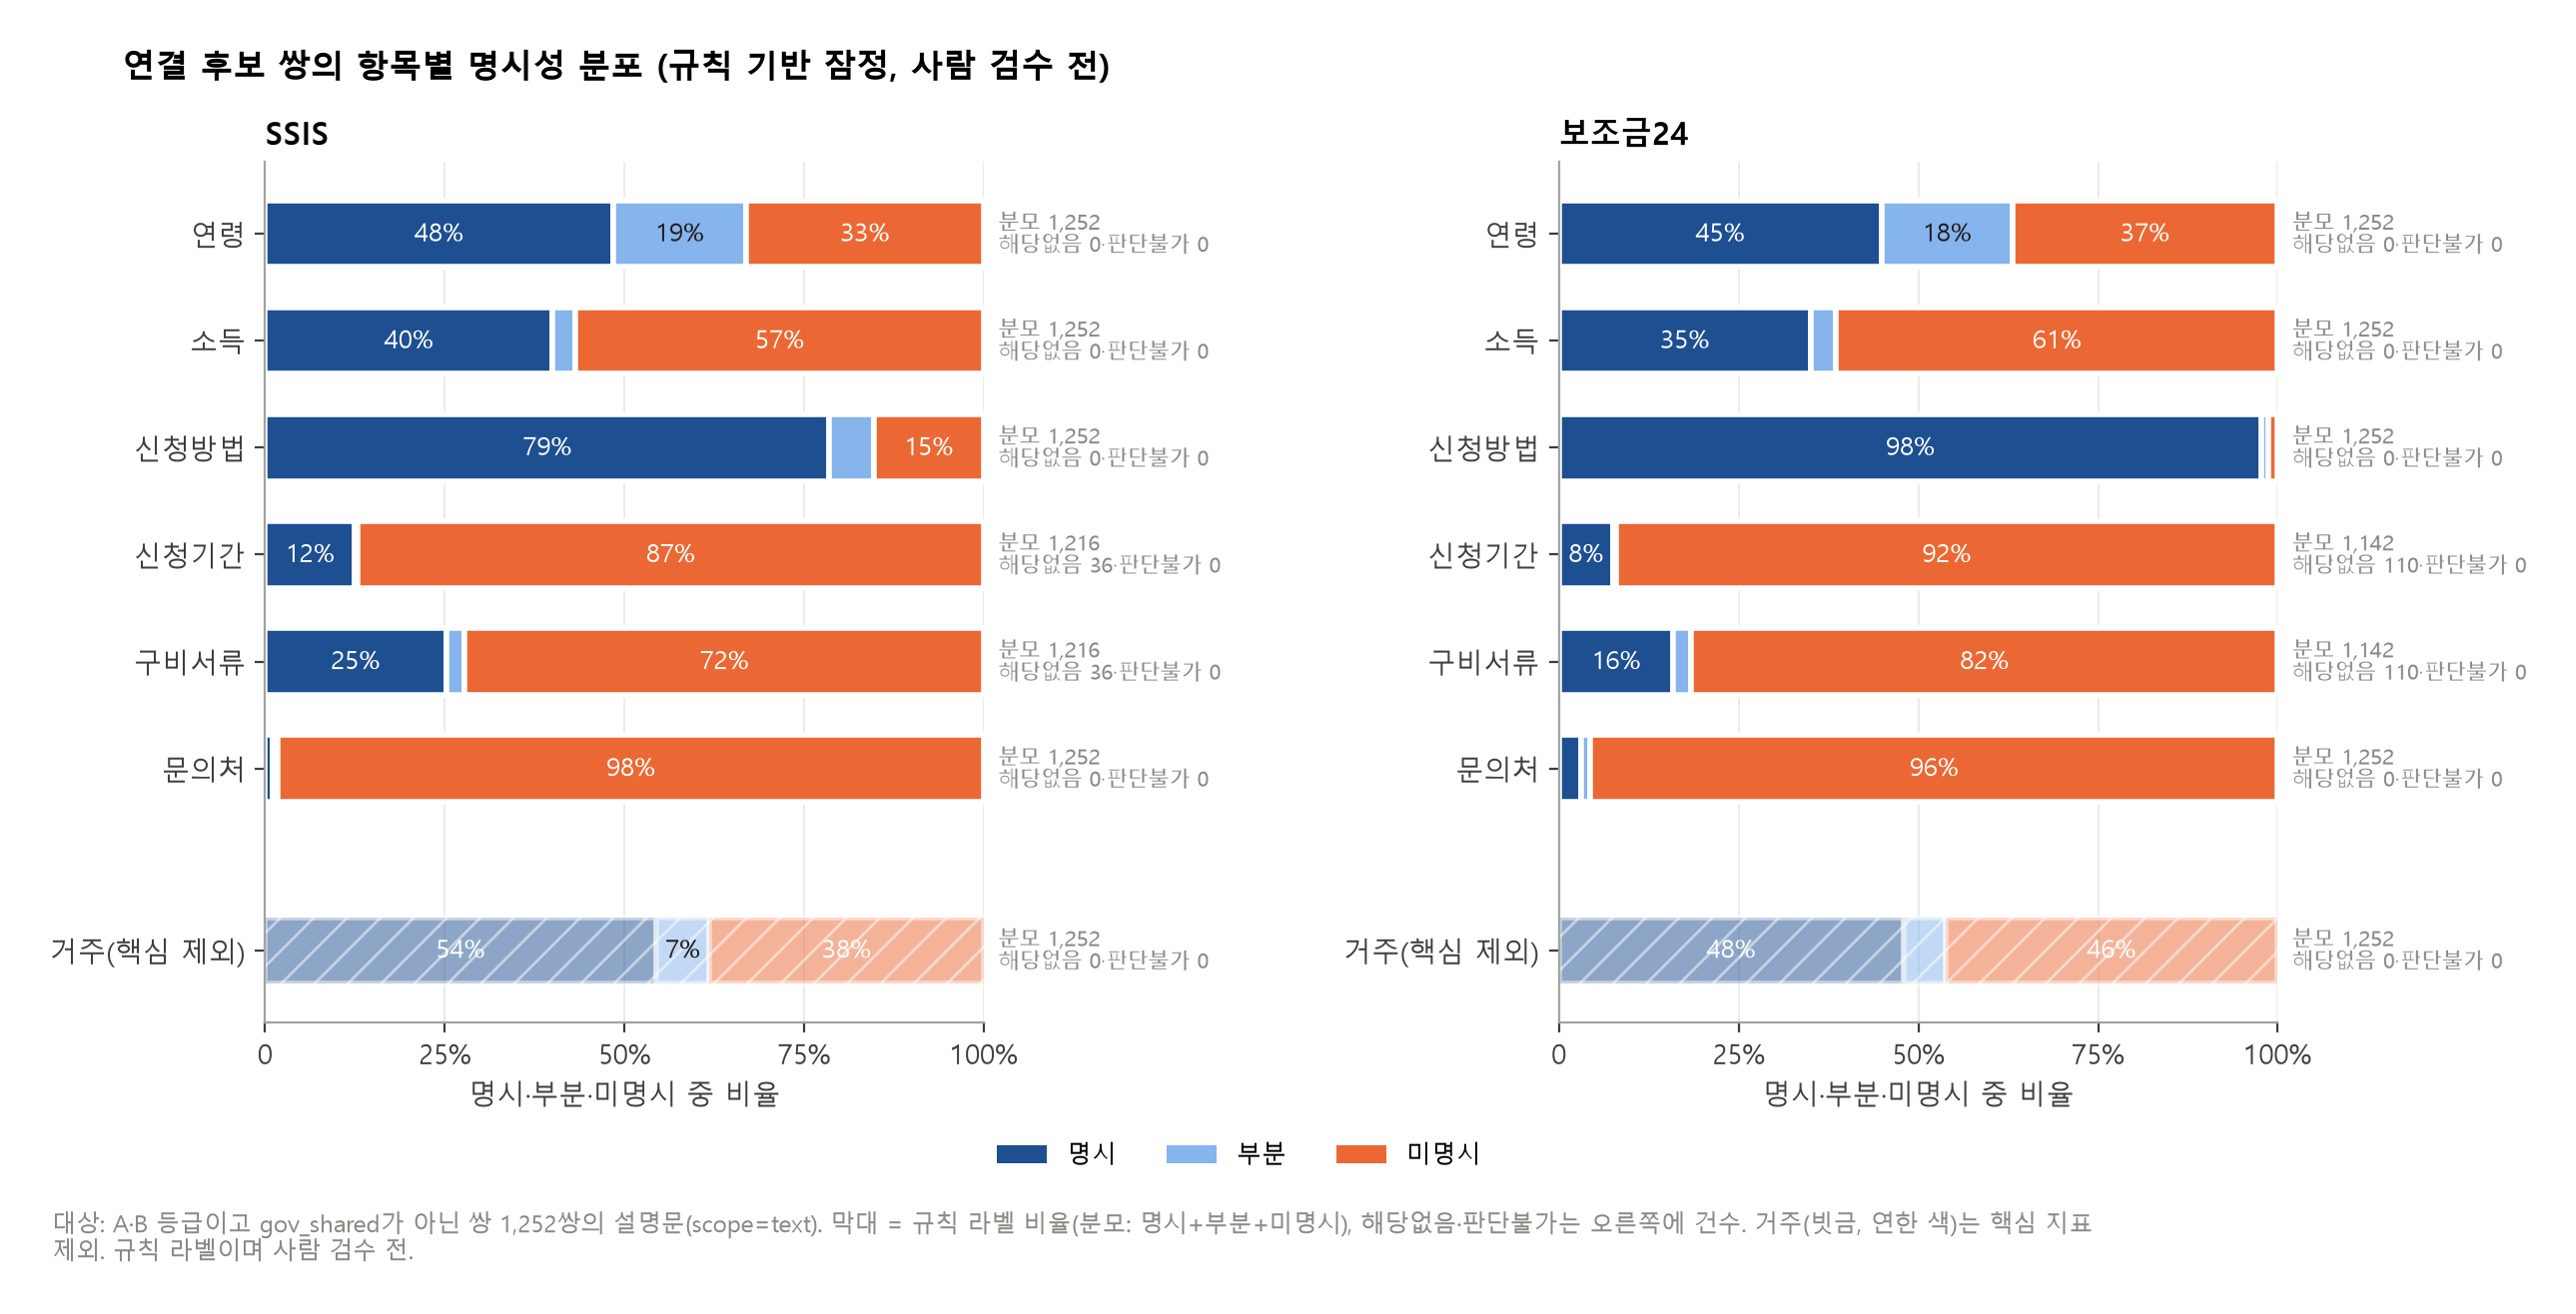

WindowsPath('outputs/04_q2/figures/02_item_explicitness_by_platform.png')

In [8]:
order = [i for i in ITEMS if i in CB.CORE_ITEMS] + [i for i in ITEMS if i not in CB.CORE_ITEMS]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True, gridspec_kw={"wspace": 0.8})
ypos = {it: (k if it in CB.CORE_ITEMS else k + 0.7) for k, it in enumerate(order)}
LV_COL = {"명시": C_DARK, "부분": C_LIGHT, "미명시": C_ORANGE}
for ax, side in zip(axes, ["ssis", "gov"]):
    for it in order:
        r = main_[(main_["item"] == it) & (main_["side"] == side)].iloc[0]
        left, core = 0.0, it in CB.CORE_ITEMS
        for lv in LEVELS:
            w = r[f"share_{lv}"]
            ax.barh(ypos[it], w, left=left, color=LV_COL[lv], edgecolor="white", linewidth=2, height=0.62, alpha=1 if core else 0.5, hatch=None if core else "//")
            if w >= 0.07:
                ax.text(left + w / 2, ypos[it], f"{100 * w:.0f}%", ha="center", va="center", fontsize=9, color="white" if lv != "부분" else INK)
            left += w
        ax.text(1.02, ypos[it], f"분모 {int(r['n_level_denominator']):,}\n해당없음 {int(r['n_해당없음'])}·판단불가 {int(r['n_판단불가'])}", va="center", fontsize=7.5, color=MUTED)
    ax.set_xlim(0, 1); ax.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
    ax.set_title(SIDE_KO[side]); ax.grid(axis="y", visible=False)
axes[0].set_yticks([ypos[i] for i in order], [KO[i] for i in order]); axes[0].invert_yaxis()
axes[1].tick_params(labelleft=True)
axes[1].set_yticks([ypos[i] for i in order], [KO[i] for i in order])
axes[0].set_xlabel("명시·부분·미명시 중 비율"); axes[1].set_xlabel("명시·부분·미명시 중 비율")
fig.legend(handles=[Patch(facecolor=LV_COL[k], label=k) for k in LEVELS], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("연결 후보 쌍의 항목별 명시성 분포 (규칙 기반 잠정, 사람 검수 전)", x=0.07, ha="left", fontsize=12, fontweight="bold")
save_fig(fig, "02_item_explicitness_by_platform", f"대상: A·B 등급이고 gov_shared가 아닌 쌍 {int(main_.n_units.max()):,}쌍의 설명문(scope=text). 막대 = 규칙 라벨 비율(분모: 명시+부분+미명시), 해당없음·판단불가는 오른쪽에 건수. 거주(빗금, 연한 색)는 핵심 지표 제외. 규칙 라벨이며 사람 검수 전.")

In [9]:
core = main_[main_.core_metric]
w = core.pivot(index="item", columns="side", values="share_명시")
gap = (w["gov"] - w["ssis"]).sort_values()
tot_all = t3[(t3.pair_set == "ABC_all") & (t3.scope == "text") & t3.core_metric].groupby("side")[["n_명시", "n_level_denominator"]].sum()
ss_txt = ", ".join(f"{KO[i]} {pc(w.loc[i,'ssis'],0)}" for i in w.index)
gv_txt = ", ".join(f"{KO[i]} {pc(w.loc[i,'gov'],0)}" for i in w.index)
md(f"""**관찰**
- 주 모집단(AB_nonshared, text) {int(main_.n_units.max()):,}쌍
- 핵심 6항목 '명시' 비율, SSIS: {ss_txt}
- 핵심 6항목 '명시' 비율, 보조금24: {gv_txt}
- 보조금24 − SSIS 차이: {KO[gap.index[0]]} {100*gap.iloc[0]:+.1f}%p ~ {KO[gap.index[-1]]} {100*gap.iloc[-1]:+.1f}%p
- 핵심 항목 합산 '명시' 비율(ABC_all): SSIS {pc(tot_all.loc['ssis','n_명시']/tot_all.loc['ssis','n_level_denominator'])}, 보조금24 {pc(tot_all.loc['gov','n_명시']/tot_all.loc['gov','n_level_denominator'])}
- scope=text에서 fields_absent가 비어 있지 않은 단위 {int(main_.n_fields_absent.sum())}건, 필드없음 라벨 {int(t3.n_필드없음.sum())}건

**해석**
- 규칙이 붙인 잠정 라벨의 비율
- 한 플랫폼이 실제 정보를 더 잘 제공한다는 판단 아님
- 합산 비율은 항목별 값을 대신하지 않음

**한계**
- SSIS에는 구비서류, 신청기한 필드 없음(scope=all의 fields_absent): SSIS 미명시의 일부는 구조적 부재 가능
- 연결 후보에 같은 서비스가 아닌 쌍이 있으면 차이 = 서비스 차이 가능
- 사람 검수 후 같은 표로 재산출""")
# 동일 쌍·동일 항목에서 본문과 전용 필드 포함 범위를 분리한다.
keys = ['pair_set','item','side']
cols = ['n_units','n_명시','n_level_denominator','share_명시']
scope_comparison = t3[t3.scope.eq('text')][keys+cols].merge(
    t3[t3.scope.eq('all')][keys+cols],on=keys,suffixes=('_text','_all'),validate='1:1')
scope_comparison['n_explicit_gain'] = scope_comparison.n_명시_all - scope_comparison.n_명시_text
scope_comparison['share_explicit_difference'] = scope_comparison.share_명시_all-scope_comparison.share_명시_text
save_csv(scope_comparison,'scope_sensitivity')
show_table(scope_comparison[scope_comparison.pair_set.eq('AB_nonshared')],
           '표 C-2. 본문(text)·전체 필드(all) 민감도 비교 — 자동 매칭·규칙 라벨 기반 잠정값',
           fmt={'share_명시_text':'{:.1%}','share_명시_all':'{:.1%}','share_explicit_difference':'{:+.1%}'})
sc = scope_comparison.set_index(['pair_set','item','side'])
contact = sc.loc[('AB_nonshared','contact','ssis')]
period = sc.loc[('AB_nonshared','period','gov')]
scope_note = "\n".join([
    f"- 같은 AB_nonshared 후보, SSIS 문의처 명시: 본문 {int(contact.n_명시_text):,}건, 전용 필드 포함 {int(contact.n_명시_all):,}건",
    f"- 보조금24 신청기간 명시: 본문 {int(period.n_명시_text):,}건, 전용 필드 포함 {int(period.n_명시_all):,}건",
])
md("**관찰**\n" + scope_note + """

**해석**
- 본문 명시율 = 공통 설명문 안에서 정보가 드러나는 정도
- 낮은 본문 명시율을 플랫폼 전체의 정보 부족으로 해석하지 않음
- all은 문의처, 신청기한, 구비서류 등 전용 필드 포함, 두 범위를 구분

**한계**
- 플랫폼별 필드 구조 상이
- 범위별 명시+부분+미명시 분모 별도 보존
- 사람 확정 매칭 0건, 잠정값""")

**관찰**
- 주 모집단(AB_nonshared, text) 1,252쌍
- 핵심 6항목 '명시' 비율, SSIS: 연령 48%, 신청방법 79%, 문의처 1%, 구비서류 25%, 소득 40%, 신청기간 12%
- 핵심 6항목 '명시' 비율, 보조금24: 연령 45%, 신청방법 98%, 문의처 3%, 구비서류 16%, 소득 35%, 신청기간 8%
- 보조금24 − SSIS 차이: 구비서류 -9.2%p ~ 신청방법 +19.2%p
- 핵심 항목 합산 '명시' 비율(ABC_all): SSIS 33.9%, 보조금24 34.4%
- scope=text에서 fields_absent가 비어 있지 않은 단위 0건, 필드없음 라벨 0건

**해석**
- 규칙이 붙인 잠정 라벨의 비율
- 한 플랫폼이 실제 정보를 더 잘 제공한다는 판단 아님
- 합산 비율은 항목별 값을 대신하지 않음

**한계**
- SSIS에는 구비서류, 신청기한 필드 없음(scope=all의 fields_absent): SSIS 미명시의 일부는 구조적 부재 가능
- 연결 후보에 같은 서비스가 아닌 쌍이 있으면 차이 = 서비스 차이 가능
- 사람 검수 후 같은 표로 재산출

**표 C-2. 본문(text)·전체 필드(all) 민감도 비교 — 자동 매칭·규칙 라벨 기반 잠정값**

pair_set,item,side,n_units_text,n_명시_text,n_level_denominator_text,share_명시_text,n_units_all,n_명시_all,n_level_denominator_all,share_명시_all,n_explicit_gain,share_explicit_difference
AB_nonshared,age,ssis,1252,606,1252,48.4%,1252,606,1252,48.4%,0,+0.0%
AB_nonshared,age,gov,1252,562,1252,44.9%,1252,562,1252,44.9%,0,+0.0%
AB_nonshared,income,ssis,1252,501,1252,40.0%,1252,501,1252,40.0%,0,+0.0%
AB_nonshared,income,gov,1252,439,1252,35.1%,1252,439,1252,35.1%,0,+0.0%
AB_nonshared,residence,ssis,1252,681,1252,54.4%,1252,681,1252,54.4%,0,+0.0%
AB_nonshared,residence,gov,1252,600,1252,47.9%,1252,600,1252,47.9%,0,+0.0%
AB_nonshared,channel,ssis,1252,983,1252,78.5%,1252,1103,1252,88.1%,120,+9.6%
AB_nonshared,channel,gov,1252,1224,1252,97.8%,1252,1248,1252,99.7%,24,+1.9%
AB_nonshared,period,ssis,1252,152,1216,12.5%,1252,152,1216,12.5%,0,+0.0%
AB_nonshared,period,gov,1252,86,1142,7.5%,1252,1044,1124,92.9%,958,+85.4%


**관찰**
- 같은 AB_nonshared 후보, SSIS 문의처 명시: 본문 13건, 전용 필드 포함 1,204건
- 보조금24 신청기간 명시: 본문 86건, 전용 필드 포함 1,044건

**해석**
- 본문 명시율 = 공통 설명문 안에서 정보가 드러나는 정도
- 낮은 본문 명시율을 플랫폼 전체의 정보 부족으로 해석하지 않음
- all은 문의처, 신청기한, 구비서류 등 전용 필드 포함, 두 범위를 구분

**한계**
- 플랫폼별 필드 구조 상이
- 범위별 명시+부분+미명시 분모 별도 보존
- 사람 확정 매칭 0건, 잠정값

# PART D. 판단 가능성(규칙 기반)

## 4단계. 한 플랫폼 설명만으로 자격, 신청 판단이 가능한 비율
- 자격: 연령, 소득 모두 명시 또는 해당없음
- 신청: 신청방법 명시, 신청기간 명시 또는 해당없음
- 규칙 라벨 기반 잠정값
- 빈 값: 입력에 판단불가 포함

In [10]:
j = jg.merge(m[["servId", "tier", "gov_shared"]], on="servId", how="left", validate="m:1")
assert j["tier"].notna().all()
JMASK = {"ABC_all": j["tier"].isin(["A", "B", "C"]), "AB_nonshared": j["tier"].isin(["A", "B"]) & j["gov_shared"].eq("False")}
rows = []
for ps, mask in JMASK.items():
    for scope in ["text", "all"]:
        for side in ["ssis", "gov"]:
            g = j[mask & j["scope"].eq(scope) & j["side"].eq(side)]
            for kind, col in [("eligibility", "judge_eligibility"), ("application", "judge_application")]:
                nt, nf, nbk = int(g[col].eq("True").sum()), int(g[col].eq("False").sum()), int(g[col].eq("").sum())
                assert nt + nf + nbk == len(g)
                rows.append({"pair_set": ps, "scope": scope, "side": side, "kind": kind, "n_units": len(g), "n_true": nt, "n_false": nf, "n_blank": nbk,
                             "share_true_excl_blank": nt / (nt + nf) if nt + nf else np.nan})
t4 = save_csv(pd.DataFrame(rows), "judgeable_summary")
v4 = t4[(t4.pair_set == "AB_nonshared") & (t4.scope == "text")]
show_table(v4.assign(플랫폼=v4["side"].map(SIDE_KO))[["플랫폼", "kind", "n_units", "n_true", "n_false", "n_blank", "share_true_excl_blank"]], "표 D-1. 판단 가능성 — AB_nonshared, scope=text (규칙 라벨 기반 잠정)",
           fmt={"share_true_excl_blank": "{:.1%}", "n_units": "{:,}"}, note="비율 분모 = n_true + n_false(입력에 판단불가가 있는 빈 값 제외). 나머지 집합·범위는 `judgeable_summary.csv`.")

**표 D-1. 판단 가능성 — AB_nonshared, scope=text (규칙 라벨 기반 잠정)**

플랫폼,kind,n_units,n_true,n_false,n_blank,share_true_excl_blank
SSIS,eligibility,"1,252",278,974,0,22.2%
SSIS,application,"1,252",168,1084,0,13.4%
보조금24,eligibility,"1,252",238,1014,0,19.0%
보조금24,application,"1,252",193,1059,0,15.4%


<span style='color:#8a8984;font-size:90%'>비율 분모 = n_true + n_false(입력에 판단불가가 있는 빈 값 제외). 나머지 집합·범위는 `judgeable_summary.csv`.</span>

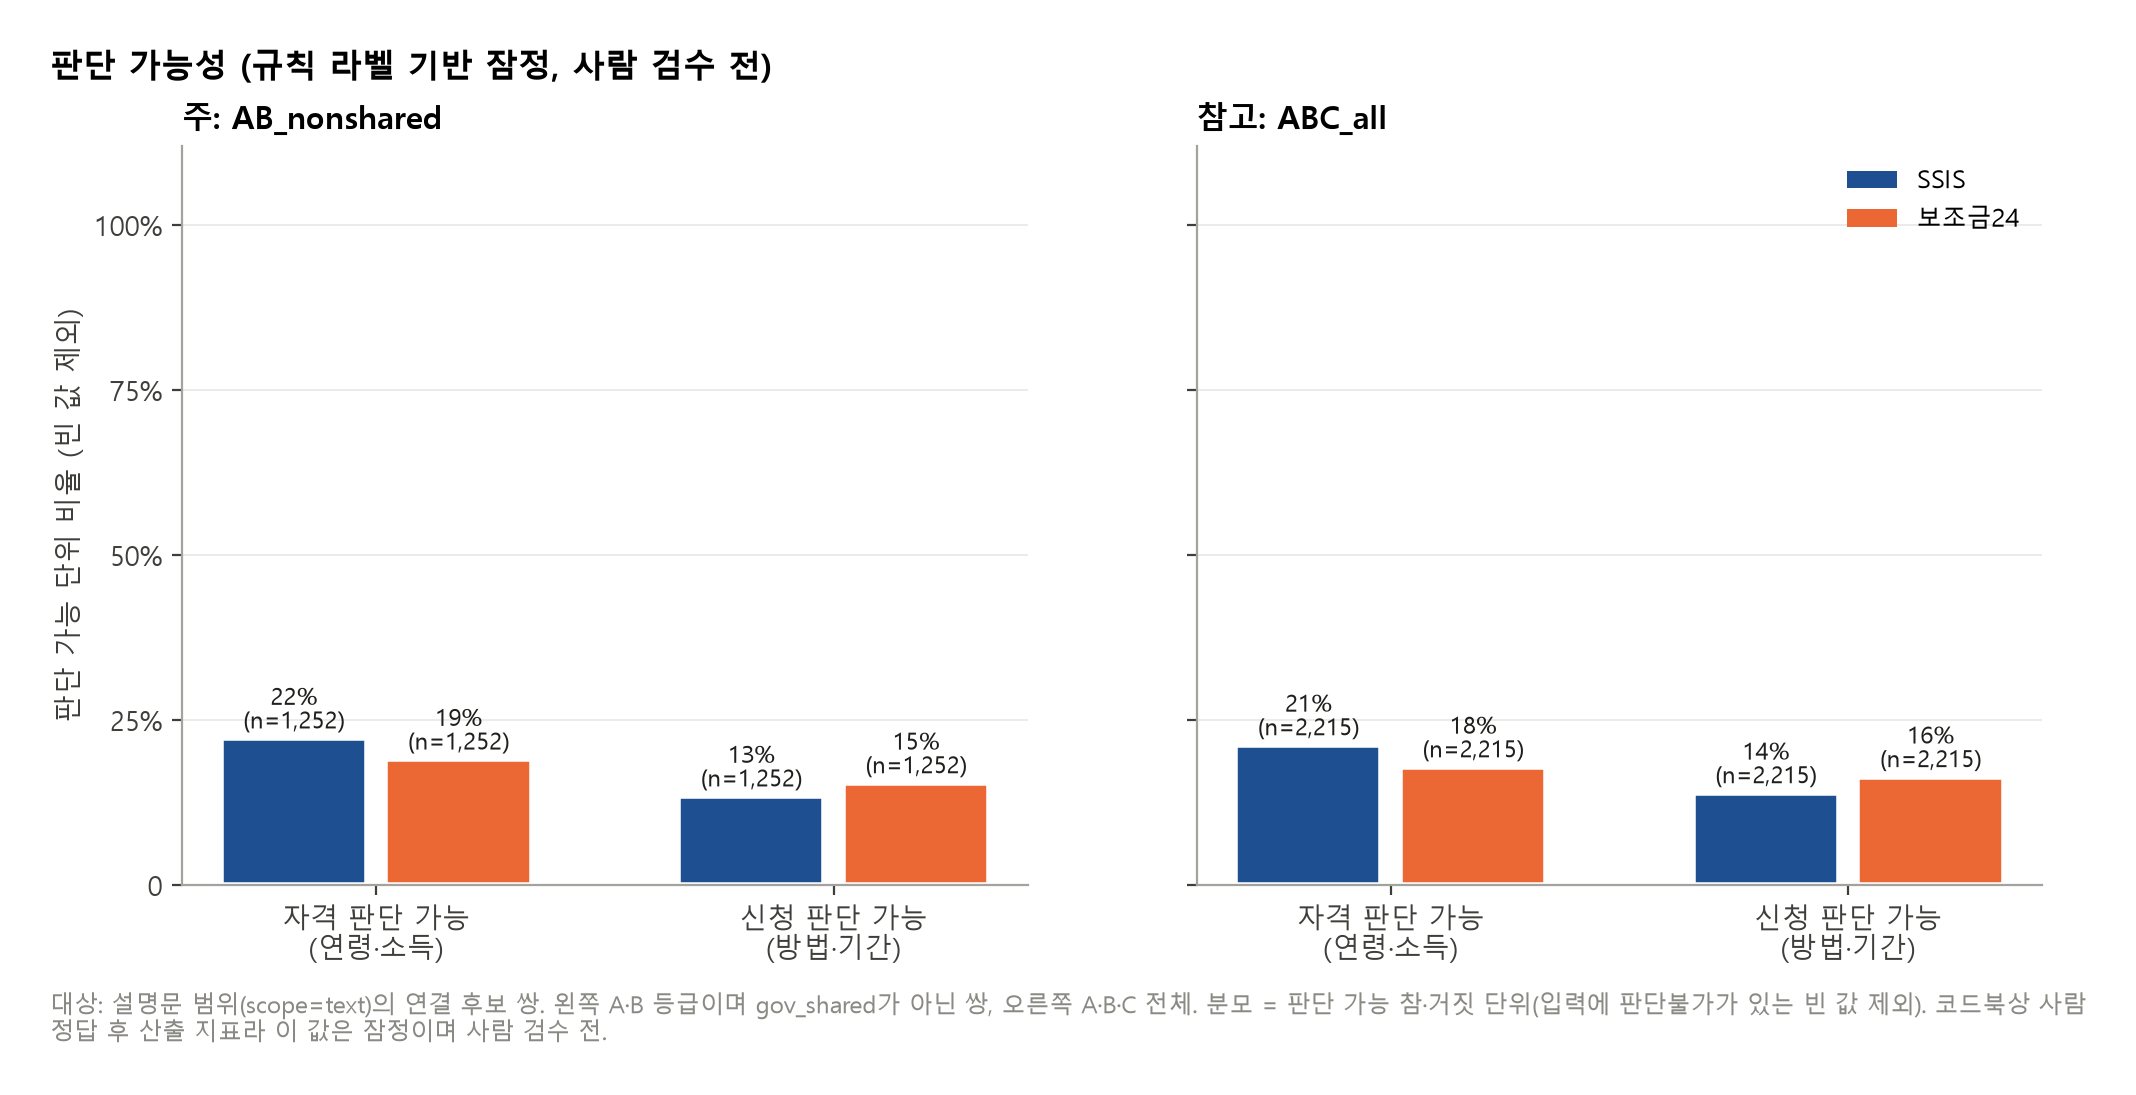

WindowsPath('outputs/04_q2/figures/03_judgeable_by_platform.png')

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
KIND_KO = {"eligibility": "자격 판단 가능\n(연령·소득)", "application": "신청 판단 가능\n(방법·기간)"}
for ax, (ps, ttl) in zip(axes, [("AB_nonshared", "주: AB_nonshared"), ("ABC_all", "참고: ABC_all")]):
    sub_ = t4[(t4.pair_set == ps) & (t4.scope == "text")]
    for k, kind in enumerate(["eligibility", "application"]):
        for s_i, (side, col) in enumerate([("ssis", C_DARK), ("gov", C_ORANGE)]):
            r = sub_[(sub_["kind"] == kind) & (sub_["side"] == side)].iloc[0]
            x = k + (s_i - 0.5) * 0.36
            ax.bar(x, r["share_true_excl_blank"], width=0.32, color=col, edgecolor="white", linewidth=2)
            ax.text(x, r["share_true_excl_blank"] + 0.015, f"{100 * r['share_true_excl_blank']:.0f}%\n(n={int(r['n_true'] + r['n_false']):,})", ha="center", fontsize=8.5, color=INK)
    ax.set_xticks([0, 1], [KIND_KO["eligibility"], KIND_KO["application"]]); ax.set_ylim(0, 1.12); ax.set_title(ttl); ax.grid(axis="x", visible=False)
    ax.set_yticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
axes[0].set_ylabel("판단 가능 단위 비율 (빈 값 제외)")
axes[1].legend(handles=[Patch(facecolor=C_DARK, label="SSIS"), Patch(facecolor=C_ORANGE, label="보조금24")], loc="upper right")
fig.suptitle("판단 가능성 (규칙 라벨 기반 잠정, 사람 검수 전)", x=0.07, ha="left", fontsize=12, fontweight="bold")
save_fig(fig, "03_judgeable_by_platform", "대상: 설명문 범위(scope=text)의 연결 후보 쌍. 왼쪽 A·B 등급이며 gov_shared가 아닌 쌍, 오른쪽 A·B·C 전체. 분모 = 판단 가능 참·거짓 단위(입력에 판단불가가 있는 빈 값 제외). 코드북상 사람 정답 후 산출 지표라 이 값은 잠정이며 사람 검수 전.")

In [12]:
p_ = v4.set_index(["side", "kind"])["share_true_excl_blank"]
md(f"""**관찰**
- AB_nonshared, text 자격 판단 가능 비율: SSIS {pc(p_[('ssis','eligibility')])}, 보조금24 {pc(p_[('gov','eligibility')])}
- 신청 판단 가능 비율: SSIS {pc(p_[('ssis','application')])}, 보조금24 {pc(p_[('gov','application')])}
- 빈 값(입력에 판단불가 포함) 단위 {int(v4.n_blank.sum())}건

**해석**
- 규칙 라벨 기반 잠정 비율
- 코드북은 사람 정답 후 산출하도록 정의한 지표, 이를 앞서 계산한 값

**한계**
- 신청 판단은 신청기간 항목에 의존, SSIS에는 해당 필드 없음: 구조적으로 불리 가능
- 사람 정답 후 같은 표로 재산출""")

**관찰**
- AB_nonshared, text 자격 판단 가능 비율: SSIS 22.2%, 보조금24 19.0%
- 신청 판단 가능 비율: SSIS 13.4%, 보조금24 15.4%
- 빈 값(입력에 판단불가 포함) 단위 0건

**해석**
- 규칙 라벨 기반 잠정 비율
- 코드북은 사람 정답 후 산출하도록 정의한 지표, 이를 앞서 계산한 값

**한계**
- 신청 판단은 신청기간 항목에 의존, SSIS에는 해당 필드 없음: 구조적으로 불리 가능
- 사람 정답 후 같은 표로 재산출

# PART E. 보조금24 내부 불일치, 출생 규칙 변경, 거주

## 5단계. 보조금24 내부 불일치(구조화 조건 대 본문)
- 플랫폼 간 차이가 아닌 보조금24 내부 불일치
- `gov24_eligibility.csv`: 현재 코드보다 이전 버전으로 생성
- E-2: 보조금24 전체 기준 점검 파일
- E-3: 연결 후보 쌍 안의 보조금24 규칙 사용 단위

In [13]:
t5 = save_csv(GI.counts(gi), "gov24_internal_counts")
t6 = save_csv(pd.read_csv(RULES / "gov24_default_check.csv", encoding="utf-8-sig"), "gov24_default_check")
GOV_RULES = ["gov_deadline_default", "gov_deadline_contradicted", "gov_docs_ambiguous", "gov_docs_field_contradicted", "gov_docs_na_consistent"]
g7 = d31[d31["side"].eq("gov")]
rows = []
for scope in ["text", "all"]:
    for rid in GOV_RULES:
        x = g7[g7["scope"].eq(scope) & g7["rule_id"].eq(rid)]
        rows.append({"side": "gov", "scope": scope, "rule_id": rid, "n_units": len(x), "n_gov_id_unique": int(x["gov_id"].nunique())})
t7 = save_csv(pd.DataFrame(rows), "gov24_default_rules_in_pairs")
show_table(t5.drop(columns=["scope"]), "표 E-1. 보조금24 내부 불일치 건수(JA 구조화 조건 대 본문)", note=f"{GI.LABEL}. {CB.GOV24_INTERNAL['caveat']}.")
show_table(t6, "표 E-2. 전체 보조금24 기본값 점검(저장 파일 그대로)", fmt={"share_of_field": "{:.4f}", "n": "{:,}"})
show_table(t7, "표 E-3. 연결 후보 쌍 안 보조금24 쪽 규칙 사용 단위", note="쌍 단위이므로 n_units는 고유 서비스 수가 아니다. n_gov_id_unique가 고유 gov_id 수.")

**표 E-1. 보조금24 내부 불일치 건수(JA 구조화 조건 대 본문)**

column,value,n_pairs,n_gov_services
elig_income_check,구간 경계,16,15
elig_income_check,불일치,14,14
elig_income_check,비교 불가,1995,1828
elig_income_check,일치,190,179
elig_income_conflict,False,2201,2022
elig_income_conflict,True,14,14
elig_age_text_differs,False,2132,1958
elig_age_text_differs,True,83,78
elig_age_conflict,False,2215,2036


<span style='color:#8a8984;font-size:90%'>보조금24 내부(JA 구조화 조건 대 본문) 불일치: 플랫폼 간 차이와 별개. 커밋된 CSV는 현재 저장소 코드보다 이전 버전으로 생성됨(방문 신청 판정 3건 차이 확인). 연령 본문 차이는 원 작성자가 참고용으로 지정.</span>

**표 E-2. 전체 보조금24 기본값 점검(저장 파일 그대로)**

field,branch,n,share_of_field
구비서류 해당없음/없음,ambiguous,"3,102",0.7116
구비서류 해당없음/없음,consistent,734,0.1684
구비서류 해당없음/없음,contradicted,523,0.1200
신청기한 상시신청,contradicted,259,0.0402
신청기한 상시신청,default,"6,186",0.9598


**표 E-3. 연결 후보 쌍 안 보조금24 쪽 규칙 사용 단위**

side,scope,rule_id,n_units,n_gov_id_unique
gov,text,gov_deadline_default,0,0
gov,text,gov_deadline_contradicted,0,0
gov,text,gov_docs_ambiguous,0,0
gov,text,gov_docs_field_contradicted,0,0
gov,text,gov_docs_na_consistent,0,0
gov,all,gov_deadline_default,1193,1088
gov,all,gov_deadline_contradicted,62,49
gov,all,gov_docs_ambiguous,386,359
gov,all,gov_docs_field_contradicted,49,45
gov,all,gov_docs_na_consistent,199,192


<span style='color:#8a8984;font-size:90%'>쌍 단위이므로 n_units는 고유 서비스 수가 아니다. n_gov_id_unique가 고유 gov_id 수.</span>

In [14]:
by_scope = t7.groupby("scope")["n_units"].sum()
q_ = lambda f, b: int(t6[(t6["field"] == f) & (t6["branch"] == b)]["n"].iloc[0])
md(f"""**관찰**
- 보조금24 내부 불일치 표(E-1): 열 {t5['column'].nunique()}개, {len(t5)}행
- 전체 보조금24 점검(E-2), 구비서류 '해당없음/없음' 분기: 모호 {q_('구비서류 해당없음/없음','ambiguous'):,}건, 모순 {q_('구비서류 해당없음/없음','contradicted'):,}건, 일치 {q_('구비서류 해당없음/없음','consistent'):,}건
- 신청기한 '상시' 분기: 기본값 {q_('신청기한 상시신청','default'):,}건, 모순 {q_('신청기한 상시신청','contradicted'):,}건

**지시와 다른 점**
- 연결 후보 쌍 안 `gov_deadline_*`, `gov_docs_*` 규칙: scope=text {int(by_scope.get('text', 0))}단위, scope=all {int(by_scope.get('all', 0))}단위
- 구조화 필드를 쓰는 scope=all에서만 사용, 설명문 범위(text)에는 없음
- 값을 맞추지 않고 두 범위 모두 표시

**해석**
- JA 구조화 조건과 본문의 불일치 = 보조금24 내부 문제
- 플랫폼 간 차이로 읽지 않음

**한계**
- 원 CSV가 이전 코드 버전으로 생성: 현재 규칙과 일부 차이 가능
- 모두 사람 검수 전""")

**관찰**
- 보조금24 내부 불일치 표(E-1): 열 4개, 9행
- 전체 보조금24 점검(E-2), 구비서류 '해당없음/없음' 분기: 모호 3,102건, 모순 523건, 일치 734건
- 신청기한 '상시' 분기: 기본값 6,186건, 모순 259건

**지시와 다른 점**
- 연결 후보 쌍 안 `gov_deadline_*`, `gov_docs_*` 규칙: scope=text 0단위, scope=all 1889단위
- 구조화 필드를 쓰는 scope=all에서만 사용, 설명문 범위(text)에는 없음
- 값을 맞추지 않고 두 범위 모두 표시

**해석**
- JA 구조화 조건과 본문의 불일치 = 보조금24 내부 문제
- 플랫폼 간 차이로 읽지 않음

**한계**
- 원 CSV가 이전 코드 버전으로 생성: 현재 규칙과 일부 차이 가능
- 모두 사람 검수 전

## 6단계. '출산' 범주 규칙(v3.1)으로 바뀐 연령 라벨
- 대상: v3 미명시 → v3.1 부분(rule `age_birth_category`)
- 등급별, side별 단위 수

In [15]:
x = V31.diff_vs_v3(d31, d3)
y = x[(x["item"] == "age") & (x["scope"] == "text") & (x["lab_3"] == "미명시") & (x["lab_31"] == "부분") & (x["rule_id_31"] == "age_birth_category")]
rows = []
for t in ["A", "B", "C", "전체"]:
    g = y if t == "전체" else y[y["tier_31"] == t]
    for side in ["ssis", "gov", "합계"]:
        h = g if side == "합계" else g[g["side"] == side]
        rows.append({"tier": t, "side": side, "n_units": len(h), "n_unique_pairs": int(h[["servId", "gov_id"]].drop_duplicates().shape[0])})
t8 = save_csv(pd.DataFrame(rows), "age_birth_v31_change")
show_table(t8, "표 E-4. v3 미명시 → v3.1 부분(age_birth_category) 연령 단위 (scope=text)")
all_ = t8[(t8.tier == "전체")].set_index("side")
md(f"""**관찰**
- 변경 단위 {int(all_.loc['합계','n_units'])}개(SSIS {int(all_.loc['ssis','n_units'])}, 보조금24 {int(all_.loc['gov','n_units'])})
- 고유 쌍 {int(all_.loc['합계','n_unique_pairs'])}쌍

**지시와 다른 점**
- 지시서의 '출산' 기준값 218, 재현값 {int(all_.loc['합계','n_units'])}(본문 범위 단위)로 불일치
- 218을 재현하는 집계 기준 찾지 못함
- 218로 맞추지 않고 코드 계산값 사용

**해석**
- 같은 규칙 변경을 받은 단위 수

**한계**
- 연령 명시성의 사람 정답 아님""")

**표 E-4. v3 미명시 → v3.1 부분(age_birth_category) 연령 단위 (scope=text)**

tier,side,n_units,n_unique_pairs
A,ssis,68,68
A,gov,70,70
A,합계,138,98
B,ssis,13,13
B,gov,13,13
B,합계,26,21
C,ssis,35,35
C,gov,33,33
C,합계,68,51
전체,ssis,116,116


**관찰**
- 변경 단위 232개(SSIS 116, 보조금24 116)
- 고유 쌍 170쌍

**지시와 다른 점**
- 지시서의 '출산' 기준값 218, 재현값 232(본문 범위 단위)로 불일치
- 218을 재현하는 집계 기준 찾지 못함
- 218로 맞추지 않고 코드 계산값 사용

**해석**
- 같은 규칙 변경을 받은 단위 수

**한계**
- 연령 명시성의 사람 정답 아님

## 7단계. 거주 항목의 제외 사유와 분포
- 제외 사유: `CB.EXCLUDED_ITEMS`
- 현재 규칙 라벨 분포

In [16]:
rows = [{"kind": "exclusion_reason", "item": k, "pair_set": "", "scope": "", "side": "", "label": "", "n": np.nan, "text": v} for k, v in CB.EXCLUDED_ITEMS.items()]
for ps, mask in PAIR_SETS.items():
    s = d[mask & d["item"].eq("residence")]
    for scope in ["text", "all"]:
        for side in ["ssis", "gov"]:
            vc = s[(s["scope"] == scope) & (s["side"] == side)]["lab"].value_counts()
            for lab in LEVELS + METAS:
                rows.append({"kind": "distribution", "item": "residence", "pair_set": ps, "scope": scope, "side": side, "label": lab, "n": int(vc.get(lab, 0)), "text": ""})
t9 = save_csv(pd.DataFrame(rows), "residence_excluded")
r9 = t9[(t9.kind == "distribution") & (t9.pair_set == "AB_nonshared") & (t9.scope == "text")].pivot(index="label", columns="side", values="n").loc[LEVELS + METAS]
show_table(r9.reset_index().rename(columns={"gov": "보조금24", "ssis": "SSIS"}), "표 E-5. 거주 라벨 분포 — AB_nonshared, scope=text", note="핵심 지표에서 제외. 전체는 `residence_excluded.csv`.")
md(f"""**관찰**
- 거주는 `core_metric` 거짓 항목, 제외 사유 "{CB.EXCLUDED_ITEMS['residence']}"
- AB_nonshared, text 명시: SSIS {int(r9.loc['명시','ssis'])}건, 보조금24 {int(r9.loc['명시','gov'])}건

**한계**
- 거주 규칙 재설계 전, 플랫폼 간 비교 결론에 쓰지 않음""")

**표 E-5. 거주 라벨 분포 — AB_nonshared, scope=text**

label,보조금24,SSIS
명시,600.000000,681.000000
부분,73.000000,93.000000
미명시,579.000000,478.000000
해당없음,0.000000,0.000000
필드없음,0.000000,0.000000
판단불가,0.000000,0.000000


<span style='color:#8a8984;font-size:90%'>핵심 지표에서 제외. 전체는 `residence_excluded.csv`.</span>

**관찰**
- 거주는 `core_metric` 거짓 항목, 제외 사유 "규칙 재설계 전까지 핵심 지표에서 제외, 보조 지표로만 보고"
- AB_nonshared, text 명시: SSIS 681건, 보조금24 600건

**한계**
- 거주 규칙 재설계 전, 플랫폼 간 비교 결론에 쓰지 않음

# PART F. 검수 파일 현황

### Decision Box 5 — 블라인드 보호
- **선택:** 서비스 단위 식별자와 등급, 규칙 판정, AI 판정을 한 표에 두지 않음
- **근거:** 조정 판정 전 규칙 라벨이 정답처럼 보이는 것 방지
- **영향:** 사례 기반 설명 없음

### Decision Box 6 — 검수 집계는 임시 사본에서 실행
- **문제:** 기존 집계 함수가 검수 폴더에 결과를 다시 씀
- **선택:** 정정 사본을 임시 폴더에 복사해 집계, 결과는 `final/`에 저장
- **근거:** 검수 원본과 조정 판정표 보호
- **영향:** 원본 그대로의 집계표 미생성. 검수 전 기록 `review_status.csv` 유지

## 8단계. 검수 파일 현황(읽기 전용)
- 파일별 행 수, 고유 단위 수, 판정 입력 건수

In [17]:
def fcount(path, cols, idcol=None):
    t = V.read(path)
    flt = t[cols].apply(lambda s: s.str.strip().ne("")).any(axis=1) if cols else pd.Series(False, index=t.index)
    return len(t), (t[idcol].nunique() if idcol else np.nan), int(flt.sum())
rows = []
def add(group, path, cols, idcol, role):
    n, u, f = fcount(path, cols, idcol)
    rows.append({"group": group, "file": rel(path), "role": role, "n_rows": n, "n_unique_ids": u, "judgment_cols": "|".join(cols) or "없음", "n_filled": f,
                 "status": "검수 전(판정 0건)" if (cols and f == 0) else ("판정 입력됨" if cols else "색인(판정 열 없음)")})
for r in RV.REVIEWERS:
    add("매칭 사람 검수", MATCHV / "human" / f"review_{r}.csv", ["h_same"], "item_no", "사람 표본 시트")
add("매칭 AI 검수 시트", MATCHV / "match_review_sheet.csv", ["h_same"], "servId", "AI 검수 시트(사람 표본과 다름)")
for r in IR.REVIEWERS:
    add("항목 사람 검수", RULES / "human" / f"item_review_{r}.csv", ["h_level", "h_meta"], "sample_id", "사람 표본 시트")
add("항목 사람 검수", RULES / "human" / "item_gold_index.csv", [], "sample_id", "표본 색인")
add("보조금24 화면 점검", RULES / "human" / "gov24_screen_check.csv", ["h_page_found", "h_page_docs", "h_page_deadline", "h_docs_match_api", "h_deadline_match_api"], None, "화면 점검 시트")
t10 = save_final(pd.DataFrame(rows), "review_status_final")
show_table(t10.assign(파일=t10["file"].str.split("/").str[-1]).drop(columns=["file"]), "표 F-1. 검수 파일 현황", note="식별자는 개수만 센다. 판정 내용은 표시하지 않는다.")
mr = t10[t10.group.eq("매칭 사람 검수")]; ir = t10[t10.group.eq("항목 사람 검수") & t10.judgment_cols.ne("없음")]
ids_m = pd.concat([V.read(ROOT / p)["item_no"] for p in mr["file"]]); ids_i = pd.concat([V.read(ROOT / p)["sample_id"] for p in ir["file"]])
md(f"""**관찰**
- 매칭 사람 검수 시트 4개: 합계 {int(mr.n_rows.sum())}행, 고유 {ids_m.nunique()}쌍(중복 {int(mr.n_rows.sum()) - ids_m.nunique()}쌍), 판정 입력 {int(mr.n_filled.sum())}행
- 항목 사람 검수 시트 4개: 합계 {int(ir.n_rows.sum())}행, 고유 {ids_i.nunique()}단위(중복 {int(ir.n_rows.sum()) - ids_i.nunique()}), 판정 입력 {int(ir.n_filled.sum())}행

**지시와 다른 점**
- 170 = 사람 표본이 아니라 AI 검수 시트(`match_review_sheet.csv`, {int(t10[t10.group.eq('매칭 AI 검수 시트')].n_rows.iloc[0])}행)의 행 수
- 사람 표본 = 위의 {ids_m.nunique()}쌍

**해석**
- 판정 입력 완료 상태
- 확정, 미해결 집계와 정확도는 PART H에서 고친 사본으로 계산

**한계**
- 이 표는 `final/review_status_final.csv`에 저장, 검수 전 기록 `review_status.csv`는 그대로 둠""")

**표 F-1. 검수 파일 현황**

group,role,n_rows,n_unique_ids,judgment_cols,n_filled,status,파일
매칭 사람 검수,사람 표본 시트,24,24.000000,h_same,24,판정 입력됨,review_R1.csv
매칭 사람 검수,사람 표본 시트,24,24.000000,h_same,24,판정 입력됨,review_R2.csv
매칭 사람 검수,사람 표본 시트,24,24.000000,h_same,24,판정 입력됨,review_R3.csv
매칭 사람 검수,사람 표본 시트,24,24.000000,h_same,24,판정 입력됨,review_R4.csv
매칭 AI 검수 시트,AI 검수 시트(사람 표본과 다름),170,170.000000,h_same,0,검수 전(판정 0건),match_review_sheet.csv
항목 사람 검수,사람 표본 시트,40,40.000000,h_level|h_meta,40,판정 입력됨,item_review_R1.csv
항목 사람 검수,사람 표본 시트,39,39.000000,h_level|h_meta,39,판정 입력됨,item_review_R2.csv
항목 사람 검수,사람 표본 시트,39,39.000000,h_level|h_meta,39,판정 입력됨,item_review_R3.csv
항목 사람 검수,사람 표본 시트,40,40.000000,h_level|h_meta,40,판정 입력됨,item_review_R4.csv
항목 사람 검수,표본 색인,128,128.000000,없음,0,색인(판정 열 없음),item_gold_index.csv


<span style='color:#8a8984;font-size:90%'>식별자는 개수만 센다. 판정 내용은 표시하지 않는다.</span>

**관찰**
- 매칭 사람 검수 시트 4개: 합계 96행, 고유 72쌍(중복 24쌍), 판정 입력 96행
- 항목 사람 검수 시트 4개: 합계 158행, 고유 128단위(중복 30), 판정 입력 158행

**지시와 다른 점**
- 170 = 사람 표본이 아니라 AI 검수 시트(`match_review_sheet.csv`, 170행)의 행 수
- 사람 표본 = 위의 72쌍

**해석**
- 판정 입력 완료 상태
- 확정, 미해결 집계와 정확도는 PART H에서 고친 사본으로 계산

**한계**
- 이 표는 `final/review_status_final.csv`에 저장, 검수 전 기록 `review_status.csv`는 그대로 둠

In [18]:
filled_match = int(mr["n_filled"].sum())
filled_item = int(ir["n_filled"].sum())
print(f"사람 판정 입력: 매칭 {filled_match}행, 항목 {filled_item}행. 확정·미해결 집계는 PART H(q2_final, 고친 사본, 임시 폴더)에서 수행한다.")
print("검수자 원본 CSV를 그대로 집계한 review_*.csv, item_review_*.csv는 만들지 않는다(원본에 지수 표기 등 형식 오류가 있음).")

사람 판정 입력: 매칭 96행, 항목 158행. 확정·미해결 집계는 PART H(q2_final, 고친 사본, 임시 폴더)에서 수행한다.
검수자 원본 CSV를 그대로 집계한 review_*.csv, item_review_*.csv는 만들지 않는다(원본에 지수 표기 등 형식 오류가 있음).


### Decision Box 7 — 제외 항목
- 사례 단위 규칙 판정 목록: 블라인드 보호로 제외
- 앱 화면용 F2, F3 표: 별도 단계
- 매칭 임계값 결정: 기존 `q2_match.py` 값 유지
- 새 규칙, 정규식, 점수: 없음

# PART H. 검수 확정 후 최종 분석
- 대상: 사람 검수 확정 단위
- 계산: `src/preprocess/q2_final.py` 함수 호출
- 입력: 검수 원본(읽기 전용), 정정 사본, 정정 로그
- 확정: 단독 검수, 중복 검수 두 판정 일치, 제3자 조정
- 조정: 중복 검수 불일치는 제3자 판정(`review_adjudication.csv`, `item_review_adjudication.csv`)으로 확정
- 저장: `outputs/04_q2/tables/final/`, `figures/final/`
- H-5, H-6 명시율: 규칙 v3.1 라벨, 자동 후보 A·B 비공유 쌍

## H-0. 최종 표 계산
- `q2_final.build_all`로 12개 표 계산, `final/` 저장
- 화면 표시에서만 반올림

In [19]:
from src.preprocess import q2_final as QF
FT = QF.build_all(ROOT)
for _k, _v in FT.items():
    save_final(_v, _k)
ST = QF.build_supp(ROOT, FT)
for _k, _v in ST.items():
    save_final(_v, _k)
TEAM = {}
SL = {"ssis": "SSIS", "gov": "보조금24"}
PCT = lambda x, d=1: f"{100 * x:.{d}f}%"
OBS, INT, LIM = {}, {}, {}          # 관찰·해석·한계 문구. HTML에서 같은 문구를 쓴다.
ORDER_I = ["age", "income", "channel", "period", "documents", "contact"]   # 핵심 6항목
ORDER_ALL = ORDER_I + ["residence"]
SC = {"ssis": C_DARK, "gov": C_ORANGE}


def kn(k, n):
    return f"{int(k)}/{int(n)}"


def ci2(lo, hi, d=1):
    return f"{100 * lo:.{d}f}~{100 * hi:.{d}f}%"


def fmt_p(p):
    return "p<0.001" if p < 0.001 else f"p={p:.3f}"


def rfmt(df):
    """화면 표시용 반올림(저장 CSV는 원값)."""
    f = {}
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            f[c] = "{:.0f}" if c.startswith("n_") or c in ("n", "b_gov_only", "c_ssis_only") else ("{:.3g}" if c.endswith("_p") else "{:.3f}")
    return f


def disp(df, title, drop=(), note=None, max_rows=None):
    d_ = df.drop(columns=[c for c in drop if c in df.columns])
    show_table(d_, title, fmt=rfmt(d_), note=note, max_rows=max_rows)


print({k: v.shape for k, v in FT.items()})

{'adjudication_match': (72, 10), 'adjudication_item': (128, 10), 'unresolved_match': (0, 11), 'unresolved_item': (0, 13), 'match_accuracy': (5, 18), 'item_rule_accuracy': (21, 14), 'explicitness_by_platform': (28, 13), 'platform_paired_tests': (14, 19), 'text_vs_all': (14, 27), 'agreement': (2, 13), 'agreement_by_pair': (12, 6), 'unresolved_summary': (2, 5)}


## H-1. 정정 로그 요약
- 대상: 검수 원본의 기록 오류를 고친 사본과 정정 로그
- 집계: 파일별, 정정 규칙별, 상태별 셀 수
- 행 식별자 미표시

In [20]:
fixlog = pd.read_csv(ROOT / "logs" / "validation" / "q2_final" / "fix_log.csv", dtype=str, encoding="utf-8-sig", keep_default_na=False)
RULE_OF = {"gov_id": "1. gov_id 지수 표기 복원", "h_alt_gov_id": "2. 대안 gov_id 지수 표기 복원", "h_basis": "3. 구분자 통일('|')", "h_conflict": "3. 구분자 통일('|')",
           "h_evidence": "4. 증거 칸 위치 교정", "h_meta": "4. 증거 칸 위치 교정", "reviewer,reviewed_at": "5. 검수자·일시 공란(수정 안 함)"}
assert set(fixlog["column"]) <= set(RULE_OF), set(fixlog["column"]) - set(RULE_OF)
fl = fixlog.assign(rule=fixlog["column"].map(RULE_OF))
fix_sum = fl.groupby(["file", "rule", "status"]).agg(n_cells=("column", "size"), n_rows=("row_key", "nunique")).reset_index()
fix_sum["note"] = "건수만 기록(행 식별자는 fix_log.csv)"
save_final(fix_sum, "fix_log_summary")
disp(fix_sum, "표 H-1. 정정 로그 요약(건수만)")
st = fixlog["status"].value_counts()
by_file = fl[fl.status.eq("fixed")].groupby("file").size()
n_unres_fix = int(st.get("unresolved", 0))
assert n_unres_fix == 3
OBS["fix"] = "\n".join([
    f"- 수정 로그 {len(fixlog)}건",
    f"- 고친 셀 {int(st.get('fixed', 0))}건(" + ", ".join(f"{k} {int(v)}" for k, v in by_file.items()) + ")",
    f"- 미해결 {n_unres_fix}건, 수정 없이 기록 {int(st.get('note_unchanged', 0))}건",
    "- 검수자 원본 파일은 바꾸지 않고 고친 사본으로 집계"])
INT["fix"] = "\n".join([
    "- 고친 셀 = 형식 오류(지수 표기, 구분자, 칸 위치)로 판단한 것만",
    "- 판정 내용은 변경 없음"])
LIM["fix"] = "\n".join([
    f"- R3 대안 ID(h_alt_gov_id) {n_unres_fix}건: 후보를 하나로 좁히지 못해 복구 못함, 분석 지표에 미사용",
    "- R3 한 행은 검수자, 일시가 비어 있으나 채우지 않음"])
md("**관찰**\n" + OBS["fix"] + "\n\n**해석**\n" + INT["fix"] + "\n\n**한계**\n" + LIM["fix"])

**표 H-1. 정정 로그 요약(건수만)**

file,rule,status,n_cells,n_rows,note
item_review_R1.csv,4. 증거 칸 위치 교정,fixed,2,1,건수만 기록(행 식별자는 fix_log.csv)
review_R1.csv,1. gov_id 지수 표기 복원,fixed,22,22,건수만 기록(행 식별자는 fix_log.csv)
review_R1.csv,3. 구분자 통일('|'),fixed,32,24,건수만 기록(행 식별자는 fix_log.csv)
review_R3.csv,1. gov_id 지수 표기 복원,fixed,24,24,건수만 기록(행 식별자는 fix_log.csv)
review_R3.csv,2. 대안 gov_id 지수 표기 복원,fixed,2,2,건수만 기록(행 식별자는 fix_log.csv)
review_R3.csv,2. 대안 gov_id 지수 표기 복원,unresolved,3,3,건수만 기록(행 식별자는 fix_log.csv)
review_R3.csv,5. 검수자·일시 공란(수정 안 함),note_unchanged,1,1,건수만 기록(행 식별자는 fix_log.csv)


**관찰**
- 수정 로그 86건
- 고친 셀 82건(item_review_R1.csv 2, review_R1.csv 54, review_R3.csv 26)
- 미해결 3건, 수정 없이 기록 1건
- 검수자 원본 파일은 바꾸지 않고 고친 사본으로 집계

**해석**
- 고친 셀 = 형식 오류(지수 표기, 구분자, 칸 위치)로 판단한 것만
- 판정 내용은 변경 없음

**한계**
- R3 대안 ID(h_alt_gov_id) 3건: 후보를 하나로 좁히지 못해 복구 못함, 분석 지표에 미사용
- R3 한 행은 검수자, 일시가 비어 있으나 채우지 않음

### Decision Box 8 — 확정 기준
- **문제:** 중복 검수 불일치 단위의 최종값 인정 여부
- **선택:** 단독, 일치, 제3자 조정만 확정. 다수결 없음
- **근거:** 기존 final 규칙상 불일치는 제3자 판정(`final_method`, `final_by`) 필요. 조정 판정 파일에 17건 기입(제3자, 김지우, 2026-11-11)
- **영향:** 미해결 0건, 하한·상한 범위 불필요

## H-2. 확정 현황
- 매칭 72쌍, 항목 128단위의 확정 건수
- 확정 출처: 단독, 일치, 조정
- 조정 17건: 초기 제3자 판정과 다른 7건은 `adjudication_changed_from_initial.csv`

In [21]:
disp(FT["unresolved_summary"], "표 H-2a. 확정 현황", drop=["note"])
adj = pd.concat([FT["adjudication_match"].assign(table="match"), FT["adjudication_item"].assign(table="item")], ignore_index=True)
src = adj.groupby(["table", "final_source"]).size().unstack(fill_value=0).reindex(columns=["단독", "일치", "조정", "미해결"], fill_value=0).reset_index()
src.columns.name = None
src["note"] = "조정은 중복 검수 불일치를 제3자 판정으로 확정한 단위"
save_final(src, "adjudication_source_counts")
disp(src, "표 H-2b. 확정 출처별 건수", drop=["note"])
um, ui = FT["unresolved_match"], FT["unresolved_item"]
BLIND_BAD = {"tier", "score"}
for _t in (um, ui):
    assert not (BLIND_BAD | {c for c in _t.columns if "rule" in c or "ai" in c.lower()}) & set(_t.columns)
assert um.empty and ui.empty
chg = pd.read_csv(ROOT / "logs" / "validation" / "q2_final" / "adjudication_changed_from_initial.csv", dtype=str, encoding="utf-8-sig")
assert len(chg) == 7 and list(chg.columns) == ["table", "item_id", "field", "기존 판정", "최종"]
us = FT["unresolved_summary"].set_index("table")
sm, si = src.set_index("table").loc["match"], src.set_index("table").loc["item"]
OBS["status"] = "\n".join([
    f"- 매칭 {int(us.loc['match','n_total'])}쌍: 확정 {int(us.loc['match','n_confirmed'])}, 미해결 {int(us.loc['match','n_unresolved'])}",
    f"- 항목 {int(us.loc['item','n_total'])}단위: 확정 {int(us.loc['item','n_confirmed'])}, 미해결 {int(us.loc['item','n_unresolved'])}",
    f"- 확정 출처, 매칭: 단독 {int(sm['단독'])}, 일치 {int(sm['일치'])}, 조정 {int(sm['조정'])}",
    f"- 확정 출처, 항목: 단독 {int(si['단독'])}, 일치 {int(si['일치'])}, 조정 {int(si['조정'])}",
    "- 조정 17건: 제3자 판정(김지우, 2026-11-11)",
    f"- 초기 제3자 판정과 다른 {len(chg)}건: `adjudication_changed_from_initial.csv`"])
assert (int(us.loc['match','n_confirmed']), int(us.loc['match','n_unresolved']), int(us.loc['item','n_confirmed']), int(us.loc['item','n_unresolved'])) == (72, 0, 128, 0)
INT["status"] = "\n".join([
    "- 조정 = 두 검수자의 판정이 다른 단위에 제3자 판정 적용",
    "- 미해결 0건, 범위 불필요"])
LIM["status"] = "\n".join([
    "- 조정 17건은 제3자 1인 판정(원문 대조), 별도 재검수 없음",
    "- 일치도는 검수자 원 판정 기준으로 유지"])
md("**관찰**\n" + OBS["status"] + "\n\n**해석**\n" + INT["status"] + "\n\n**한계**\n" + LIM["status"])

**표 H-2a. 확정 현황**

table,n_total,n_confirmed,n_unresolved
match,72,72,0
item,128,128,0


**표 H-2b. 확정 출처별 건수**

table,단독,일치,조정,미해결
item,98,19,11,0
match,48,18,6,0


**관찰**
- 매칭 72쌍: 확정 72, 미해결 0
- 항목 128단위: 확정 128, 미해결 0
- 확정 출처, 매칭: 단독 48, 일치 18, 조정 6
- 확정 출처, 항목: 단독 98, 일치 19, 조정 11
- 조정 17건: 제3자 판정(김지우, 2026-11-11)
- 초기 제3자 판정과 다른 7건: `adjudication_changed_from_initial.csv`

**해석**
- 조정 = 두 검수자의 판정이 다른 단위에 제3자 판정 적용
- 미해결 0건, 범위 불필요

**한계**
- 조정 17건은 제3자 1인 판정(원문 대조), 별도 재검수 없음
- 일치도는 검수자 원 판정 기준으로 유지

### Decision Box 9 — A·B 층화 가중 정확도
- **문제:** 등급 안 무작위 표본이라 단순 합산 시 등급 크기 미반영
- **선택:** 등급 전체 쌍 수 N_h 가중, 층별 Jeffreys 사후 MC(중앙값과 95% 구간). C, U는 합산 제외
- **근거:** 170쌍 시트와 72쌍 표본 모두 등급 안 무작위 추출
- **한계:** 근사 구간, 층당 확정 14쌍. 기존 정규근사(상한 1 절단)는 `old_normal_*` 열에 비교용으로만 남김

## H-3. 매칭 정확도
- 정확도: 사람 판정 동일 / 확정(판단불가는 분모 포함, 미해결 0건)
- 구간: 등급별 Wilson 95% CI, A·B 층 가중은 Jeffreys MC 중앙값과 95% 구간

**표 H-3a. 등급별 자동 후보 정확도(사람 확정분)**

tier,n_sampled,n_confirmed,n_same,n_diff,n_undecidable,n_unresolved,acc,n_excl_undecidable,acc_excl_undecidable,acc_low_bound,acc_high_bound,acc_ci_low,acc_ci_high,acc_excl_ci_low,acc_excl_ci_high
A,15,15,13,1,1,0,0.867,14,0.929,0.867,0.867,0.621,0.963,0.685,0.987
B,15,15,11,3,1,0,0.733,14,0.786,0.733,0.733,0.480,0.891,0.524,0.924
C,27,27,15,11,1,0,0.556,26,0.577,0.556,0.556,0.373,0.724,0.389,0.745
U,15,15,1,14,0,0,0.067,15,0.067,0.067,0.067,0.012,0.298,0.012,0.298


<span style='color:#8a8984;font-size:90%'>acc = n_same / n_confirmed. 신뢰구간은 Wilson 95%. C, U는 합쳐 전체 정확도를 내지 않음.</span>

**표 H-3b. A·B 층 가중 정확도**

key,estimate_definition,estimate,ci_low,ci_high,ci_method,estimate_plugin,n_confirmed
AB_weighted,층별 Jeffreys 사후 MC 중앙값,0.832,0.649,0.934,층별 Jeffreys 사후 MC 결합(근사),0.842,30


<span style='color:#8a8984;font-size:90%'>estimate = 층별 Jeffreys 사후 MC 중앙값, estimate_plugin = 단순 층 가중값. 기존 정규근사 비교 값은 H-8-S5 표(old_normal_*).</span>

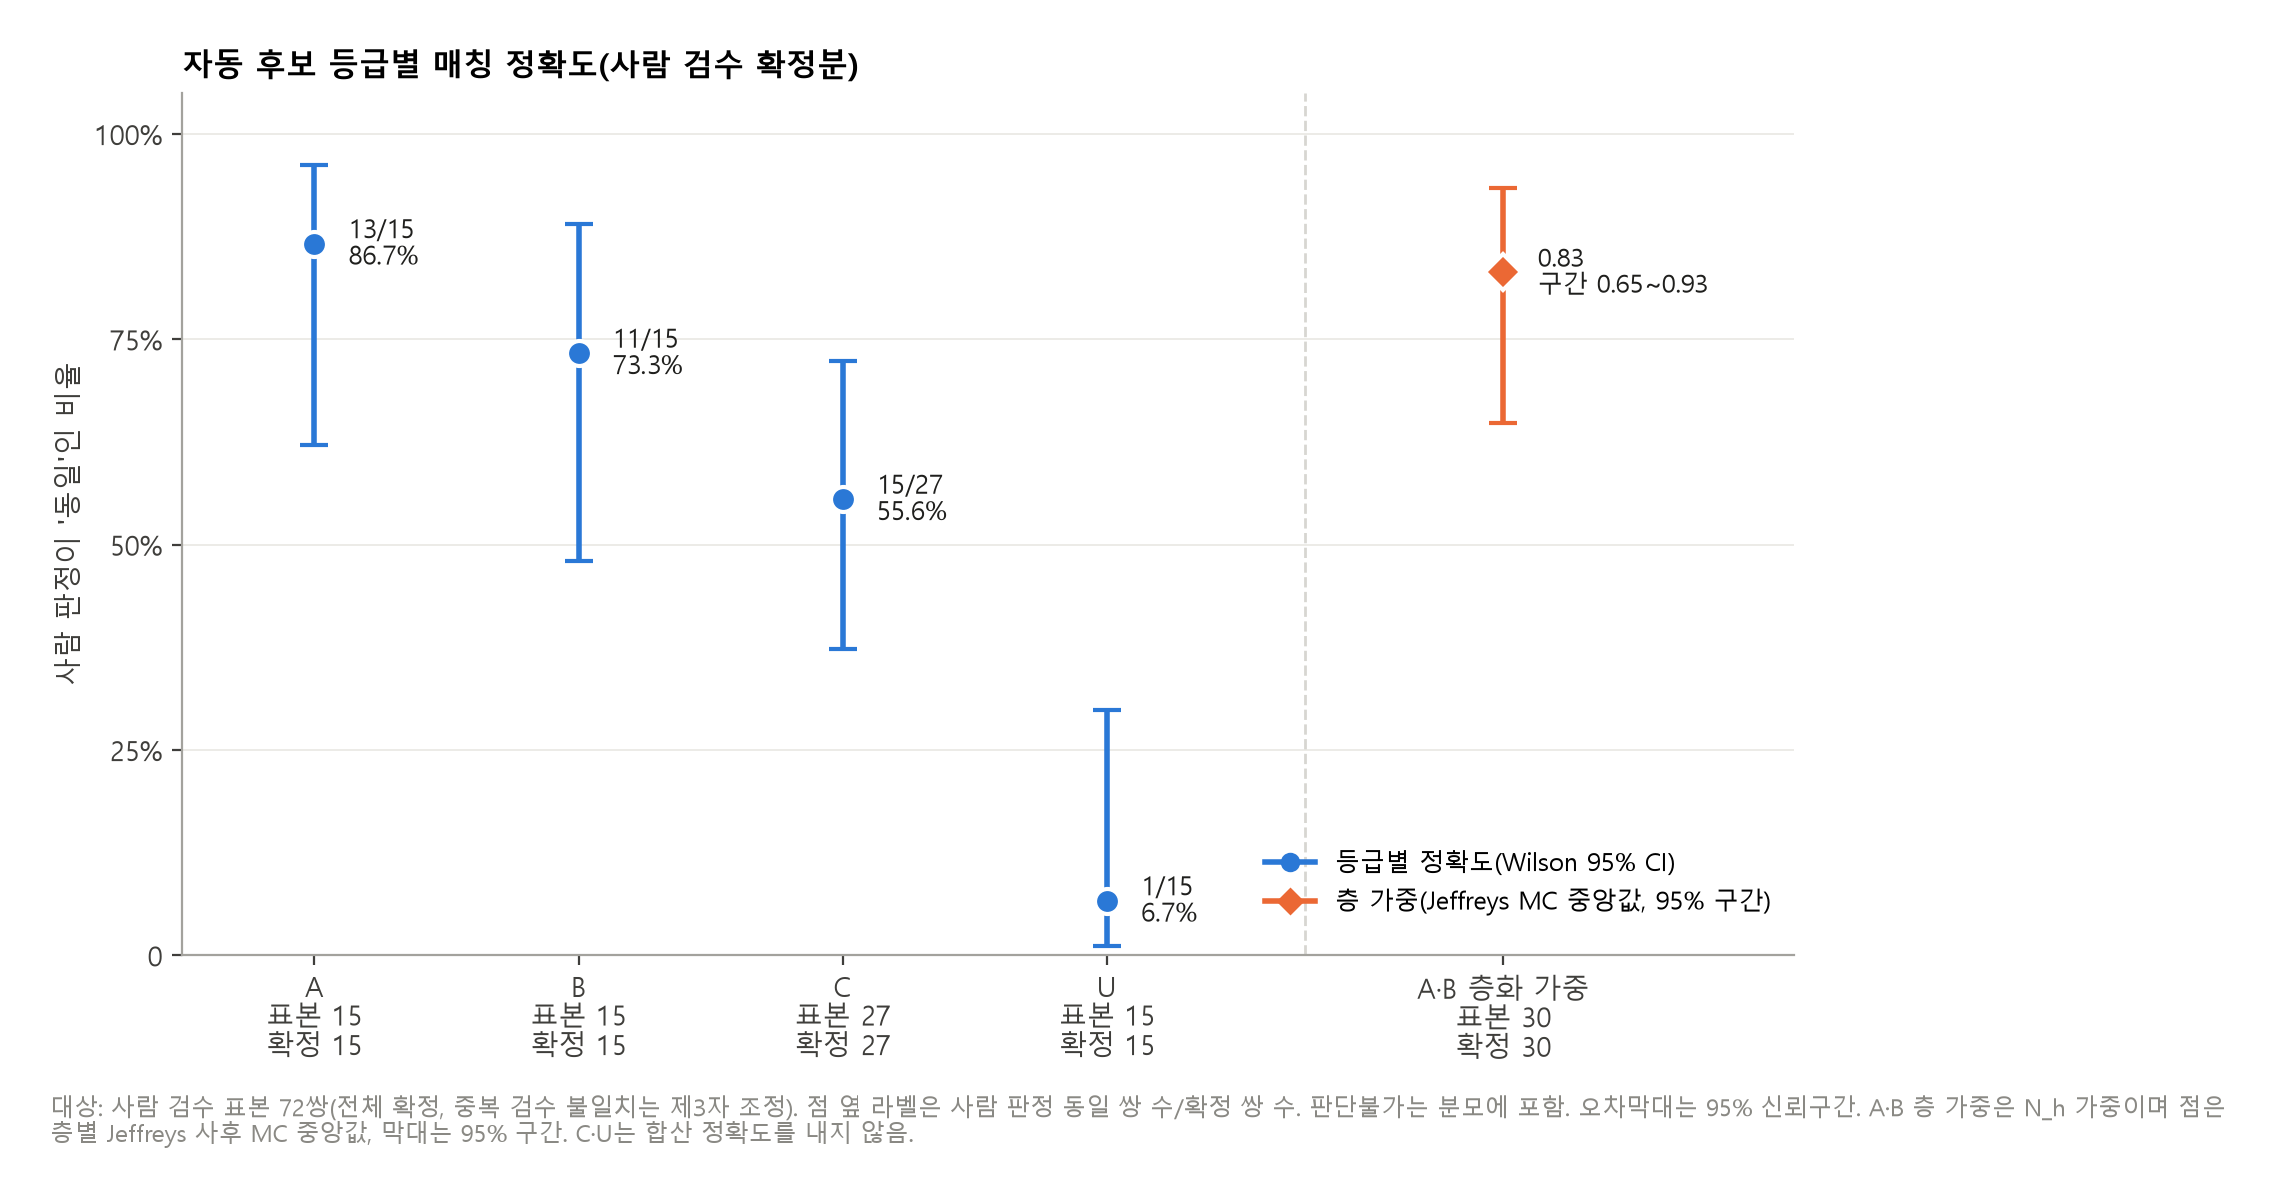

WindowsPath('outputs/04_q2/figures/final/01_match_accuracy_by_tier.png')

In [22]:
ma = FT["match_accuracy"]
disp(ma[ma.tier.ne("AB_weighted")], "표 H-3a. 등급별 자동 후보 정확도(사람 확정분)", drop=["note", "method"],
     note="acc = n_same / n_confirmed. 신뢰구간은 Wilson 95%. C, U는 합쳐 전체 정확도를 내지 않음.")
wst = ST["supp_weighted_accuracy_ci"]
wj = wst[wst.key.eq("AB_weighted")].iloc[0]
disp(wst[wst.key.eq("AB_weighted")][["key", "estimate_definition", "estimate", "ci_low", "ci_high", "ci_method", "estimate_plugin", "n_confirmed"]],
     "표 H-3b. A·B 층 가중 정확도", note="estimate = 층별 Jeffreys 사후 MC 중앙값, estimate_plugin = 단순 층 가중값. 기존 정규근사 비교 값은 H-8-S5 표(old_normal_*).")
maI = ma.set_index("tier")
fig, ax = plt.subplots(figsize=(10.4, 5.6))
XP = {"A": 0, "B": 1, "C": 2, "U": 3}
for t, x in XP.items():
    r = maI.loc[t]
    ax.errorbar(x, r.acc, yerr=[[r.acc - r.acc_ci_low], [r.acc_ci_high - r.acc]], fmt="o", color=C_MID, ms=9, capsize=5, lw=2, mec="white", mew=1.5, zorder=3)
    ax.text(x + 0.13, r.acc, f"{kn(r.n_same, r.n_confirmed)}\n{100 * r.acc:.1f}%", va="center", fontsize=9.5, color=INK)
w = maI.loc["AB_weighted"]
ax.errorbar(4.5, wj.estimate, yerr=[[wj.estimate - wj.ci_low], [wj.ci_high - wj.estimate]], fmt="D", color=C_ORANGE, ms=9, capsize=5, lw=2, mec="white", mew=1.5, zorder=3)
ax.text(4.5 + 0.13, wj.estimate, f"{wj.estimate:.2f}\n구간 {wj.ci_low:.2f}~{wj.ci_high:.2f}", va="center", fontsize=9, color=INK)
ax.axvline(3.75, color="#d7d6d1", lw=1, ls="--")
ax.set_xticks(list(XP.values()) + [4.5], [f"{t}\n표본 {int(maI.loc[t,'n_sampled'])}\n확정 {int(maI.loc[t,'n_confirmed'])}" for t in XP]
              + [f"A·B 층화 가중\n표본 {int(w.n_sampled)}\n확정 {int(w.n_confirmed)}"])
ax.set_xlim(-0.5, 5.6); ax.set_ylim(0, 1.05); ax.set_yticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
ax.set_ylabel("사람 판정이 '동일'인 비율"); ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Line2D([], [], marker="o", color=C_MID, lw=2, label="등급별 정확도(Wilson 95% CI)"),
                   plt.Line2D([], [], marker="D", color=C_ORANGE, lw=2, label="층 가중(Jeffreys MC 중앙값, 95% 구간)")], loc="lower right", bbox_to_anchor=(1.0, 0.02))
ax.set_title("자동 후보 등급별 매칭 정확도(사람 검수 확정분)")
save_fig(fig, "01_match_accuracy_by_tier", "대상: 사람 검수 표본 72쌍(전체 확정, 중복 검수 불일치는 제3자 조정). 점 옆 라벨은 사람 판정 동일 쌍 수/확정 쌍 수. 판단불가는 분모에 포함. 오차막대는 95% 신뢰구간. A·B 층 가중은 N_h 가중이며 점은 층별 Jeffreys 사후 MC 중앙값, 막대는 95% 구간. C·U는 합산 정확도를 내지 않음.", folder=FFIG)

In [23]:
def mrow(t):
    r = maI.loc[t]
    return f"{t} {kn(r.n_same, r.n_confirmed)}(95% CI {ci2(r.acc_ci_low, r.acc_ci_high)})"


assert [kn(maI.loc[t, "n_same"], maI.loc[t, "n_confirmed"]) for t in "ABCU"] == ["13/15", "11/15", "15/27", "1/15"] and round(w.acc, 2) == 0.84
OBS["match"] = "\n".join([
    "- 자동 후보와 사람 판정이 동일한 쌍: " + ", ".join(mrow(t) for t in "ABCU"),
    f"- A·B 층 가중 정확도 {wj.estimate:.2f}(Jeffreys MC 사후 중앙값, 95% 구간 {wj.ci_low:.2f}~{wj.ci_high:.2f})",
    "- 미해결 0건, 범위 불필요"])
INT["match"] = "\n".join([
    "- A, B: 사람 검수에서 대부분 동일 사업으로 판정(A 13/15, B 11/15)",
    "- C, U: 자동 후보를 동일 사업으로 쓰기 어려운 수준",
    "- 전체 합산 정확도는 내지 않음"])
nc = maI.loc[list("ABCU"), "n_confirmed"]
LIM["match"] = "\n".join([
    f"- 표본 작음(등급별 확정 {int(nc.min())}~{int(nc.max())}쌍), Wilson 구간 넓음",
    "- A, B 가중 구간은 층별 Jeffreys MC 근사, 단순 층 가중값은 H-8-S5 표에 별도 열",
    "- 자동 후보가 같은 서비스인지에 대한 값, 항목 명시성의 정확도 아님"])
md("**관찰**\n" + OBS["match"] + "\n\n**해석**\n" + INT["match"] + "\n\n**한계**\n" + LIM["match"])

**관찰**
- 자동 후보와 사람 판정이 동일한 쌍: A 13/15(95% CI 62.1~96.3%), B 11/15(95% CI 48.0~89.1%), C 15/27(95% CI 37.3~72.4%), U 1/15(95% CI 1.2~29.8%)
- A·B 층 가중 정확도 0.83(Jeffreys MC 사후 중앙값, 95% 구간 0.65~0.93)
- 미해결 0건, 범위 불필요

**해석**
- A, B: 사람 검수에서 대부분 동일 사업으로 판정(A 13/15, B 11/15)
- C, U: 자동 후보를 동일 사업으로 쓰기 어려운 수준
- 전체 합산 정확도는 내지 않음

**한계**
- 표본 작음(등급별 확정 15~27쌍), Wilson 구간 넓음
- A, B 가중 구간은 층별 Jeffreys MC 근사, 단순 층 가중값은 H-8-S5 표에 별도 열
- 자동 후보가 같은 서비스인지에 대한 값, 항목 명시성의 정확도 아님

## H-4. 규칙 정확도(사람 금표준 대비)
- 정확도: 규칙 v3.1 라벨 = 사람 확정 라벨인 비율
- 비가중: Wilson 95% CI
- 층 가중: `gold_strata.csv`의 N_h 가중, 점은 Jeffreys MC 사후 중앙값, 95% 구간
- 금표준 범위: A·B 비공유 쌍, text
- 용도: H-5, H-6 규칙 기반 명시율의 해석 기준

**표 H-4. 규칙 v3.1 정확도 — 사람 확정 라벨 대비**

item,side,core_metric,n_units,n_confirmed,n_unresolved,n_correct,acc,weighted_acc,n_strata,n_strata_without_confirmed,acc_ci_low,acc_ci_high
age,ssis,True,9,9,0,6,0.667,0.812,3,0,0.354,0.879
age,gov,True,9,9,0,5,0.556,0.543,3,0,0.267,0.811
age,all,True,18,18,0,11,0.611,0.677,6,0,0.386,0.797
income,ssis,True,9,9,0,6,0.667,0.782,3,0,0.354,0.879
income,gov,True,9,9,0,6,0.667,0.767,3,0,0.354,0.879
income,all,True,18,18,0,12,0.667,0.774,6,0,0.437,0.837
residence,ssis,False,9,9,0,6,0.667,0.932,3,0,0.354,0.879
residence,gov,False,9,9,0,5,0.556,0.782,3,0,0.267,0.811
residence,all,False,18,18,0,11,0.611,0.857,6,0,0.386,0.797
channel,ssis,True,9,9,0,7,0.778,0.962,3,0,0.453,0.937


<span style='color:#8a8984;font-size:90%'>acc = n_correct / n_confirmed(비가중, Wilson 95% CI). weighted_acc는 단순 층 N_h 가중값. 그림과 H-8-S5는 Jeffreys MC 중앙값과 95% 구간. side=all은 양쪽 합산. 거주는 핵심 지표 아님.</span>

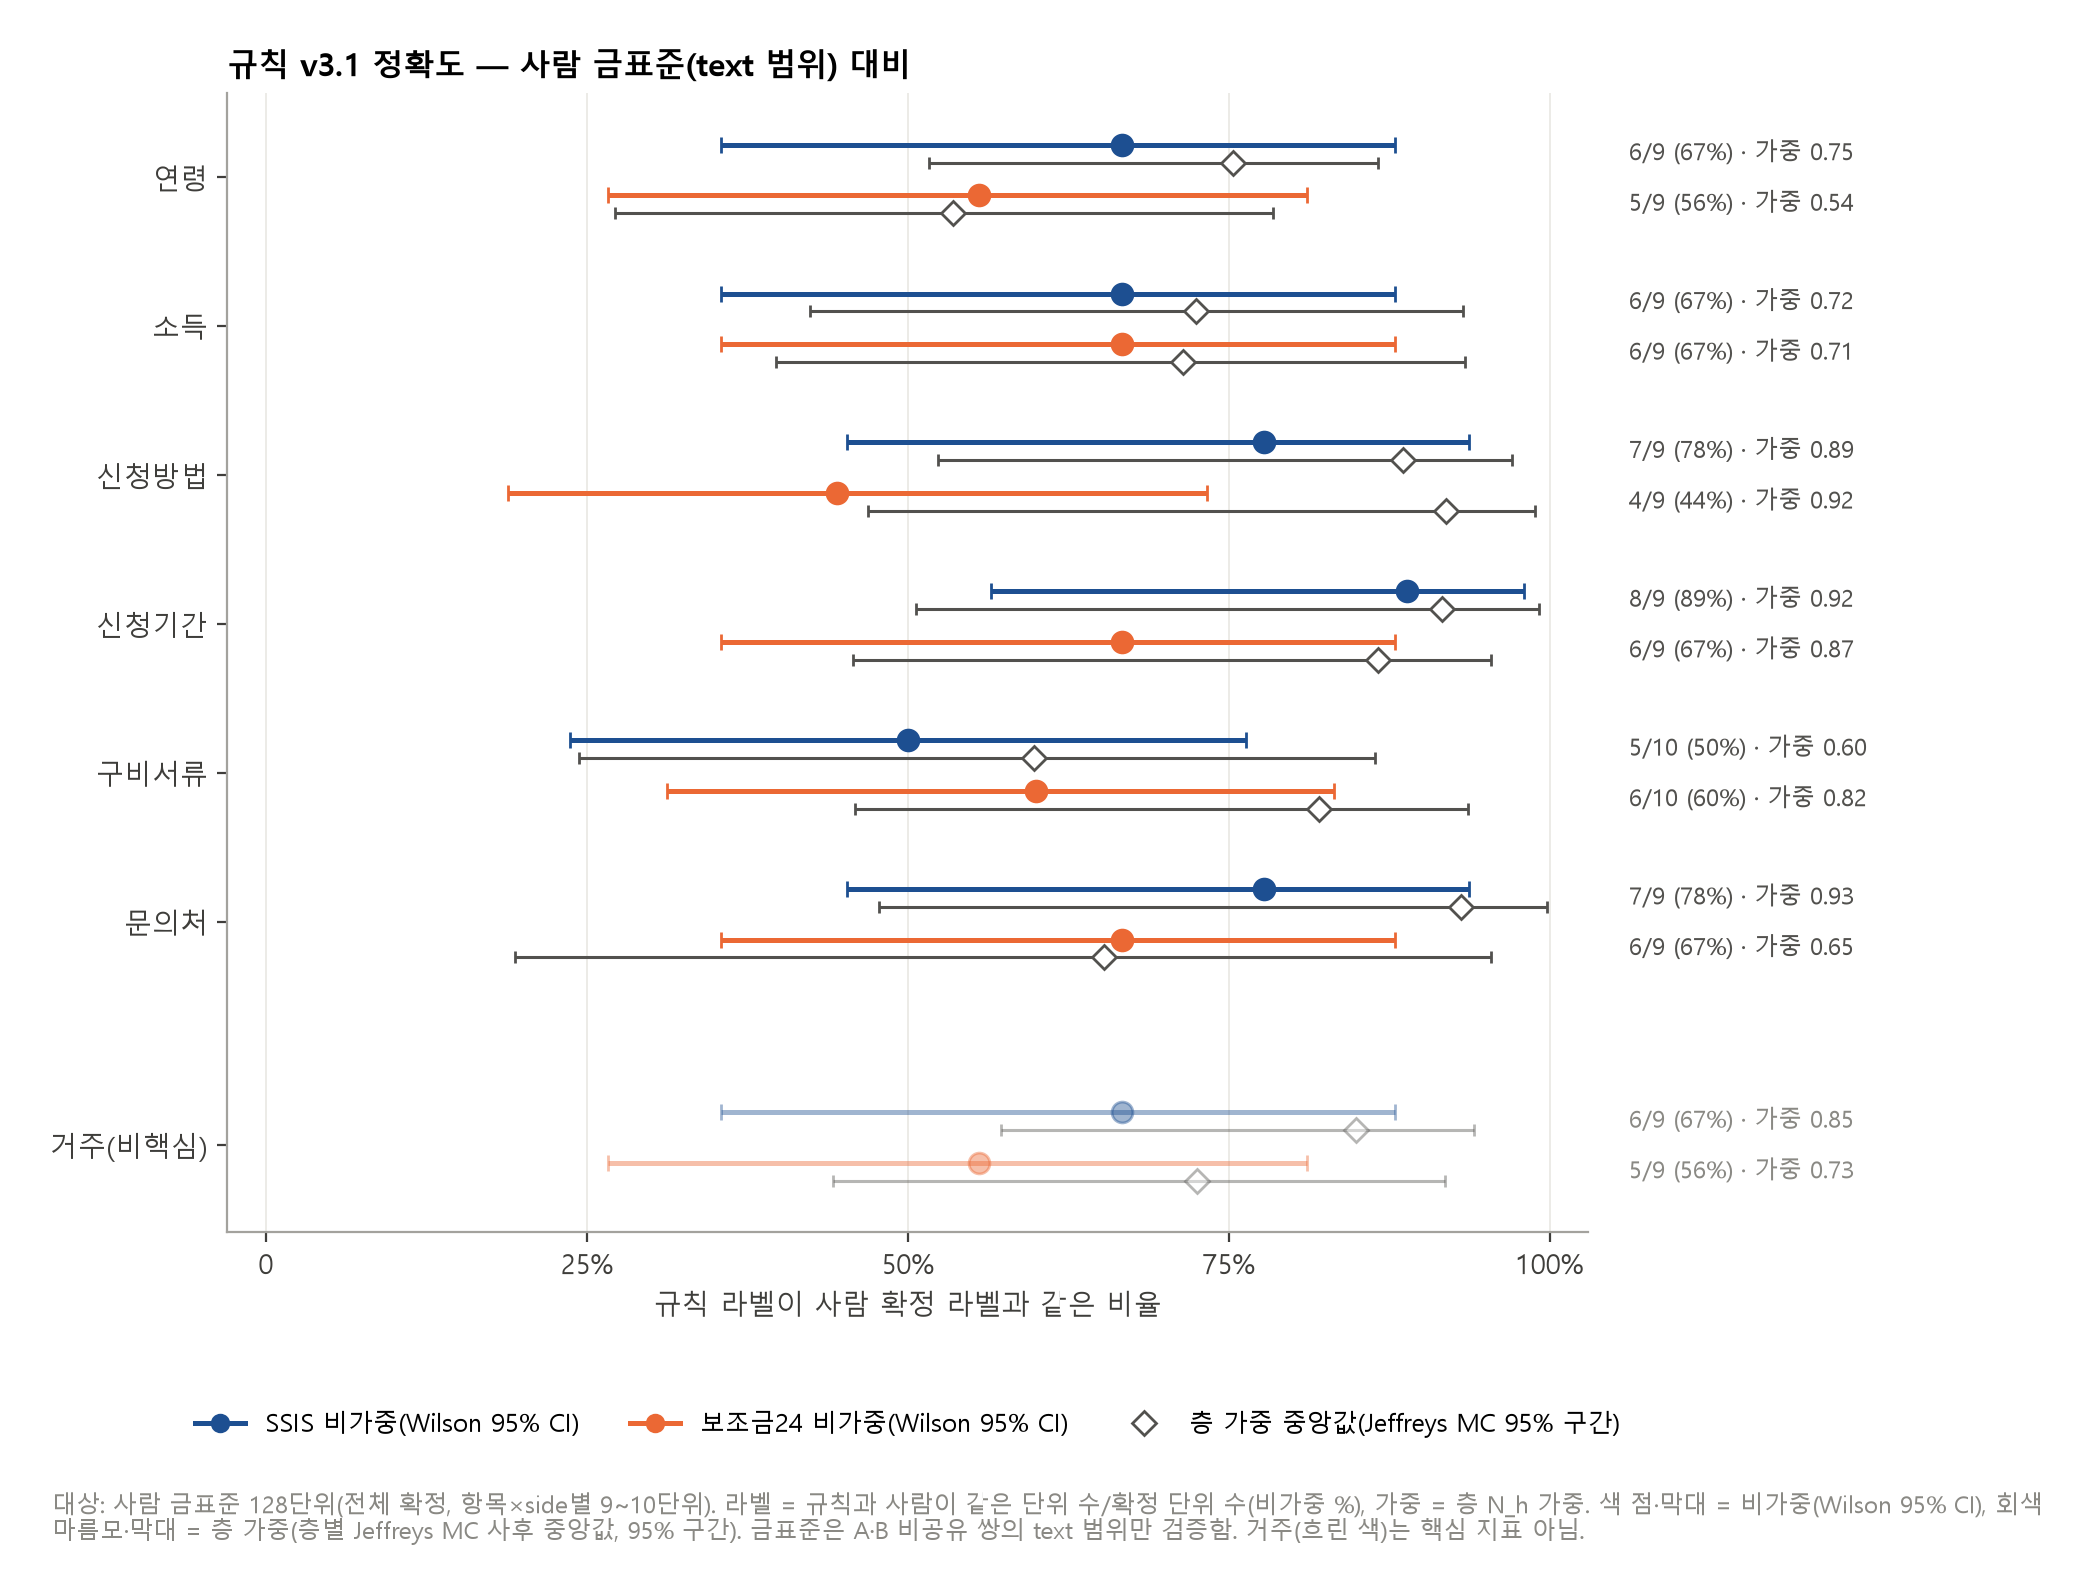

WindowsPath('outputs/04_q2/figures/final/04_rule_accuracy_vs_gold.png')

In [24]:
ra = FT["item_rule_accuracy"]
disp(ra, "표 H-4. 규칙 v3.1 정확도 — 사람 확정 라벨 대비", drop=["note"],
     note="acc = n_correct / n_confirmed(비가중, Wilson 95% CI). weighted_acc는 단순 층 N_h 가중값. 그림과 H-8-S5는 Jeffreys MC 중앙값과 95% 구간. side=all은 양쪽 합산. 거주는 핵심 지표 아님.")
ra_s = ra[ra.side.isin(["ssis", "gov"])]
wI = wst[wst.table.eq("item") & wst.estimate_type.eq("층 가중")].set_index(["key", "side"])
fig, ax = plt.subplots(figsize=(12.6, 7.4))
fig.subplots_adjust(right=0.66, left=0.12)
YP = {it: (k if it != "residence" else 6.5) for k, it in enumerate(ORDER_ALL)}
OFF = {"ssis": -0.17, "gov": 0.17}
for it in ORDER_ALL:
    for side in ["ssis", "gov"]:
        r = ra_s[(ra_s.item == it) & (ra_s.side == side)].iloc[0]
        yy, a = YP[it] + OFF[side], (1 if it != "residence" else 0.42)
        ax.errorbar(r.acc, yy - 0.05, xerr=[[r.acc - r.acc_ci_low], [r.acc_ci_high - r.acc]], fmt="o", color=SC[side], alpha=a, ms=7.5, capsize=3, lw=1.8, zorder=3)
        q = wI.loc[(it, side)]
        ax.errorbar(q.estimate, yy + 0.07, xerr=[[q.estimate - q.ci_low], [q.ci_high - q.estimate]], fmt="D", color=INK2, mfc="white", alpha=a, ms=6, capsize=2, lw=1.1, ls="none", zorder=4)
        ax.annotate(f"{kn(r.n_correct, r.n_confirmed)} ({100 * r.acc:.0f}%) · 가중 {q.estimate:.2f}", xy=(1.03, yy), xycoords=("axes fraction", "data"), va="center", fontsize=8.5,
                    color=INK2 if it != "residence" else MUTED, annotation_clip=False)
ax.set_xlim(-0.03, 1.03); ax.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
ax.set_yticks(list(YP.values()), [KO[i] if i != "residence" else "거주(비핵심)" for i in ORDER_ALL]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("규칙 라벨이 사람 확정 라벨과 같은 비율")
ax.legend(handles=[plt.Line2D([], [], marker="o", color=C_DARK, lw=1.8, label="SSIS 비가중(Wilson 95% CI)"), plt.Line2D([], [], marker="o", color=C_ORANGE, lw=1.8, label="보조금24 비가중(Wilson 95% CI)"),
                   plt.Line2D([], [], marker="D", color=INK2, mfc="white", lw=0, label="층 가중 중앙값(Jeffreys MC 95% 구간)")], loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.set_title("규칙 v3.1 정확도 — 사람 금표준(text 범위) 대비")
save_fig(fig, "04_rule_accuracy_vs_gold", "대상: 사람 금표준 128단위(전체 확정, 항목×side별 9~10단위). 라벨 = 규칙과 사람이 같은 단위 수/확정 단위 수(비가중 %), 가중 = 층 N_h 가중. 색 점·막대 = 비가중(Wilson 95% CI), 회색 마름모·막대 = 층 가중(층별 Jeffreys MC 사후 중앙값, 95% 구간). 금표준은 A·B 비공유 쌍의 text 범위만 검증함. 거주(흐린 색)는 핵심 지표 아님.", folder=FFIG)

In [25]:
ra_all = ra[ra.side.eq("all") & ra.core_metric]
rs = ra_s[ra_s.core_metric]
assert (round(ra_all.acc.min(), 2), round(ra_all.acc.max(), 2), round(ra_all.weighted_acc.min(), 2), round(ra_all.weighted_acc.max(), 2)) == (0.55, 0.78, 0.68, 0.97)
wmed = wI.loc[[(i, "all") for i in ORDER_I]].estimate
RA_TXT = (f"비가중 {ra_all.acc.min():.2f}~{ra_all.acc.max():.2f}(양쪽 합산, 확정 {int(ra_all.n_confirmed.min())}~{int(ra_all.n_confirmed.max())}단위), "
          f"층 가중(Jeffreys MC 중앙값) {wmed.min():.2f}~{wmed.max():.2f}")
OBS["rule"] = "\n".join([
    f"- 핵심 6항목, v3.1 규칙 라벨 = 사람 확정 라벨 비율: {RA_TXT}",
    f"- 항목×side별 비가중 정확도 {rs.acc.min():.2f}~{rs.acc.max():.2f}(확정 {int(rs.n_confirmed.min())}~{int(rs.n_confirmed.max())}단위)",
    "- 거주는 핵심 지표가 아니어서 범위에서 제외"])
INT["rule"] = "\n".join([
    "- 규칙 라벨 정확도는 항목별 차이 큼",
    "- 층 가중값 = 층별 단위 수(N_h) 가중, 비가중값 = 표본 그대로",
    "- 두 값의 차이 = 층마다 정확도가 다름",
    "- H-5, H-6의 규칙 기반 명시율은 이 오분류 범위와 함께 해석"])
LIM["rule"] = "\n".join([
    "- 금표준 = A·B 비공유 쌍의 text 범위 표본",
    "- all 범위, C 등급 쌍은 사람 검증 없음",
    f"- 항목×side별 확정 단위 {int(rs.n_confirmed.min())}~{int(rs.n_confirmed.max())}개, Wilson 구간 넓음",
    f"- 가중 정확도는 층별 Jeffreys MC 근사 구간(그림, H-8-S5), 단순 층 가중값은 표 weighted_acc, 확정 단위가 없는 층 {int(ra.n_strata_without_confirmed.sum())}개"])
md("**관찰**\n" + OBS["rule"] + "\n\n**해석**\n" + INT["rule"] + "\n\n**한계**\n" + LIM["rule"])

**관찰**
- 핵심 6항목, v3.1 규칙 라벨 = 사람 확정 라벨 비율: 비가중 0.55~0.78(양쪽 합산, 확정 18~20단위), 층 가중(Jeffreys MC 중앙값) 0.64~0.88
- 항목×side별 비가중 정확도 0.44~0.89(확정 9~10단위)
- 거주는 핵심 지표가 아니어서 범위에서 제외

**해석**
- 규칙 라벨 정확도는 항목별 차이 큼
- 층 가중값 = 층별 단위 수(N_h) 가중, 비가중값 = 표본 그대로
- 두 값의 차이 = 층마다 정확도가 다름
- H-5, H-6의 규칙 기반 명시율은 이 오분류 범위와 함께 해석

**한계**
- 금표준 = A·B 비공유 쌍의 text 범위 표본
- all 범위, C 등급 쌍은 사람 검증 없음
- 항목×side별 확정 단위 9~10개, Wilson 구간 넓음
- 가중 정확도는 층별 Jeffreys MC 근사 구간(그림, H-8-S5), 단순 층 가중값은 표 weighted_acc, 확정 단위가 없는 층 0개

### Decision Box 10 — 대응표본 검정
- **문제:** 같은 쌍의 두 플랫폼 비교라 독립표본 아님
- **선택:** 정확 McNemar, Newcombe 방법 10 구간, Holm 보정(핵심 6항목 × 2범위 = 12검정)
- **근거:** 비교 플랫폼 2개라 Cochran's Q 불필요
- **한계:** 자동 후보 쌍에 동일 사업이 아닌 쌍 포함 가능(H-3)

## H-5. 플랫폼별 명시율과 대응 비교
- 명시율: 명시 / (명시 + 부분 + 미명시), Wilson 95% CI
- 대응 비교: 두 플랫폼 모두 수준 라벨이 있는 쌍
- b: 보조금24만 명시, c: SSIS만 명시
- 차이: 보조금24 − SSIS

**표 H-5a. 항목×플랫폼 명시율 — text, 규칙 v3.1, 자동 후보 A·B 비공유 쌍**

item,side,core_metric,n_units,n_explicit,n_denominator,share_explicit,n_unresolved,share_ci_low,share_ci_high
age,ssis,True,1252,606,1252,0.484,0,0.456,0.512
age,gov,True,1252,562,1252,0.449,0,0.422,0.477
income,ssis,True,1252,501,1252,0.400,0,0.373,0.428
income,gov,True,1252,439,1252,0.351,0,0.325,0.377
residence,ssis,False,1252,681,1252,0.544,0,0.516,0.571
residence,gov,False,1252,600,1252,0.479,0,0.452,0.507
channel,ssis,True,1252,983,1252,0.785,0,0.762,0.807
channel,gov,True,1252,1224,1252,0.978,0,0.968,0.984
period,ssis,True,1252,152,1216,0.125,0,0.108,0.145
period,gov,True,1252,86,1142,0.075,0,0.061,0.092


<span style='color:#8a8984;font-size:90%'>규칙 기반 추정(v3.1). 분모 = 명시+부분+미명시. n_unresolved는 해당 항목 금표준의 미해결 단위 수(0건)이며 이 분모에는 관여하지 않음. all 범위는 CSV.</span>

**표 H-5b. 대응 비교(정확 McNemar, Newcombe 95% CI, Holm family 12)**

scope,item,core_metric,n_pairs,n_both_explicit,b_gov_only,c_ssis_only,n_both_not,p_ssis,p_gov,diff,diff_ci_low,diff_ci_high,mcnemar_p,n_unresolved,holm_p
text,age,True,1252,511,51,95,595,0.484,0.449,-0.035,-0.054,-0.016,0.000339,0,0.000679
text,income,True,1252,401,38,100,713,0.400,0.351,-0.050,-0.068,-0.031,1.29e-07,0,9.02e-07
text,residence,False,1252,528,72,153,499,0.544,0.479,-0.065,-0.088,-0.041,7.04e-08,0,—
text,channel,True,1252,966,258,17,11,0.785,0.978,0.192,0.169,0.217,1.76e-56,0,1.76e-55
text,period,True,1125,18,67,133,907,0.134,0.076,-0.059,-0.083,-0.034,3.55e-06,0,1.77e-05
text,documents,True,1125,59,121,243,702,0.268,0.160,-0.108,-0.141,-0.076,1.54e-10,0,1.23e-09
text,contact,True,1252,7,32,6,1207,0.010,0.031,0.021,0.011,0.032,2.43e-05,0,7.3e-05
all,age,True,1252,511,51,95,595,0.484,0.449,-0.035,-0.054,-0.016,0.000339,0,0.000679
all,income,True,1252,401,38,100,713,0.400,0.351,-0.050,-0.068,-0.031,1.29e-07,0,9.02e-07
all,residence,False,1252,528,72,153,499,0.544,0.479,-0.065,-0.088,-0.041,7.04e-08,0,—


<span style='color:#8a8984;font-size:90%'>차이 = 보조금24 − SSIS. b_gov_only = 보조금24만 명시한 쌍, c_ssis_only = SSIS만 명시한 쌍. Holm은 핵심 6항목 × 2범위. 거주는 family 제외.</span>

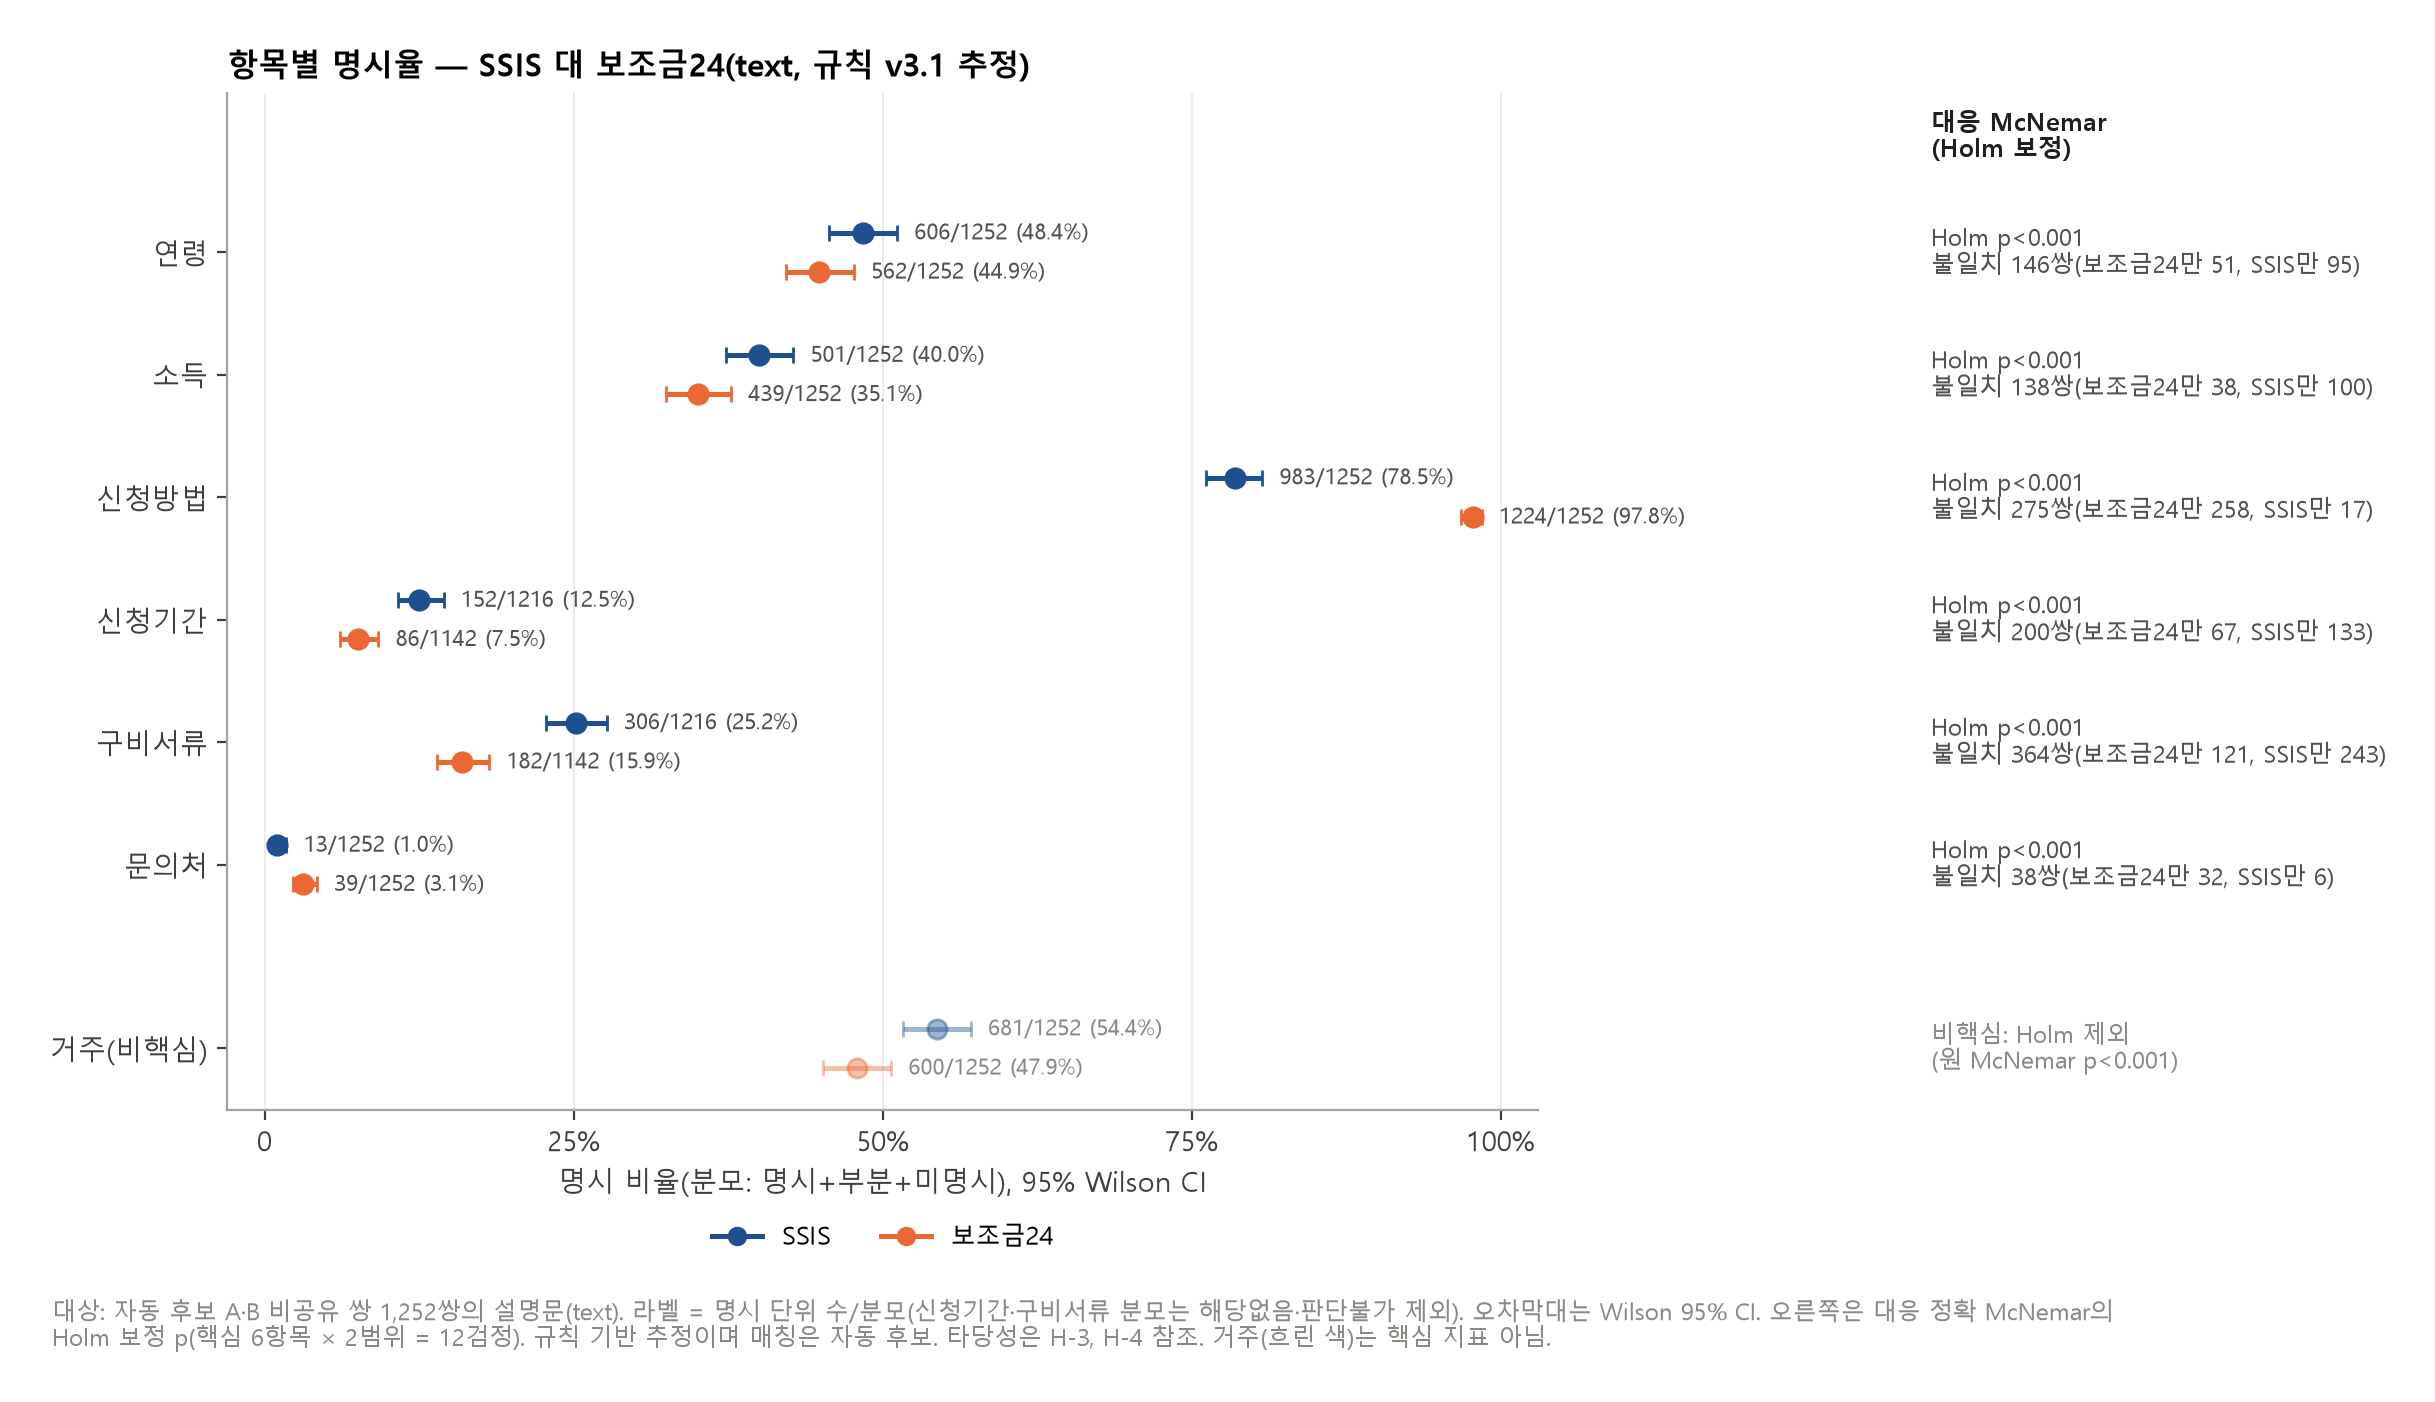

WindowsPath('outputs/04_q2/figures/final/02_explicitness_by_platform_text.png')

In [26]:
ex, pt = FT["explicitness_by_platform"], FT["platform_paired_tests"]
ex_t = ex[ex.scope.eq("text")]
disp(ex_t, "표 H-5a. 항목×플랫폼 명시율 — text, 규칙 v3.1, 자동 후보 A·B 비공유 쌍", drop=["note", "label", "scope"],
     note="규칙 기반 추정(v3.1). 분모 = 명시+부분+미명시. n_unresolved는 해당 항목 금표준의 미해결 단위 수(0건)이며 이 분모에는 관여하지 않음. all 범위는 CSV.")
disp(pt, "표 H-5b. 대응 비교(정확 McNemar, Newcombe 95% CI, Holm family 12)", drop=["note", "test_note", "holm_family"],
     note="차이 = 보조금24 − SSIS. b_gov_only = 보조금24만 명시한 쌍, c_ssis_only = SSIS만 명시한 쌍. Holm은 핵심 6항목 × 2범위. 거주는 family 제외.")
fig, ax = plt.subplots(figsize=(12.6, 6.6))
fig.subplots_adjust(right=0.62, left=0.1)
YP = {it: (k if it != "residence" else 6.5) for k, it in enumerate(ORDER_ALL)}
OFF = {"ssis": -0.16, "gov": 0.16}
ptt = pt[pt.scope.eq("text")].set_index("item")
for it in ORDER_ALL:
    core = it != "residence"
    for side in ["ssis", "gov"]:
        r = ex_t[(ex_t.item == it) & (ex_t.side == side)].iloc[0]
        yy, a = YP[it] + OFF[side], (1 if core else 0.42)
        ax.errorbar(r.share_explicit, yy, xerr=[[r.share_explicit - r.share_ci_low], [r.share_ci_high - r.share_explicit]], fmt="o", color=SC[side], alpha=a, ms=7, capsize=3, lw=1.8, zorder=3)
        ax.text(r.share_ci_high + 0.014, yy, f"{kn(r.n_explicit, r.n_denominator)} ({100 * r.share_explicit:.1f}%)", va="center", fontsize=8, color=INK2 if core else MUTED)
    p = ptt.loc[it]
    txt = (f"Holm {fmt_p(p.holm_p)}\n불일치 {int(p.b_gov_only) + int(p.c_ssis_only)}쌍(보조금24만 {int(p.b_gov_only)}, SSIS만 {int(p.c_ssis_only)})" if core
           else f"비핵심: Holm 제외\n(원 McNemar {fmt_p(p.mcnemar_p)})")
    ax.annotate(txt, xy=(1.3, YP[it]), xycoords=("axes fraction", "data"), va="center", fontsize=8.5, color=INK2 if core else MUTED, annotation_clip=False)
ax.annotate("대응 McNemar\n(Holm 보정)", xy=(1.3, -0.95), xycoords=("axes fraction", "data"), va="center", fontsize=9, color=INK, fontweight="bold", annotation_clip=False)
ax.set_xlim(-0.03, 1.03); ax.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
ax.set_yticks(list(YP.values()), [KO[i] if i != "residence" else "거주(비핵심)" for i in ORDER_ALL]); ax.set_ylim(7.0, -1.3); ax.grid(axis="y", visible=False)
ax.set_xlabel("명시 비율(분모: 명시+부분+미명시), 95% Wilson CI")
ax.legend(handles=[plt.Line2D([], [], marker="o", color=C_DARK, lw=1.8, label="SSIS"), plt.Line2D([], [], marker="o", color=C_ORANGE, lw=1.8, label="보조금24")], loc="lower center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title("항목별 명시율 — SSIS 대 보조금24(text, 규칙 v3.1 추정)")
save_fig(fig, "02_explicitness_by_platform_text", "대상: 자동 후보 A·B 비공유 쌍 1,252쌍의 설명문(text). 라벨 = 명시 단위 수/분모(신청기간·구비서류 분모는 해당없음·판단불가 제외). 오차막대는 Wilson 95% CI. 오른쪽은 대응 정확 McNemar의 Holm 보정 p(핵심 6항목 × 2범위 = 12검정). 규칙 기반 추정이며 매칭은 자동 후보. 타당성은 H-3, H-4 참조. 거주(흐린 색)는 핵심 지표 아님.", folder=FFIG)

In [27]:
ptc = pt[pt.scope.eq("text") & pt.core_metric].set_index("item")
exs = ex_t.set_index(["item", "side"])
hi_ssis = [KO[i] for i in ORDER_I if ptc.loc[i, "diff"] < 0]
hi_gov = [KO[i] for i in ORDER_I if ptc.loc[i, "diff"] > 0]
assert hi_ssis == ["연령", "소득", "신청기간", "구비서류"] and hi_gov == ["신청방법", "문의처"]
assert (ptc.holm_p < 0.001).all()
n_pairs_all = int(ex_t.n_units.max())
OBS["expl"] = "\n".join(
    [f"- 규칙 v3.1, 자동 후보 A·B 비공유 {n_pairs_all:,}쌍, 설명문(text) 명시율(SSIS 대 보조금24)"]
    + [f"  - {KO[i]}: {kn(exs.loc[(i,'ssis'),'n_explicit'], exs.loc[(i,'ssis'),'n_denominator'])}({ci2(exs.loc[(i,'ssis'),'share_ci_low'], exs.loc[(i,'ssis'),'share_ci_high'])}) 대 "
       f"{kn(exs.loc[(i,'gov'),'n_explicit'], exs.loc[(i,'gov'),'n_denominator'])}({ci2(exs.loc[(i,'gov'),'share_ci_low'], exs.loc[(i,'gov'),'share_ci_high'])})" for i in ORDER_I]
    + [f"- SSIS가 높은 항목: {', '.join(hi_ssis)}",
       f"- 보조금24가 높은 항목: {', '.join(hi_gov)}",
       "- 보조금24 − SSIS 차이(%p, Newcombe 95% CI): "
       + ", ".join(f"{KO[i]} {100*ptc.loc[i,'diff']:+.1f}({100*ptc.loc[i,'diff_ci_low']:+.1f}~{100*ptc.loc[i,'diff_ci_high']:+.1f})" for i in ORDER_I),
       f"- 대응 McNemar Holm 보정 p: 핵심 6항목 모두 0.001 미만(최대 {ptc.holm_p.max():.1e})"])
INT["expl"] = "\n".join([
    "- 규칙 라벨의 추정치",
    f"- 사람 금표준 대비 규칙 정확도: {RA_TXT}, 항목별 차이 큼",
    "- 명시율 차이의 크기는 규칙 오분류 범위와 함께 해석"])
LIM["expl"] = "\n".join([
    "- 대응표본 검정은 같은 쌍의 두 플랫폼 단위를 짝으로 봄",
    f"- 자동 후보 A·B 쌍에 같은 사업이 아닌 쌍 포함 가능: A 확정 {int(maI.loc['A','n_confirmed'])}쌍 중 다름 {int(maI.loc['A','n_diff'])}, B 확정 {int(maI.loc['B','n_confirmed'])}쌍 중 다름 {int(maI.loc['B','n_diff'])}, 판단불가 {int(maI.loc['B','n_undecidable'])}",
    f"- 신청기간, 구비서류는 해당없음, 판단불가를 뺀 {int(ptc.loc['period','n_pairs']):,}쌍만 비교",
    f"- 규칙 정확도 검증은 A·B 비공유, text 범위 표본(항목×side {int(rs.n_confirmed.min())}~{int(rs.n_confirmed.max())}단위)에 한정"])
md("**관찰**\n" + OBS["expl"] + "\n\n**해석**\n" + INT["expl"] + "\n\n**한계**\n" + LIM["expl"])

**관찰**
- 규칙 v3.1, 자동 후보 A·B 비공유 1,252쌍, 설명문(text) 명시율(SSIS 대 보조금24)
  - 연령: 606/1252(45.6~51.2%) 대 562/1252(42.2~47.7%)
  - 소득: 501/1252(37.3~42.8%) 대 439/1252(32.5~37.7%)
  - 신청방법: 983/1252(76.2~80.7%) 대 1224/1252(96.8~98.4%)
  - 신청기간: 152/1216(10.8~14.5%) 대 86/1142(6.1~9.2%)
  - 구비서류: 306/1216(22.8~27.7%) 대 182/1142(13.9~18.2%)
  - 문의처: 13/1252(0.6~1.8%) 대 39/1252(2.3~4.2%)
- SSIS가 높은 항목: 연령, 소득, 신청기간, 구비서류
- 보조금24가 높은 항목: 신청방법, 문의처
- 보조금24 − SSIS 차이(%p, Newcombe 95% CI): 연령 -3.5(-5.4~-1.6), 소득 -5.0(-6.8~-3.1), 신청방법 +19.2(+16.9~+21.7), 신청기간 -5.9(-8.3~-3.4), 구비서류 -10.8(-14.1~-7.6), 문의처 +2.1(+1.1~+3.2)
- 대응 McNemar Holm 보정 p: 핵심 6항목 모두 0.001 미만(최대 6.8e-04)

**해석**
- 규칙 라벨의 추정치
- 사람 금표준 대비 규칙 정확도: 비가중 0.55~0.78(양쪽 합산, 확정 18~20단위), 층 가중(Jeffreys MC 중앙값) 0.64~0.88, 항목별 차이 큼
- 명시율 차이의 크기는 규칙 오분류 범위와 함께 해석

**한계**
- 대응표본 검정은 같은 쌍의 두 플랫폼 단위를 짝으로 봄
- 자동 후보 A·B 쌍에 같은 사업이 아닌 쌍 포함 가능: A 확정 15쌍 중 다름 1, B 확정 15쌍 중 다름 3, 판단불가 1
- 신청기간, 구비서류는 해당없음, 판단불가를 뺀 1,125쌍만 비교
- 규칙 정확도 검증은 A·B 비공유, text 범위 표본(항목×side 9~10단위)에 한정

## H-6. text 대 all
- 비교: 같은 단위의 설명문(text) 판정과 구조화 필드 포함(all) 판정
- `added_by_all`: text 비명시 → all 명시 비율
- `lost_in_all`: text 명시 → all 비명시 비율
- 검정: 정확 McNemar, Holm(핵심 6항목 × 2 side = 12검정)

**표 H-6. text 대 all — 항목×side(규칙 v3.1, 자동 후보 A·B 비공유 쌍)**

item,side,core_metric,n,k_text,k_all,share_text,share_all,k_added_by_all,added_by_all,k_lost_in_all,lost_in_all,mcnemar_p,n_unresolved,added_ci_low,added_ci_high,holm_p
age,ssis,True,1252,606,606,0.484,0.484,0,0.000,0,0.000,1,0,0.000,0.003,1
age,gov,True,1252,562,562,0.449,0.449,0,0.000,0,0.000,1,0,0.000,0.003,1
income,ssis,True,1252,501,501,0.400,0.400,0,0.000,0,0.000,1,0,0.000,0.003,1
income,gov,True,1252,439,439,0.351,0.351,0,0.000,0,0.000,1,0,0.000,0.003,1
residence,ssis,False,1252,681,681,0.544,0.544,0,0.000,0,0.000,1,0,0.000,0.003,—
residence,gov,False,1252,600,600,0.479,0.479,0,0.000,0,0.000,1,0,0.000,0.003,—
channel,ssis,True,1252,983,1103,0.785,0.881,120,0.096,0,0.000,1.5e-36,0,0.081,0.113,1.2e-35
channel,gov,True,1252,1224,1248,0.978,0.997,24,0.019,0,0.000,1.19e-07,0,0.013,0.028,8.34e-07
period,ssis,True,1216,152,152,0.125,0.125,0,0.000,0,0.000,1,0,0.000,0.003,1
period,gov,True,1124,86,1044,0.077,0.929,958,0.852,0,0.000,8.21e-289,0,0.830,0.872,8.21e-288


<span style='color:#8a8984;font-size:90%'>added_by_all = text 비명시이고 all 명시인 단위 / n. 신뢰구간(added_ci_*)은 Wilson 95%. 사람 금표준은 text 범위만 검증했으므로 all 수치는 사람 검증 밖.</span>

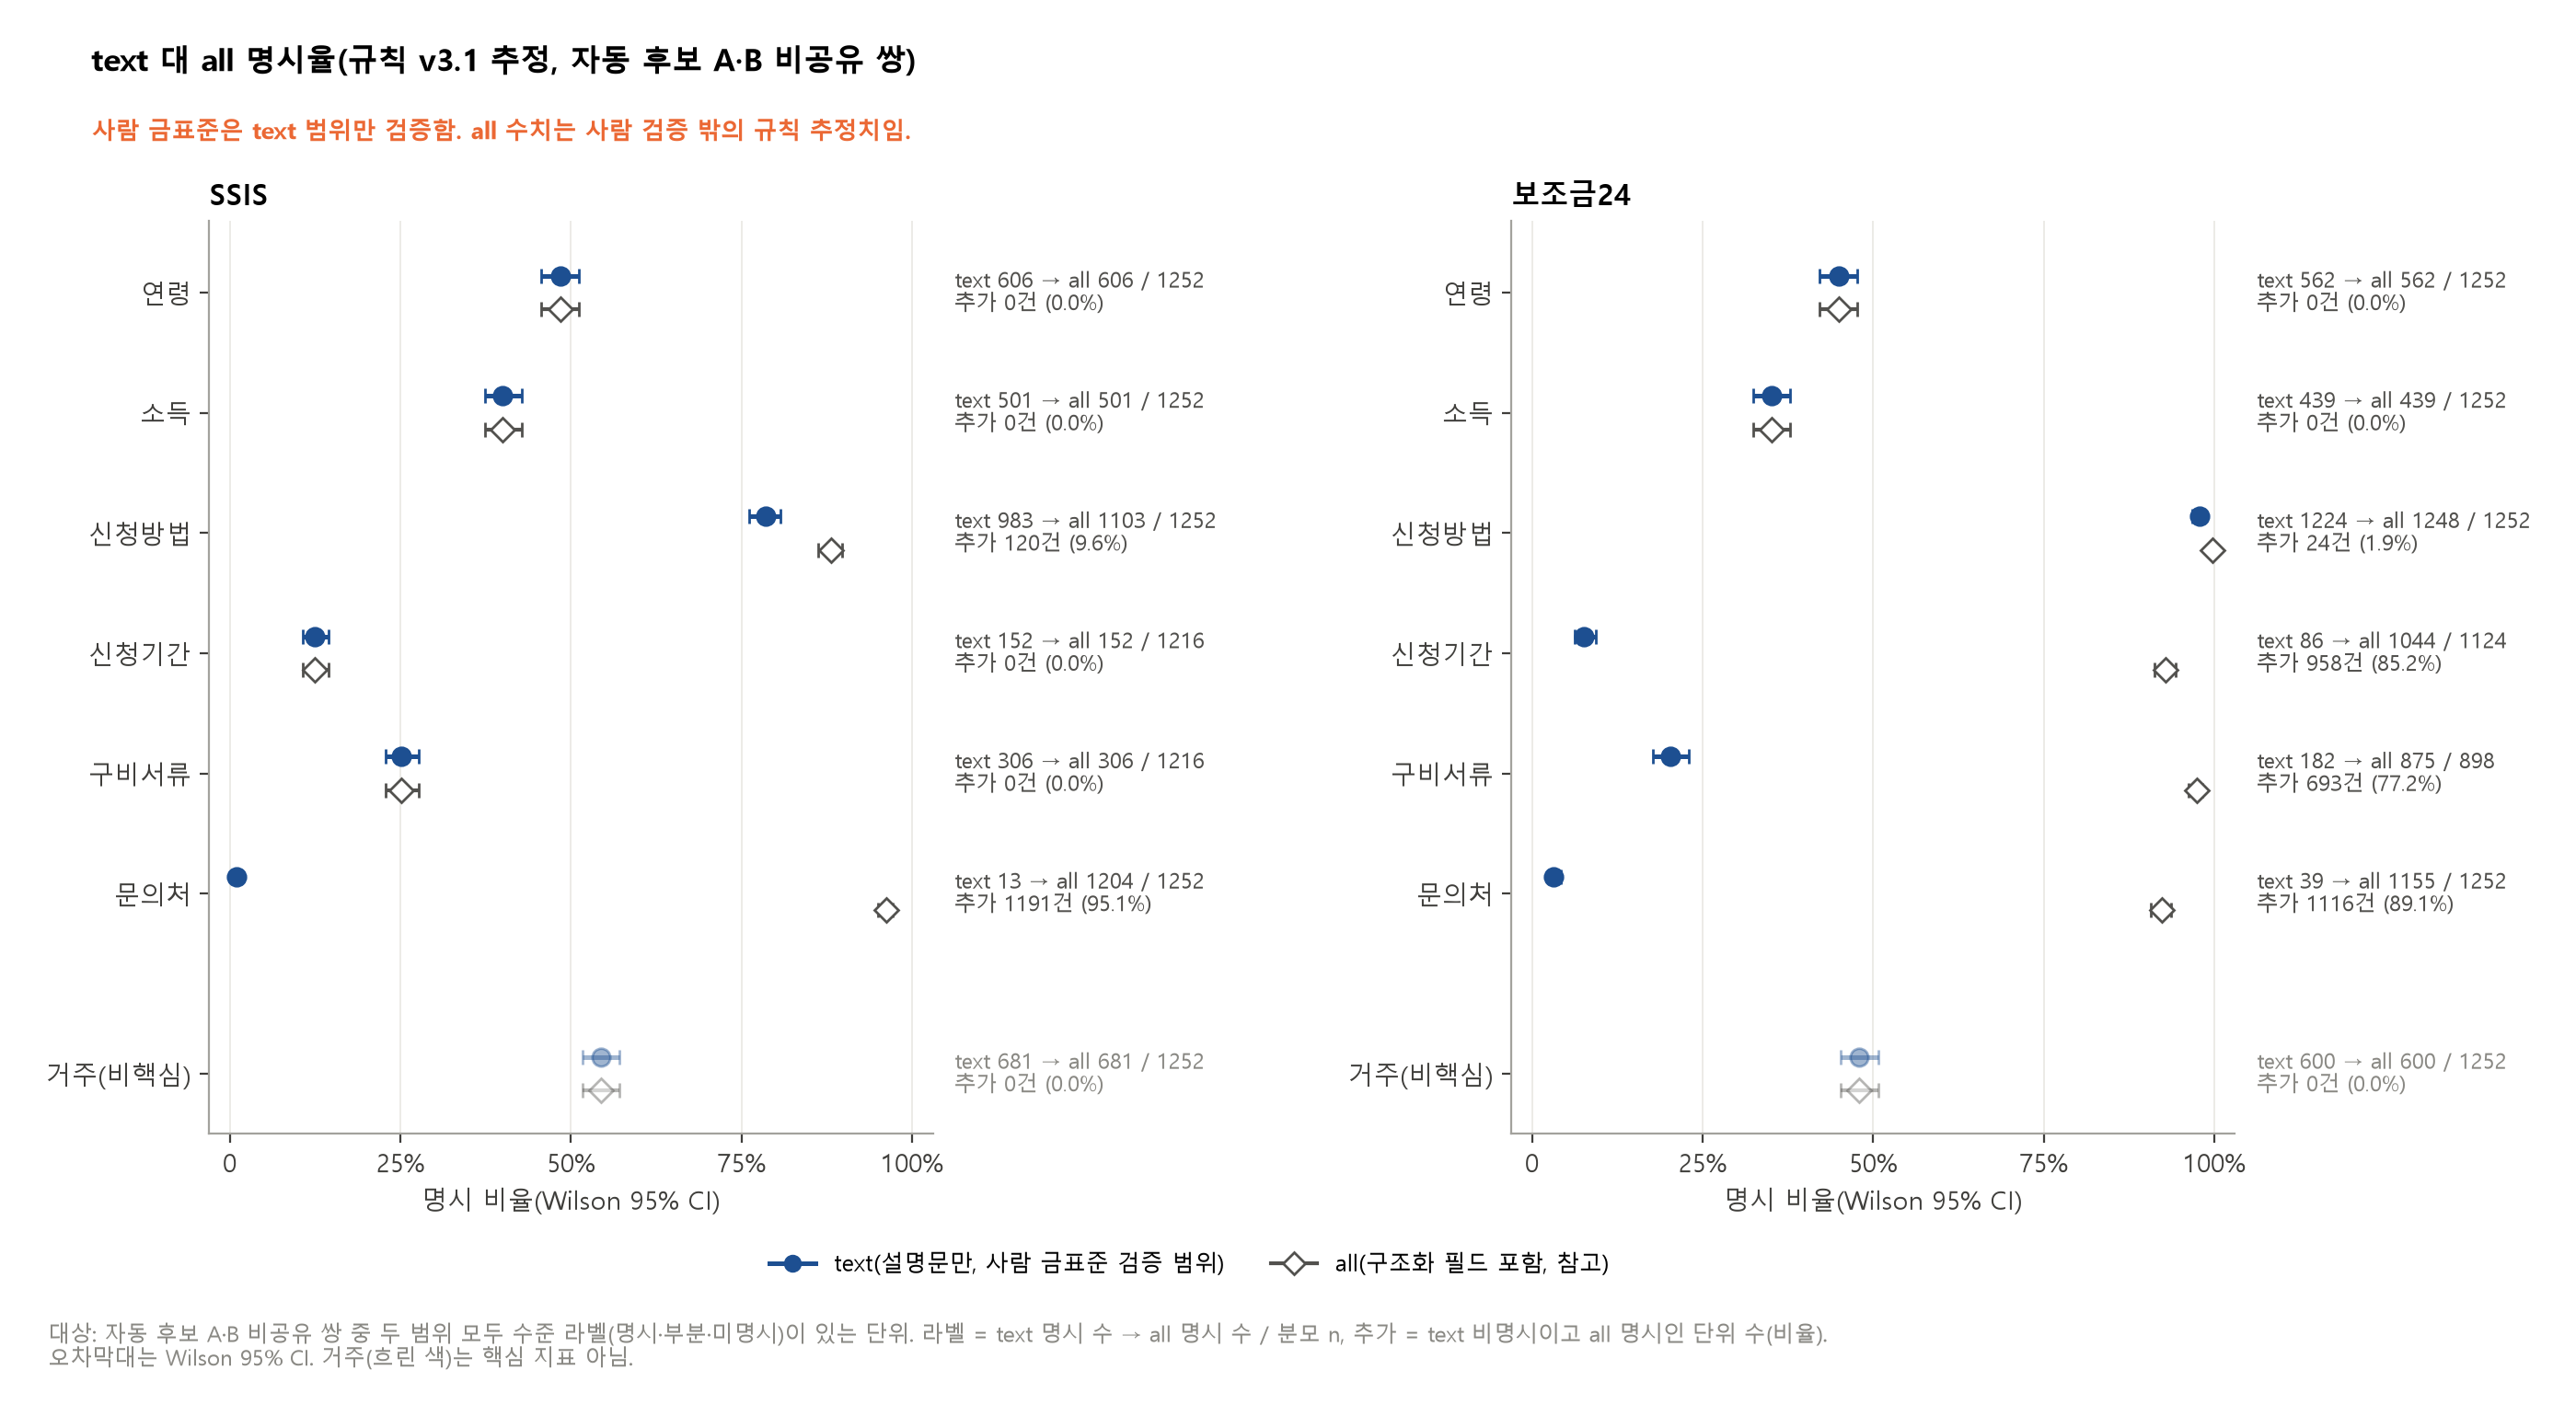

WindowsPath('outputs/04_q2/figures/final/03_text_vs_all.png')

In [28]:
tv = FT["text_vs_all"]
disp(tv, "표 H-6. text 대 all — 항목×side(규칙 v3.1, 자동 후보 A·B 비공유 쌍)", drop=["note", "label", "test_note", "holm_family", "text_ci_low", "text_ci_high", "all_ci_low", "all_ci_high", "lost_ci_low", "lost_ci_high"],
     note="added_by_all = text 비명시이고 all 명시인 단위 / n. 신뢰구간(added_ci_*)은 Wilson 95%. 사람 금표준은 text 범위만 검증했으므로 all 수치는 사람 검증 밖.")
fig, axes = plt.subplots(1, 2, figsize=(14.2, 6.8), sharey=True)
fig.subplots_adjust(wspace=0.8, top=0.84)
YP = {it: (k if it != "residence" else 6.5) for k, it in enumerate(ORDER_ALL)}
tvi = tv.set_index(["item", "side"])
for ax, side in zip(axes, ["ssis", "gov"]):
    for it in ORDER_ALL:
        r = tvi.loc[(it, side)]
        a = 1 if it != "residence" else 0.42
        ax.errorbar(r.share_text, YP[it] - 0.14, xerr=[[r.share_text - r.text_ci_low], [r.text_ci_high - r.share_text]], fmt="o", color=C_DARK, alpha=a, ms=7, capsize=3, lw=1.8, zorder=3)
        ax.errorbar(r.share_all, YP[it] + 0.14, xerr=[[r.share_all - r.all_ci_low], [r.all_ci_high - r.share_all]], fmt="D", color=INK2, mfc="white", alpha=a, ms=6.5, capsize=3, lw=1.5, zorder=3)
        ax.annotate(f"text {int(r.k_text)} → all {int(r.k_all)} / {int(r.n)}\n추가 {int(r.k_added_by_all)}건 ({100 * r.added_by_all:.1f}%)", xy=(1.03, YP[it]), xycoords=("axes fraction", "data"),
                    va="center", fontsize=8.2, color=INK2 if it != "residence" else MUTED, annotation_clip=False)
    ax.set_xlim(-0.03, 1.03); ax.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"]); ax.grid(axis="y", visible=False)
    ax.set_title(SIDE_KO[side]); ax.set_xlabel("명시 비율(Wilson 95% CI)")
axes[0].set_yticks(list(YP.values()), [KO[i] if i != "residence" else "거주(비핵심)" for i in ORDER_ALL]); axes[0].set_ylim(7.0, -0.6)
axes[1].tick_params(labelleft=True)
fig.legend(handles=[plt.Line2D([], [], marker="o", color=C_DARK, lw=1.8, label="text(설명문만, 사람 금표준 검증 범위)"), plt.Line2D([], [], marker="D", color=INK2, mfc="white", lw=1.5, label="all(구조화 필드 포함, 참고)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("text 대 all 명시율(규칙 v3.1 추정, 자동 후보 A·B 비공유 쌍)", x=0.08, ha="left", fontsize=12, fontweight="bold")
fig.text(0.08, 0.905, "사람 금표준은 text 범위만 검증함. all 수치는 사람 검증 밖의 규칙 추정치임.", fontsize=9.5, color=C_ORANGE, fontweight="bold")
save_fig(fig, "03_text_vs_all", "대상: 자동 후보 A·B 비공유 쌍 중 두 범위 모두 수준 라벨(명시·부분·미명시)이 있는 단위. 라벨 = text 명시 수 → all 명시 수 / 분모 n, 추가 = text 비명시이고 all 명시인 단위 수(비율). 오차막대는 Wilson 95% CI. 거주(흐린 색)는 핵심 지표 아님.", folder=FFIG)

In [29]:
tvc = tv[tv.core_metric]
big = tvc[tvc.k_added_by_all > 0].sort_values("added_by_all", ascending=False)
zero = tvc[tvc.k_added_by_all == 0]
SIDE_LBL = {"ssis": "SSIS", "gov": "보조금24"}
OBS["tva"] = "\n".join(
    ["- 두 범위 모두 수준 라벨이 있는 단위, text 비명시이고 all 명시인 비율(추가)"]
    + [f"  - {SIDE_LBL[r.side]} {KO[r['item']]}: {kn(r.k_added_by_all, r.n)}({100*r.added_by_all:.1f}%, 95% CI {ci2(r.added_ci_low, r.added_ci_high)})" for _, r in big.iterrows()]
    + [f"- 나머지 {len(zero)}개 항목×side는 추가 0건",
       f"- text 명시가 all에서 비명시로 바뀐 단위: 핵심 6항목 합계 {int(tvc.k_lost_in_all.sum())}건"])
INT["tva"] = "\n".join([
    "- 구조화 필드 포함 시 명시로 바뀐 단위가 큰 항목: 보조금24 신청기간, 구비서류, 양쪽 문의처, SSIS 신청방법",
    "- 사람 금표준은 text 범위만 검증, all 수치는 사람 검증 밖"])
LIM["tva"] = "\n".join([
    "- 플랫폼별 구조화 필드 구성 상이: all 범위의 두 플랫폼 비교는 같은 종류의 정보 비교 아님",
    "- 규칙 정확도는 text 범위 표본으로만 확인"])
md("**관찰**\n" + OBS["tva"] + "\n\n**해석**\n" + INT["tva"] + "\n\n**한계**\n" + LIM["tva"])

**관찰**
- 두 범위 모두 수준 라벨이 있는 단위, text 비명시이고 all 명시인 비율(추가)
  - SSIS 문의처: 1191/1252(95.1%, 95% CI 93.8~96.2%)
  - 보조금24 문의처: 1116/1252(89.1%, 95% CI 87.3~90.7%)
  - 보조금24 신청기간: 958/1124(85.2%, 95% CI 83.0~87.2%)
  - 보조금24 구비서류: 693/898(77.2%, 95% CI 74.3~79.8%)
  - SSIS 신청방법: 120/1252(9.6%, 95% CI 8.1~11.3%)
  - 보조금24 신청방법: 24/1252(1.9%, 95% CI 1.3~2.8%)
- 나머지 6개 항목×side는 추가 0건
- text 명시가 all에서 비명시로 바뀐 단위: 핵심 6항목 합계 0건

**해석**
- 구조화 필드 포함 시 명시로 바뀐 단위가 큰 항목: 보조금24 신청기간, 구비서류, 양쪽 문의처, SSIS 신청방법
- 사람 금표준은 text 범위만 검증, all 수치는 사람 검증 밖

**한계**
- 플랫폼별 구조화 필드 구성 상이: all 범위의 두 플랫폼 비교는 같은 종류의 정보 비교 아님
- 규칙 정확도는 text 범위 표본으로만 확인

### Decision Box 11 — 일치도 지표
- **문제:** 4인 공통 표본 없음, 중복 단위마다 검수자 2명
- **선택:** Fleiss 카파, Krippendorff 알파(nominal). 카파 구간은 bootstrap 2000회
- **근거:** 단위별 평점자 수 동일, 구성 상이 → Cohen 카파 부적합
- **한계:** 검수자 쌍별 표본 4–5건 → 쌍별 일치율 계산, 표본 작음(H-8-S7). 0.60은 기준 재점검 참고값

## H-7. 검수자 일치도
- 일치율: 일치 / 중복 단위, Wilson 95% CI
- Fleiss 카파(bootstrap 95% CI), Krippendorff 알파
- 검수자 쌍별 건수(일치율, 구간은 H-8-S7)

In [30]:
ag, bp = FT["agreement"], FT["agreement_by_pair"]
disp(ag, "표 H-7a. 중복 검수 일치도", drop=["note"], note="pct_agree = n_agree / n_double. 카파 구간은 단위 bootstrap 2000회. 4인 공통 표본이 없어 4인 통계는 내지 않음. n_disagree = 검수자 원 판정 불일치 건수(최종 미해결과 다름, 최종 미해결 0건은 H-2a).")
disp(bp, "표 H-7b. 검수자 쌍별 일치 건수(일치율은 H-8-S7)", drop=["note"])
agi = ag.set_index("table")
am, ai_ = agi.loc["match"], agi.loc["item"]
assert (int(am.n_agree), int(am.n_double), int(ai_.n_agree), int(ai_.n_double)) == (18, 24, 19, 30)
OBS["agree"] = "\n".join([
    f"- 매칭: 중복 {int(am.n_double)}쌍 중 {int(am.n_agree)}쌍 일치(95% CI {ci2(am.pct_ci_low, am.pct_ci_high)})",
    f"- 매칭 Fleiss 카파 {am.fleiss_kappa:.2f}(bootstrap 95% CI {am.kappa_ci_low:.2f}~{am.kappa_ci_high:.2f}), Krippendorff 알파 {am.krippendorff_alpha:.2f}",
    f"- 항목: 중복 {int(ai_.n_double)}단위 중 {int(ai_.n_agree)}단위 일치(95% CI {ci2(ai_.pct_ci_low, ai_.pct_ci_high)})",
    f"- 항목 Fleiss 카파 {ai_.fleiss_kappa:.2f}(bootstrap 95% CI {ai_.kappa_ci_low:.2f}~{ai_.kappa_ci_high:.2f}), 알파 {ai_.krippendorff_alpha:.2f}",
    f"- 검수자 쌍별 표본: 매칭 쌍당 {int(bp[bp.table.eq('match')].n.iloc[0])}건, 항목 쌍당 {int(bp[bp.table.eq('item')].n.iloc[0])}건(쌍별 일치율은 H-8-S7)"])
INT["agree"] = "\n".join([
    f"- Fleiss 카파 {am.fleiss_kappa:.2f}, {ai_.fleiss_kappa:.2f}: 모두 0.60 미만",
    "- 판정 기준 재점검용 참고값, 통과 기준 아님",
    f"- 검수자 원 판정 불일치 매칭 {int(am.n_disagree)}쌍, 항목 {int(ai_.n_disagree)}단위는 제3자 판정으로 확정(최종 미해결 0건, 일치도는 원 판정 기준 유지)"])
LIM["agree"] = "\n".join([
    "- 중복 단위 적음(매칭 24쌍, 항목 30단위): 카파 bootstrap 구간 넓음",
    "- 4명이 같은 표본 전체를 보지 않아 4인 통계 없음",
    "- 검수자 쌍별 일치율은 계산, 표본 작음(H-8-S7)"])
md("**관찰**\n" + OBS["agree"] + "\n\n**해석**\n" + INT["agree"] + "\n\n**한계**\n" + LIM["agree"])

**표 H-7a. 중복 검수 일치도**

table,n_double,n_both,n_agree,n_disagree,pct_agree,pct_ci_low,pct_ci_high,fleiss_kappa,kappa_ci_low,kappa_ci_high,krippendorff_alpha
match,24,24,18,6,0.750,0.551,0.880,0.508,0.150,0.818,0.518
item,30,30,19,11,0.633,0.455,0.781,0.399,0.139,0.640,0.409


<span style='color:#8a8984;font-size:90%'>pct_agree = n_agree / n_double. 카파 구간은 단위 bootstrap 2000회. 4인 공통 표본이 없어 4인 통계는 내지 않음. n_disagree = 검수자 원 판정 불일치 건수(최종 미해결과 다름, 최종 미해결 0건은 H-2a).</span>

**표 H-7b. 검수자 쌍별 일치 건수(일치율은 H-8-S7)**

table,pair,n,n_agree,n_double
item,R1-R2,5,3,5
item,R1-R3,5,4,5
item,R1-R4,5,5,5
item,R2-R3,5,2,5
item,R2-R4,5,3,5
item,R3-R4,5,2,5
match,R1-R2,4,3,4
match,R1-R3,4,3,4
match,R1-R4,4,0,4
match,R2-R3,4,4,4


**관찰**
- 매칭: 중복 24쌍 중 18쌍 일치(95% CI 55.1~88.0%)
- 매칭 Fleiss 카파 0.51(bootstrap 95% CI 0.15~0.82), Krippendorff 알파 0.52
- 항목: 중복 30단위 중 19단위 일치(95% CI 45.5~78.1%)
- 항목 Fleiss 카파 0.40(bootstrap 95% CI 0.14~0.64), 알파 0.41
- 검수자 쌍별 표본: 매칭 쌍당 4건, 항목 쌍당 5건(쌍별 일치율은 H-8-S7)

**해석**
- Fleiss 카파 0.51, 0.40: 모두 0.60 미만
- 판정 기준 재점검용 참고값, 통과 기준 아님
- 검수자 원 판정 불일치 매칭 6쌍, 항목 11단위는 제3자 판정으로 확정(최종 미해결 0건, 일치도는 원 판정 기준 유지)

**한계**
- 중복 단위 적음(매칭 24쌍, 항목 30단위): 카파 bootstrap 구간 넓음
- 4명이 같은 표본 전체를 보지 않아 4인 통계 없음
- 검수자 쌍별 일치율은 계산, 표본 작음(H-8-S7)

## H-8. 보완 분석
- 대상: H-2 ~ H-7 결과의 보정, 민감도, 보충 지표
- 계산: `q2_final.build_supp`, 저장: `final/supp_*.csv`
- 상태: 참고 추정, 확정 값 아님
- 구성: S1 보정 명시율, S2 A 등급, S3 보조금24 화면 점검, S4 이분 일치도, S5 가중 정확도 구간, S6 정확도 범위(미해결 0건), S7 쌍별 일치율
- 결과 표기: 결과 수치, 해석, 한계, 결정

### Decision Box 12 — 보정 명시율, 가중 정확도 구간, 화면 점검 표본
- **문제:** 규칙 라벨 명시율에 사람 판정 반영, 층 표본 3~4건이라 정규근사 부적합
- **선택:** 층별 Jeffreys 사후 MC 결합(20000회, seed 20261110), `참고 추정(표본 부족)` 표기, 플랫폼 간 검정 없음
- **근거:** 층 N_h 가중은 H-3, H-4와 같은 방식. Beta 사후라 0 또는 전부인 층도 구간 계산 가능
- **한계:** 근사 구간, 층당 사람 수준 라벨 1~3건
- **화면 점검:** 보조금24 45건은 규칙 가지별 목적 표본(가지당 15건). 가지별 보고만, 합산 비율과 일반화 없음

In [31]:
print({k: v.shape for k, v in ST.items()})

{'supp_calibrated_explicitness': (14, 23), 'supp_tierA_paired_tests': (14, 24), 'supp_gov24_screen': (3, 28), 'supp_default_sensitivity': (1, 24), 'supp_default_rule_counts': (3, 11), 'supp_agreement_binary': (4, 15), 'supp_weighted_accuracy_ci': (45, 16), 'supp_rule_accuracy_bounds': (21, 11), 'supp_agreement_by_pair': (12, 8)}


### H-8-S1. 사람 기준 보정 명시율 — 요약
- 팀 결정: 보정 명시율은 부록 A에 배치, 본문 주 결과는 규칙 기반 명시율 유지
- 본문 요약: 보정 전후 플랫폼 비교 방향 유지 여부만 제시

In [32]:
c1s = ST["supp_calibrated_explicitness"]
c1s = c1s[c1s.item.isin(CB.CORE_ITEMS)].pivot(index="item", columns="side", values=["p_rule", "p_cal"])
same = [(c1s.loc[i, ("p_rule", "gov")] > c1s.loc[i, ("p_rule", "ssis")]) == (c1s.loc[i, ("p_cal", "gov")] > c1s.loc[i, ("p_cal", "ssis")]) for i in c1s.index]
md("\n".join([
    "**결과 수치**",
    f"- 보정 전후 플랫폼 비교 방향 동일: 핵심 {sum(same)}/{len(same)}항목",
    "",
    "**한계**",
    "- 보정 명시율은 참고 추정(층당 사람 라벨 1~3건), 두 플랫폼 구간이 겹쳐 차이 크기 판단 불가",
    "- 세부 수치는 부록 A",
]))

**결과 수치**
- 보정 전후 플랫폼 비교 방향 동일: 핵심 6/6항목

**한계**
- 보정 명시율은 참고 추정(층당 사람 라벨 1~3건), 두 플랫폼 구간이 겹쳐 차이 크기 판단 불가
- 세부 수치는 부록 A

### H-8-S2. A 등급 민감도
- 대상: 쌍 집합만 자동 후보 A 등급 비공유 쌍으로 제한
- 방법: H-5b와 동일(정확 McNemar, Newcombe 95% CI, Holm 12검정)
- 확인: 차이 방향이 A·B 결과와 같은지

In [33]:
t2 = ST["supp_tierA_paired_tests"]
disp(t2, "표 H-8b. A 등급 대응 비교(정확 McNemar, Holm 12검정은 이 표 안)", drop=["note", "tierA_note", "test_note", "holm_family", "pair_set"],
     note="A 등급 비공유 쌍. direction_same_as_AB = 차이 부호가 A·B 비공유 쌍(H-5b)과 같음. 차이 = 보조금24 − SSIS.")
c2 = t2[t2.core_metric]
t2t = c2[c2.scope.eq("text")].set_index("item")
OBS["s2"] = "\n".join(
    [f"- A 등급 비공유 쌍, 핵심 6항목 text 대응 쌍 {int(t2t.n_pairs.min()):,}~{int(t2t.n_pairs.max()):,}쌍",
     "- 보조금24 − SSIS 차이(%p, Newcombe 95% CI), text: "
     + ", ".join(f"{KO[i]} {100*t2t.loc[i,'diff']:+.1f}({100*t2t.loc[i,'diff_ci_low']:+.1f}~{100*t2t.loc[i,'diff_ci_high']:+.1f})" for i in ORDER_I),
     f"- 차이 방향이 A·B와 같은 검정: 핵심 12검정 중 {int(c2.direction_same_as_AB.sum())}개",
     f"- Holm 보정 p: 핵심 12검정 중 0.05 미만 {int((c2.holm_p < 0.05).sum())}개(최대 {c2.holm_p.max():.3f})"])
INT["s2"] = "\n".join([
    "- A 등급으로 제한해도 모든 핵심 검정에서 A·B와 같은 방향" if bool(c2.direction_same_as_AB.all()) else "- A 등급 제한 시 A·B와 방향이 다른 검정 있음",
    ])
LIM["s2"] = "\n".join([
    "- A 등급도 사람 검수 13/15 동일(95% CI 0.62~0.96), A 안에도 매칭 오류 가능",
    "- 규칙 기반 추정(v3.1), 규칙 정확도는 H-4"])
md("**결과 수치**\n" + OBS["s2"] + "\n\n**해석**\n" + INT["s2"] + "\n\n**한계**\n" + LIM["s2"])

**표 H-8b. A 등급 대응 비교(정확 McNemar, Holm 12검정은 이 표 안)**

scope,item,core_metric,n_pairs,n_both_explicit,b_gov_only,c_ssis_only,n_both_not,p_ssis,p_gov,diff,diff_ci_low,diff_ci_high,mcnemar_p,n_unresolved,holm_p,diff_AB_nonshared,n_pairs_AB_nonshared,direction_same_as_AB
text,age,True,1026,429,39,69,489,0.485,0.456,-0.029,-0.049,-0.009,0.00502,0,0.01,-0.035,1252,True
text,income,True,1026,319,31,83,593,0.392,0.341,-0.051,-0.071,-0.030,1.18e-06,0,8.26e-06,-0.050,1252,True
text,residence,False,1026,448,55,120,403,0.554,0.490,-0.063,-0.088,-0.038,9.97e-07,0,—,-0.065,1252,True
text,channel,True,1026,808,195,13,10,0.800,0.978,0.177,0.152,0.203,7.78e-43,0,7.78e-42,0.192,1252,True
text,period,True,939,14,60,111,754,0.133,0.079,-0.054,-0.082,-0.027,0.000118,0,0.000591,-0.059,1125,True
text,documents,True,939,49,96,203,591,0.268,0.154,-0.114,-0.149,-0.078,5.8e-10,0,4.64e-09,-0.108,1125,True
text,contact,True,1026,3,27,6,990,0.009,0.029,0.020,0.010,0.033,0.000324,0,0.000972,0.021,1252,True
all,age,True,1026,429,39,69,489,0.485,0.456,-0.029,-0.049,-0.009,0.00502,0,0.01,-0.035,1252,True
all,income,True,1026,319,31,83,593,0.392,0.341,-0.051,-0.071,-0.030,1.18e-06,0,8.26e-06,-0.050,1252,True
all,residence,False,1026,448,55,120,403,0.554,0.490,-0.063,-0.088,-0.038,9.97e-07,0,—,-0.065,1252,True


<span style='color:#8a8984;font-size:90%'>A 등급 비공유 쌍. direction_same_as_AB = 차이 부호가 A·B 비공유 쌍(H-5b)과 같음. 차이 = 보조금24 − SSIS.</span>

**결과 수치**
- A 등급 비공유 쌍, 핵심 6항목 text 대응 쌍 939~1,026쌍
- 보조금24 − SSIS 차이(%p, Newcombe 95% CI), text: 연령 -2.9(-4.9~-0.9), 소득 -5.1(-7.1~-3.0), 신청방법 +17.7(+15.2~+20.3), 신청기간 -5.4(-8.2~-2.7), 구비서류 -11.4(-14.9~-7.8), 문의처 +2.0(+1.0~+3.3)
- 차이 방향이 A·B와 같은 검정: 핵심 12검정 중 12개
- Holm 보정 p: 핵심 12검정 중 0.05 미만 12개(최대 0.010)

**해석**
- A 등급으로 제한해도 모든 핵심 검정에서 A·B와 같은 방향

**한계**
- A 등급도 사람 검수 13/15 동일(95% CI 0.62~0.96), A 안에도 매칭 오류 가능
- 규칙 기반 추정(v3.1), 규칙 정확도는 H-4

### H-8-S3. 보조금24 화면 점검 45건
- 대상: 규칙 가지 3개 × 15건(구비서류 모순, 구비서류 모호, 신청기한 기본값)
- 방법: API 값과 상세 화면 표시를 사람이 대조(점검자 1명), 자유 서술은 코딩하지 않음
- 보고: 가지별만. 목적 표본이라 합산 비율 없음
- 민감도: 기본값 규칙의 all 명시를 비명시로 본 text 대 all 재계산
- 팀 결정('상시신청'): v3.1 기준 명시 유지, 기본값 의심 사례(rule `gov_deadline_default`) 별도 표시, 기본값 제외 민감도 병기
- 팀 결정(구비서류 '해당 없음'): 서류 불필요 근거가 없으면 판단불가, '제출서류 없음' 확인 시에만 명시 → v3.2 반영 예정
- 현재 수치 영향 없음: v3.1의 해당없음, 판단불가 모두 메타 라벨이라 명시율 분모 밖

In [34]:
g3 = ST["supp_gov24_screen"]
disp(g3, "표 H-8c. 보조금24 화면 점검 — 규칙 가지별(Wilson 95% CI)", drop=["note", "rule_id"] + [c for c in g3.columns if c.endswith("_ci_low") or c.endswith("_ci_high")],
     note="규칙 가지별 목적 표본, 전체 일반화 불가. 구간은 CSV(Wilson 95%).")
ds = ST["supp_default_sensitivity"].iloc[0]
rc = ST["supp_default_rule_counts"]
disp(rc, "표 H-8d. 기본값 규칙의 all 범위 라벨 건수(gov, AB 비공유 쌍)", drop=["note", "side", "scope"])
sens = ST["supp_default_sensitivity"]
disp(sens, "표 H-8e. 기본값 제외 민감도 — 보조금24 신청기간, text 대 all", drop=["note", "side", "pair_set"] + [c for c in sens.columns if "ci_" in c],
     note="original = 현재 규칙, sensitivity = gov_deadline_default의 all 명시를 비명시로 봄. McNemar는 정확 검정, 구간은 CSV.")
gi = g3.set_index("branch")
BR = {"docs_contradicted": "구비서류 모순", "docs_ambiguous": "구비서류 모호", "deadline_default": "신청기한 기본값"}
d_ = rc.set_index("rule_id")


def gline(b):
    r = gi.loc[b]
    return (f"  - {BR[b]} {int(r.n)}건: 화면 찾음 {kn(r.k_page_found, r.n)}, 화면 신청기한 상시신청 {kn(r.k_page_deadline_always, r.n)}, "
            f"화면 구비서류 해당 없음류 {kn(r.k_page_docs_none, r.n)}, 구비서류 API 일치 {kn(r.k_docs_match_api, r.n)}(불일치 {int(r.k_docs_mismatch_api)}), "
            f"신청기한 API 일치 {kn(r.k_deadline_match_api, r.n)}")


OBS["s3"] = "\n".join(
    ["- 규칙 가지별 목적 표본, 전체 일반화 불가(합산 비율 없음)"] + [gline(b) for b in BR]
    + [f"- 기본값 규칙 all 범위 명시(gov, AB 비공유): 신청기간 gov_deadline_default {int(d_.at['gov_deadline_default', 'n_explicit'])}건",
       f"- 구비서류 gov_docs_ambiguous {int(d_.at['gov_docs_ambiguous', 'n_units'])}건은 판단불가, gov_docs_na_consistent {int(d_.at['gov_docs_na_consistent', 'n_units'])}건은 해당없음 라벨(명시 0건)",
       f"- 신청기간 text 대 all, 보조금24 {int(ds.n):,}쌍: all 명시 {PCT(ds.share_all_original)}({int(ds.k_all_original)}건) → 기본값 제외 {PCT(ds.share_all_sensitivity)}({int(ds.k_all_sensitivity)}건)",
       f"- 추가(text 비명시, all 명시): {kn(ds.k_added_by_all_original, ds.n)}({PCT(ds.added_by_all_original)}, 95% CI {ci2(ds.added_ci_low_original, ds.added_ci_high_original)}) → "
       f"{kn(ds.k_added_by_all_sensitivity, ds.n)}({PCT(ds.added_by_all_sensitivity)}, 95% CI {ci2(ds.added_ci_low_sensitivity, ds.added_ci_high_sensitivity)})",
       f"- 정확 McNemar p: 원래 {fmt_p(ds.mcnemar_p_original)}, 기본값 제외 {fmt_p(ds.mcnemar_p_sensitivity)}"])
INT["s3"] = "\n".join([
    f"- 신청기간 all 범위 명시 {int(ds.k_all_original)}건 중 기본값 규칙 {int(ds.k_default_explicit_in_n)}건({PCT(ds.k_default_explicit_in_n / ds.k_all_original)})",
    "- 기본값을 명시로 볼지에 따라 all 범위 신청기간 명시율이 크게 달라짐",
    "- 구비서류 기본값 규칙은 명시가 아니라 원래 분모 밖, 민감도 대상 아님"])
LIM["s3"] = "\n".join([
    "- 45건은 규칙 가지별 목적 표본, 모집단 비율 추정 불가",
    "- 점검자 1명, 자유 서술(h_note)은 코딩하지 않음",
    "- 신청기간 기본값 제외 민감도만 계산, 구비서류는 대상 라벨이 명시가 아니어서 계산하지 않음",
    "- 사람 금표준은 text 범위만 검증, all 수치는 사람 검증 밖"])
TEAM["s3"] = "\n".join([
    "- 결정: '상시신청'은 v3.1 기준 명시 유지, 기본값 의심 사례 별도 표시와 민감도 병기",
    "- 결정: 구비서류 '해당 없음'은 근거 없으면 판단불가, '제출서류 없음' 확인 시에만 명시(v3.2 반영 예정)"])
md("**결과 수치**\n" + OBS["s3"] + "\n\n**해석**\n" + INT["s3"] + "\n\n**한계**\n" + LIM["s3"] + "\n\n**결정**\n" + TEAM["s3"])

**표 H-8c. 보조금24 화면 점검 — 규칙 가지별(Wilson 95% CI)**

branch,n,k_page_found,share_page_found,k_page_deadline_always,share_page_deadline_always,k_page_docs_none,share_page_docs_none,k_docs_match_api,share_docs_match_api,k_docs_mismatch_api,share_docs_mismatch_api,k_deadline_match_api,share_deadline_match_api
docs_contradicted,15,15,1.000,13,0.867,15,1.000,15,1.000,0,0.000,15,1.000
docs_ambiguous,15,15,1.000,13,0.867,15,1.000,15,1.000,0,0.000,15,1.000
deadline_default,15,15,1.000,15,1.000,4,0.267,14,0.933,1,0.067,15,1.000


<span style='color:#8a8984;font-size:90%'>규칙 가지별 목적 표본, 전체 일반화 불가. 구간은 CSV(Wilson 95%).</span>

**표 H-8d. 기본값 규칙의 all 범위 라벨 건수(gov, AB 비공유 쌍)**

item,rule_id,n_units,n_explicit,n_partial,n_not_explicit,n_meta_na,n_meta_undecidable
period,gov_deadline_default,655,655,0,0,0,0
documents,gov_docs_ambiguous,226,0,0,0,0,226
documents,gov_docs_na_consistent,101,0,0,0,101,0


**표 H-8e. 기본값 제외 민감도 — 보조금24 신청기간, text 대 all**

item,n,default_rule_ids,k_default_explicit_in_n,share_text,k_all_original,share_all_original,k_added_by_all_original,added_by_all_original,k_lost_in_all_original,mcnemar_p_original,k_all_sensitivity,share_all_sensitivity,k_added_by_all_sensitivity,added_by_all_sensitivity,k_lost_in_all_sensitivity,mcnemar_p_sensitivity
period,1124,gov_deadline_default,655,0.077,1044,0.929,958,0.852,0,0.000,389,0.346,303,0.270,0,0.000


<span style='color:#8a8984;font-size:90%'>original = 현재 규칙, sensitivity = gov_deadline_default의 all 명시를 비명시로 봄. McNemar는 정확 검정, 구간은 CSV.</span>

**결과 수치**
- 규칙 가지별 목적 표본, 전체 일반화 불가(합산 비율 없음)
  - 구비서류 모순 15건: 화면 찾음 15/15, 화면 신청기한 상시신청 13/15, 화면 구비서류 해당 없음류 15/15, 구비서류 API 일치 15/15(불일치 0), 신청기한 API 일치 15/15
  - 구비서류 모호 15건: 화면 찾음 15/15, 화면 신청기한 상시신청 13/15, 화면 구비서류 해당 없음류 15/15, 구비서류 API 일치 15/15(불일치 0), 신청기한 API 일치 15/15
  - 신청기한 기본값 15건: 화면 찾음 15/15, 화면 신청기한 상시신청 15/15, 화면 구비서류 해당 없음류 4/15, 구비서류 API 일치 14/15(불일치 1), 신청기한 API 일치 15/15
- 기본값 규칙 all 범위 명시(gov, AB 비공유): 신청기간 gov_deadline_default 655건
- 구비서류 gov_docs_ambiguous 226건은 판단불가, gov_docs_na_consistent 101건은 해당없음 라벨(명시 0건)
- 신청기간 text 대 all, 보조금24 1,124쌍: all 명시 92.9%(1044건) → 기본값 제외 34.6%(389건)
- 추가(text 비명시, all 명시): 958/1124(85.2%, 95% CI 83.0~87.2%) → 303/1124(27.0%, 95% CI 24.4~29.6%)
- 정확 McNemar p: 원래 p<0.001, 기본값 제외 p<0.001

**해석**
- 신청기간 all 범위 명시 1044건 중 기본값 규칙 655건(62.7%)
- 기본값을 명시로 볼지에 따라 all 범위 신청기간 명시율이 크게 달라짐
- 구비서류 기본값 규칙은 명시가 아니라 원래 분모 밖, 민감도 대상 아님

**한계**
- 45건은 규칙 가지별 목적 표본, 모집단 비율 추정 불가
- 점검자 1명, 자유 서술(h_note)은 코딩하지 않음
- 신청기간 기본값 제외 민감도만 계산, 구비서류는 대상 라벨이 명시가 아니어서 계산하지 않음
- 사람 금표준은 text 범위만 검증, all 수치는 사람 검증 밖

**결정**
- 결정: '상시신청'은 v3.1 기준 명시 유지, 기본값 의심 사례 별도 표시와 민감도 병기
- 결정: 구비서류 '해당 없음'은 근거 없으면 판단불가, '제출서류 없음' 확인 시에만 명시(v3.2 반영 예정)

### H-8-S4. 이분 일치도
- 항목: 명시 대 비명시(부분, 미명시). 메타 라벨(해당없음, 판단불가)이 있는 단위는 별도 집계
- 매칭: 동일 대 비동일(다름, 판단불가)
- 통계: H-7과 동일, 기존 다범주 값을 나란히 표시

In [35]:
b4 = ST["supp_agreement_binary"]
disp(b4, "표 H-8f. 이분 일치도와 기존 다범주 일치도", drop=["note"], note="이분 = 이 절의 계산, 다범주(기존) = H-7a 값. 일치도는 검수자 원 판정 기준이며 제3자 조정 결과는 반영하지 않음(검수자 불일치 매칭 6, 항목 11은 조정으로 확정, 최종 미해결 0건).")
bi4 = b4[b4.category_scheme.eq("이분")].set_index("table")
bo4 = b4[b4.category_scheme.eq("다범주(기존)")].set_index("table")
OBS["s4"] = "\n".join([
    f"- 매칭(동일 대 비동일): {int(bi4.at['match','n_agree'])}/{int(bi4.at['match','n_both'])} 일치(95% CI {ci2(bi4.at['match','pct_ci_low'], bi4.at['match','pct_ci_high'])}), Fleiss 카파 {bi4.at['match','fleiss_kappa']:.2f}, 알파 {bi4.at['match','krippendorff_alpha']:.2f}",
    f"- 매칭 다범주(기존): {int(bo4.at['match','n_agree'])}/{int(bo4.at['match','n_both'])}, Fleiss 카파 {bo4.at['match','fleiss_kappa']:.2f}, 알파 {bo4.at['match','krippendorff_alpha']:.2f}",
    f"- 항목(명시 대 비명시): {int(bi4.at['item','n_agree'])}/{int(bi4.at['item','n_both'])} 일치(95% CI {ci2(bi4.at['item','pct_ci_low'], bi4.at['item','pct_ci_high'])}), 카파 {bi4.at['item','fleiss_kappa']:.2f}, 알파 {bi4.at['item','krippendorff_alpha']:.2f}, 메타 라벨로 제외 {int(bi4.at['item','n_meta_excluded'])}단위",
    f"- 항목 다범주(기존): {int(bo4.at['item','n_agree'])}/{int(bo4.at['item','n_both'])}, 카파 {bo4.at['item','fleiss_kappa']:.2f}, 알파 {bo4.at['item','krippendorff_alpha']:.2f}"])
assert bi4.at["item", "pct_agree"] > bo4.at["item", "pct_agree"] and bi4.at["match", "pct_agree"] == bo4.at["match", "pct_agree"] and bi4.at["match", "fleiss_kappa"] < bo4.at["match", "fleiss_kappa"]
INT["s4"] = "\n".join([
    "- 항목은 이분으로 묶으면 일치율과 카파가 오름(부분과 미명시 불일치는 일치로 처리됨)",
    "- 매칭은 판단불가와 다름을 묶어 일치율 동일, 카파는 낮아짐"])
LIM["s4"] = "\n".join([
    "- 중복 단위 적음(매칭 24쌍, 항목 30단위), 카파 bootstrap 구간 넓음",
    "- 메타 라벨 단위는 이분 계산에서 빠짐",
    "- 이분 묶음은 사후 분석, 일치도 기준 통과 여부 판단용 아님"])
TEAM["s4"] = "\n".join(["- 결정: 17건 제3자 조정(김지우, 2026-11-11) 반영, 경계 사례는 v3.2 예시(`CB.RULES_32`)로 문서화, v3.1 결과 유지, v3.2는 별도 표본 검증"])
md("**결과 수치**\n" + OBS["s4"] + "\n\n**해석**\n" + INT["s4"] + "\n\n**한계**\n" + LIM["s4"] + "\n\n**결정**\n" + TEAM["s4"])

**표 H-8f. 이분 일치도와 기존 다범주 일치도**

table,category_scheme,n_double,n_both,n_meta_excluded,n_agree,n_disagree,pct_agree,pct_ci_low,pct_ci_high,fleiss_kappa,kappa_ci_low,kappa_ci_high,krippendorff_alpha
match,이분,24,24,0,18,6,0.750,0.551,0.880,0.467,0.063,0.812,0.478
match,다범주(기존),24,24,—,18,6,0.750,0.551,0.880,0.508,0.150,0.818,0.518
item,이분,30,29,1,22,7,0.759,0.579,0.878,0.515,0.147,0.792,0.523
item,다범주(기존),30,30,—,19,11,0.633,0.455,0.781,0.399,0.139,0.640,0.409


<span style='color:#8a8984;font-size:90%'>이분 = 이 절의 계산, 다범주(기존) = H-7a 값. 일치도는 검수자 원 판정 기준이며 제3자 조정 결과는 반영하지 않음(검수자 불일치 매칭 6, 항목 11은 조정으로 확정, 최종 미해결 0건).</span>

**결과 수치**
- 매칭(동일 대 비동일): 18/24 일치(95% CI 55.1~88.0%), Fleiss 카파 0.47, 알파 0.48
- 매칭 다범주(기존): 18/24, Fleiss 카파 0.51, 알파 0.52
- 항목(명시 대 비명시): 22/29 일치(95% CI 57.9~87.8%), 카파 0.51, 알파 0.52, 메타 라벨로 제외 1단위
- 항목 다범주(기존): 19/30, 카파 0.40, 알파 0.41

**해석**
- 항목은 이분으로 묶으면 일치율과 카파가 오름(부분과 미명시 불일치는 일치로 처리됨)
- 매칭은 판단불가와 다름을 묶어 일치율 동일, 카파는 낮아짐

**한계**
- 중복 단위 적음(매칭 24쌍, 항목 30단위), 카파 bootstrap 구간 넓음
- 메타 라벨 단위는 이분 계산에서 빠짐
- 이분 묶음은 사후 분석, 일치도 기준 통과 여부 판단용 아님

**결정**
- 결정: 17건 제3자 조정(김지우, 2026-11-11) 반영, 경계 사례는 v3.2 예시(`CB.RULES_32`)로 문서화, v3.1 결과 유지, v3.2는 별도 표본 검증

### H-8-S5. 가중 정확도 구간
- 대상: 매칭 A·B 층화 가중 정확도, 규칙 v3.1 층 가중 정확도
- 방법: 층별 Jeffreys 사후 MC 결합(근사), 기존 정규근사 값은 별도 열
- 표기: 모든 행에 `estimate_type`(비가중, 층 가중)과 `ci_method`(Wilson, 층별 Jeffreys 사후 MC 결합)

In [36]:
w5 = ST["supp_weighted_accuracy_ci"]
disp(w5, "표 H-8g. 정확도 구간 — 비가중(Wilson)과 층 가중(Jeffreys MC)", drop=["note", "n_strata_dropped", "estimate_definition"],
     note="old_normal_* = 기존 정규근사 구간(상한 1 절단). 층 가중 행의 n_strata_used = 확정 단위가 있는 층 수.")
ab5 = w5[w5.key.eq("AB_weighted")].iloc[0]
iw = w5[w5.table.eq("item") & w5.estimate_type.eq("층 가중") & w5.side.isin(["ssis", "gov"]) & w5.key.ne("residence")]
wid = (iw.ci_high - iw.ci_low)
OBS["s5"] = "\n".join([
    f"- 매칭 A·B 층 가중 정확도 {ab5.estimate:.2f}(사후 중앙값): Jeffreys MC 95% 구간 {ab5.ci_low:.2f}~{ab5.ci_high:.2f} (기존 정규근사 {ab5.old_normal_ci_low:.2f}~{ab5.old_normal_ci_high:.2f}, 상한 1 절단)",
    f"- 규칙 v3.1 층 가중 정확도(핵심 6항목×2side) 구간 폭 {wid.min():.2f}~{wid.max():.2f}",
    f"- 층 가중 정확도 최저 {iw.estimate.min():.2f}({KO[iw.loc[iw.estimate.idxmin(), 'key']]} {SL[iw.loc[iw.estimate.idxmin(), 'side']]}), 최고 {iw.estimate.max():.2f}({KO[iw.loc[iw.estimate.idxmax(), 'key']]} {SL[iw.loc[iw.estimate.idxmax(), 'side']]})"])
INT["s5"] = "\n".join([
    "- 매칭 가중 정확도의 상한이 1로 절단되지 않는 구간 확보",
    "- 규칙 층 가중 정확도는 구간이 넓어 항목 간 순위 구분 어려움"])
LIM["s5"] = "\n".join([
    "- 구간은 근사, 층 표본 3~4건에 사전분포 영향",
    "- 단순 층 가중값은 표에 별도 열(estimate_plugin)",
    "- 미해결 0건(정확도 범위는 H-8-S6)"])
md("**결과 수치**\n" + OBS["s5"] + "\n\n**해석**\n" + INT["s5"] + "\n\n**한계**\n" + LIM["s5"])

**표 H-8g. 정확도 구간 — 비가중(Wilson)과 층 가중(Jeffreys MC)**

table,key,side,estimate_type,estimate,estimate_plugin,ci_low,ci_high,ci_method,n_confirmed,n_strata_used,old_normal_ci_low,old_normal_ci_high
match,A,,비가중,0.867,0.867,0.621,0.963,Wilson,15,1,—,—
match,B,,비가중,0.733,0.733,0.480,0.891,Wilson,15,1,—,—
match,AB_weighted,,층 가중,0.832,0.842,0.649,0.934,층별 Jeffreys 사후 MC 결합(근사),30,2,0.696,0.989
item,age,ssis,비가중,0.667,0.667,0.354,0.879,Wilson,9,—,—,—
item,age,ssis,층 가중,0.753,0.812,0.516,0.866,층별 Jeffreys 사후 MC 결합(근사),9,3,—,—
item,age,gov,비가중,0.556,0.556,0.267,0.811,Wilson,9,—,—,—
item,age,gov,층 가중,0.535,0.543,0.272,0.784,층별 Jeffreys 사후 MC 결합(근사),9,3,—,—
item,age,all,비가중,0.611,0.611,0.386,0.797,Wilson,18,—,—,—
item,age,all,층 가중,0.637,0.677,0.469,0.783,층별 Jeffreys 사후 MC 결합(근사),18,6,—,—
item,income,ssis,비가중,0.667,0.667,0.354,0.879,Wilson,9,—,—,—


<span style='color:#8a8984;font-size:90%'>old_normal_* = 기존 정규근사 구간(상한 1 절단). 층 가중 행의 n_strata_used = 확정 단위가 있는 층 수.</span>

**결과 수치**
- 매칭 A·B 층 가중 정확도 0.83(사후 중앙값): Jeffreys MC 95% 구간 0.65~0.93 (기존 정규근사 0.70~0.99, 상한 1 절단)
- 규칙 v3.1 층 가중 정확도(핵심 6항목×2side) 구간 폭 0.35~0.76
- 층 가중 정확도 최저 0.54(연령 보조금24), 최고 0.93(문의처 SSIS)

**해석**
- 매칭 가중 정확도의 상한이 1로 절단되지 않는 구간 확보
- 규칙 층 가중 정확도는 구간이 넓어 항목 간 순위 구분 어려움

**한계**
- 구간은 근사, 층 표본 3~4건에 사전분포 영향
- 단순 층 가중값은 표에 별도 열(estimate_plugin)
- 미해결 0건(정확도 범위는 H-8-S6)

### H-8-S6. 규칙 정확도 미해결 범위
- 미해결 0건, 범위 불필요(하한 = 상한 = 정확도)
- `supp_rule_accuracy_bounds.csv`는 구조 유지용

In [37]:
b6 = ST["supp_rule_accuracy_bounds"]
disp(b6, "표 H-8h. 규칙 v3.1 정확도의 미해결 반영 범위(미해결 0건)", drop=["note"])
us6 = FT["unresolved_summary"].set_index("table")
assert int(us6.n_unresolved.sum()) == 0 and (b6.n_unresolved == 0).all() and (b6.acc_low_bound == b6.acc).all() and (b6.acc_high_bound == b6.acc).all()
OBS["s6"] = "\n".join([
    "- 미해결 0건, 범위 불필요",
    "- 모든 항목×side에서 하한 = 상한 = 정확도"])
INT["s6"] = "\n".join([
    "- 규칙 정확도는 H-4 값 그대로 해석"])
LIM["s6"] = "\n".join([
    "- 일치도에는 적용하지 않음(일치도는 검수 원 판정 기준)"])
TEAM["s6"] = "\n".join(["- 결정: 조정 17건(제3자, 김지우, 2026-11-11) 반영, 미해결 없음"])
md("**결과 수치**\n" + OBS["s6"] + "\n\n**해석**\n" + INT["s6"] + "\n\n**한계**\n" + LIM["s6"] + "\n\n**결정**\n" + TEAM["s6"])

**표 H-8h. 규칙 v3.1 정확도의 미해결 반영 범위(미해결 0건)**

item,side,core_metric,n_units,n_confirmed,n_unresolved,n_correct,acc,acc_low_bound,acc_high_bound
age,ssis,True,9,9,0,6,0.667,0.667,0.667
age,gov,True,9,9,0,5,0.556,0.556,0.556
age,all,True,18,18,0,11,0.611,0.611,0.611
income,ssis,True,9,9,0,6,0.667,0.667,0.667
income,gov,True,9,9,0,6,0.667,0.667,0.667
income,all,True,18,18,0,12,0.667,0.667,0.667
residence,ssis,False,9,9,0,6,0.667,0.667,0.667
residence,gov,False,9,9,0,5,0.556,0.556,0.556
residence,all,False,18,18,0,11,0.611,0.611,0.611
channel,ssis,True,9,9,0,7,0.778,0.778,0.778


**결과 수치**
- 미해결 0건, 범위 불필요
- 모든 항목×side에서 하한 = 상한 = 정확도

**해석**
- 규칙 정확도는 H-4 값 그대로 해석

**한계**
- 일치도에는 적용하지 않음(일치도는 검수 원 판정 기준)

**결정**
- 결정: 조정 17건(제3자, 김지우, 2026-11-11) 반영, 미해결 없음

### H-8-S7. 검수자 쌍별 일치도
- 대상: 두 검수자가 모두 판정한 중복 단위, 쌍별
- 지표: 일치율, Wilson 95% CI. 쌍별 카파는 내지 않음

In [38]:
p7 = ST["supp_agreement_by_pair"]
disp(p7, "표 H-8i. 검수자 쌍별 일치율(Wilson 95% CI)", drop=["note"], note="쌍별 n 4~5건, 구간 매우 넓음.")
OBS["s7"] = "\n".join(
    [f"- {'매칭' if t == 'match' else '항목'}: " + ", ".join(f"{r.pair} {int(r.n_agree)}/{int(r.n)}" for r in p7[p7.table.eq(t)].itertuples()) for t in ("match", "item")]
    + [f"- 구간 폭(상한−하한) {(p7.pct_ci_high - p7.pct_ci_low).min():.2f}~{(p7.pct_ci_high - p7.pct_ci_low).max():.2f}"])
INT["s7"] = "\n".join([
    "- 쌍마다 일치율 편차 큼(0~100%), 구간이 겹쳐 쌍 간 차이 판단 불가"])
LIM["s7"] = "\n".join([
    "- 쌍별 n 4~5건, 구간 매우 넓음",
    "- 쌍별 카파 없음",
    "- 쌍별 일치율은 계산했으나 표본 작음, 전체 일치도는 H-7a"])
md("**결과 수치**\n" + OBS["s7"] + "\n\n**해석**\n" + INT["s7"] + "\n\n**한계**\n" + LIM["s7"])

**표 H-8i. 검수자 쌍별 일치율(Wilson 95% CI)**

table,pair,n,n_agree,pct_agree,pct_ci_low,pct_ci_high
item,R1-R2,5,3,0.600,0.231,0.882
item,R1-R3,5,4,0.800,0.376,0.964
item,R1-R4,5,5,1.000,0.566,1.000
item,R2-R3,5,2,0.400,0.118,0.769
item,R2-R4,5,3,0.600,0.231,0.882
item,R3-R4,5,2,0.400,0.118,0.769
match,R1-R2,4,3,0.750,0.301,0.954
match,R1-R3,4,3,0.750,0.301,0.954
match,R1-R4,4,0,0.000,0.000,0.490
match,R2-R3,4,4,1.000,0.510,1.000


<span style='color:#8a8984;font-size:90%'>쌍별 n 4~5건, 구간 매우 넓음.</span>

**결과 수치**
- 매칭: R1-R2 3/4, R1-R3 3/4, R1-R4 0/4, R2-R3 4/4, R2-R4 4/4, R3-R4 4/4
- 항목: R1-R2 3/5, R1-R3 4/5, R1-R4 5/5, R2-R3 2/5, R2-R4 3/5, R3-R4 2/5
- 구간 폭(상한−하한) 0.43~0.65

**해석**
- 쌍마다 일치율 편차 큼(0~100%), 구간이 겹쳐 쌍 간 차이 판단 불가

**한계**
- 쌍별 n 4~5건, 구간 매우 넓음
- 쌍별 카파 없음
- 쌍별 일치율은 계산했으나 표본 작음, 전체 일치도는 H-7a

### 코드북 v3.2 경계 사례
- 이번 검수의 경계 사례를 `CB.RULES_32`에 예시로 정리(연령, 소득, 거주, 신청방법, 신청기간, 구비서류, 문의처)
- v3.1 라벨링 규칙과 결과는 그대로 유지
- v3.2 개선 효과는 별도 표본에서 검증 예정


# PART I. 보완 분석 — 서비스 단위 완성도, 청년 대상, 내용 비교
- 목적: 항목별 명시율(H-5, H-6)을 서비스(쌍) 단위로 묶어 통합 효과 확인
- 질문: 두 출처를 합치면 신청에 필요한 정보를 얼마나 더 확인할 수 있는가
- 계산: `src/preprocess/q2_completeness.py`, 저장: `final/svc_*.csv`, `youth_*.csv`, `content_*.csv`
- 재사용: 규칙 v3.1 라벨, 사람 확정 72쌍(H-2), 기본값 규칙(H-8-S3). 기존 표는 다시 계산하지 않음
- 해석 범위: 명시 = 설명문에 적혀 있음. 자격 충족이나 신청 가능 여부 아님

### Decision Box 13 — 서비스 단위 완성도 정의
- **문제:** 항목별 명시율은 한 서비스에서 몇 항목이 비는지 보여주지 못함
- **선택:** 쌍마다 핵심 6항목 중 명시 항목 수 집계. 출처는 SSIS 단독, 보조금24 단독, 통합(항목별 더 높은 수준)
- **분모:** 필요한 항목 = 6 − 해당없음. 부분, 판단불가, 미명시는 부족으로 세고 건수 구분
- **통합 순서:** 명시 > 해당없음 > 부분 > 판단불가 > 미명시
- **근거:** 해당없음은 정보 부재가 아님(Decision Box 3). 판단불가는 사용자가 확인하지 못한 상태라 부족에 포함
- **영향:** 항목별 표(H-5)는 판단불가를 분모에서 빼므로 값이 다름. 거주 포함 7항목은 보조 변형

### Decision Box 14 — 모집단과 범위
- **선택:** 주 모집단 자동 후보 A·B 비공유 1,252쌍. 민감도 A 등급, 사람 확정 동일 쌍
- **선택:** 범위는 all(구조화 필드 포함)과 text(설명문)를 나란히 보고
- **근거:** 사용자가 화면에서 보는 정보는 all에 가까움. 사람 금표준은 text 범위뿐
- **한계:** 자동 후보 쌍에는 동일 사업이 아닌 쌍 포함(H-3). all 라벨은 사람 검증 밖

### Decision Box 15 — 청년 대상 기준
- **선택:** Q1 PR #42(`0ffe286`) 엄격 S2 × v4_main 676건을 읽기 전용 사본으로 연결(`q2_q1_youth_layer.csv`)
- **근거:** 사람 합의 87개 라벨 반영본. 커밋 코드로 재현해 분모 676, ⑩ 50, ⑦ 81 일치 확인
- **한계:** PR 미병합 상태. 병합 후 Q1 결과가 바뀌면 사본 갱신 필요

### Decision Box 16 — 내용 비교와 충돌 판정
- **문제:** 명시 여부가 같아도 적힌 값이 다를 수 있음
- **선택:** 양쪽 원문에서 값 추출(연령 경계, 소득 기준, 신청 경로, 신청 기한, 전화번호) 후 일치, 보완, 상이 후보로 분류
- **선택:** 충돌 서술은 사람이 동일로 확정한 쌍에 한정. 표시된 행은 원문 대조와 공식 근거 확인으로 최종 검토
- **선택:** 수집 당시 플랫폼 간 차이와 최신 공식 기준 확인 결과를 나눠 기록
- **근거:** 동일 사업이 아닌 쌍의 값 차이는 정보 충돌이 아님. 값이 달라도 어느 쪽이 최신인지는 별도 확인 필요
- **한계:** 규칙이 표시하지 않은 행은 검수하지 않아 건수는 하한

In [39]:
from src.preprocess import q2_completeness as QC
CT = QC.build_all(ROOT, FT)
for _k, _v in CT.items():
    save_final(_v, "svc_populations" if _k == "_populations" else _k)
C_UNION = "#2f8f6b"
SRC_KO = {"ssis": "SSIS 단독", "gov": "보조금24 단독", "union": "두 출처 통합"}
SRC_C = {"ssis": C_DARK, "gov": C_ORANGE, "union": C_UNION}
KO_I = {"age": "연령", "income": "소득", "channel": "신청방법", "period": "신청기간", "documents": "구비서류", "contact": "문의처", "residence": "거주"}
POPN = CT["_populations"].set_index("population")["n_pairs"]
SM = CT["svc_completeness_summary"]


def sm_row(pop, scope, source, variant="main"):
    return SM[(SM.population == pop) & (SM.scope == scope) & (SM.source == source) & (SM.variant == variant)].iloc[0]


disp(CT["_populations"], "표 I-0. 분석 모집단", note="human_same = 사람 검수 72쌍 중 동일로 확정되고 규칙 라벨이 있는 쌍(U 등급 1쌍은 라벨 없음, 사후 매칭 정정 1쌍 제외).")
assert int(POPN["AB_nonshared"]) == 1252 and int(POPN["human_same"]) == 38

**표 I-0. 분석 모집단**

population,label,n_pairs
AB_nonshared,자동 후보 A·B 비공유(주),1252
A_nonshared,자동 후보 A 비공유(민감도),1026
ABC_all,자동 후보 A·B·C 전체(참고),2215
human_same,사람 확정 동일(A·B·C),38
human_same_AB,사람 확정 동일(A·B 비공유),22
youth_S2_AB,청년 엄격 S2 ∩ A·B 비공유,184
youth_S2_A,청년 엄격 S2 ∩ A 비공유,148
nonyouth_AB,엄격 S2 밖 ∩ A·B 비공유,1068


<span style='color:#8a8984;font-size:90%'>human_same = 사람 검수 72쌍 중 동일로 확정되고 규칙 라벨이 있는 쌍(U 등급 1쌍은 라벨 없음, 사후 매칭 정정 1쌍 제외).</span>

## I-1. 출처별 서비스 단위 완성도
- 단위: 자동 후보 A·B 비공유 쌍
- 지표: 명시 항목 수(6항목 중), 6항목 모두 명시인 쌍 비율, 부족 항목 수 분포
- 묶음: 자격(연령, 소득), 신청(방법, 기간, 서류, 문의처)

**표 I-1. 출처별 완성도 — 자동 후보 A·B 비공유 쌍, 핵심 6항목(규칙 v3.1)**

scope,source,n_pairs,mean_applicable,mean_explicit,mean_short,n_complete,share_complete,complete_ci_low,complete_ci_high,share_short_ge3,share_complete_eligibility,share_complete_application
text,ssis,1252,5.942,2.046,3.897,1,0.001,0.000,0.005,0.911,0.222,0.002
text,gov,1252,5.824,2.022,3.802,0,0.000,0.000,0.003,0.882,0.190,0.003
text,union,1252,5.804,2.501,3.303,1,0.001,0.000,0.005,0.785,0.255,0.006
all,ssis,1252,5.942,3.093,2.850,24,0.019,0.013,0.028,0.643,0.222,0.089
all,gov,1252,5.796,4.252,1.544,156,0.125,0.107,0.144,0.145,0.190,0.693
all,union,1252,5.794,4.530,1.264,241,0.192,0.172,0.215,0.062,0.255,0.798


<span style='color:#8a8984;font-size:90%'>mean_explicit = 명시 항목 수 평균. share_complete = 필요한 항목이 모두 명시인 쌍 비율(Wilson 95% CI). share_short_ge3 = 부족 3항목 이상.</span>

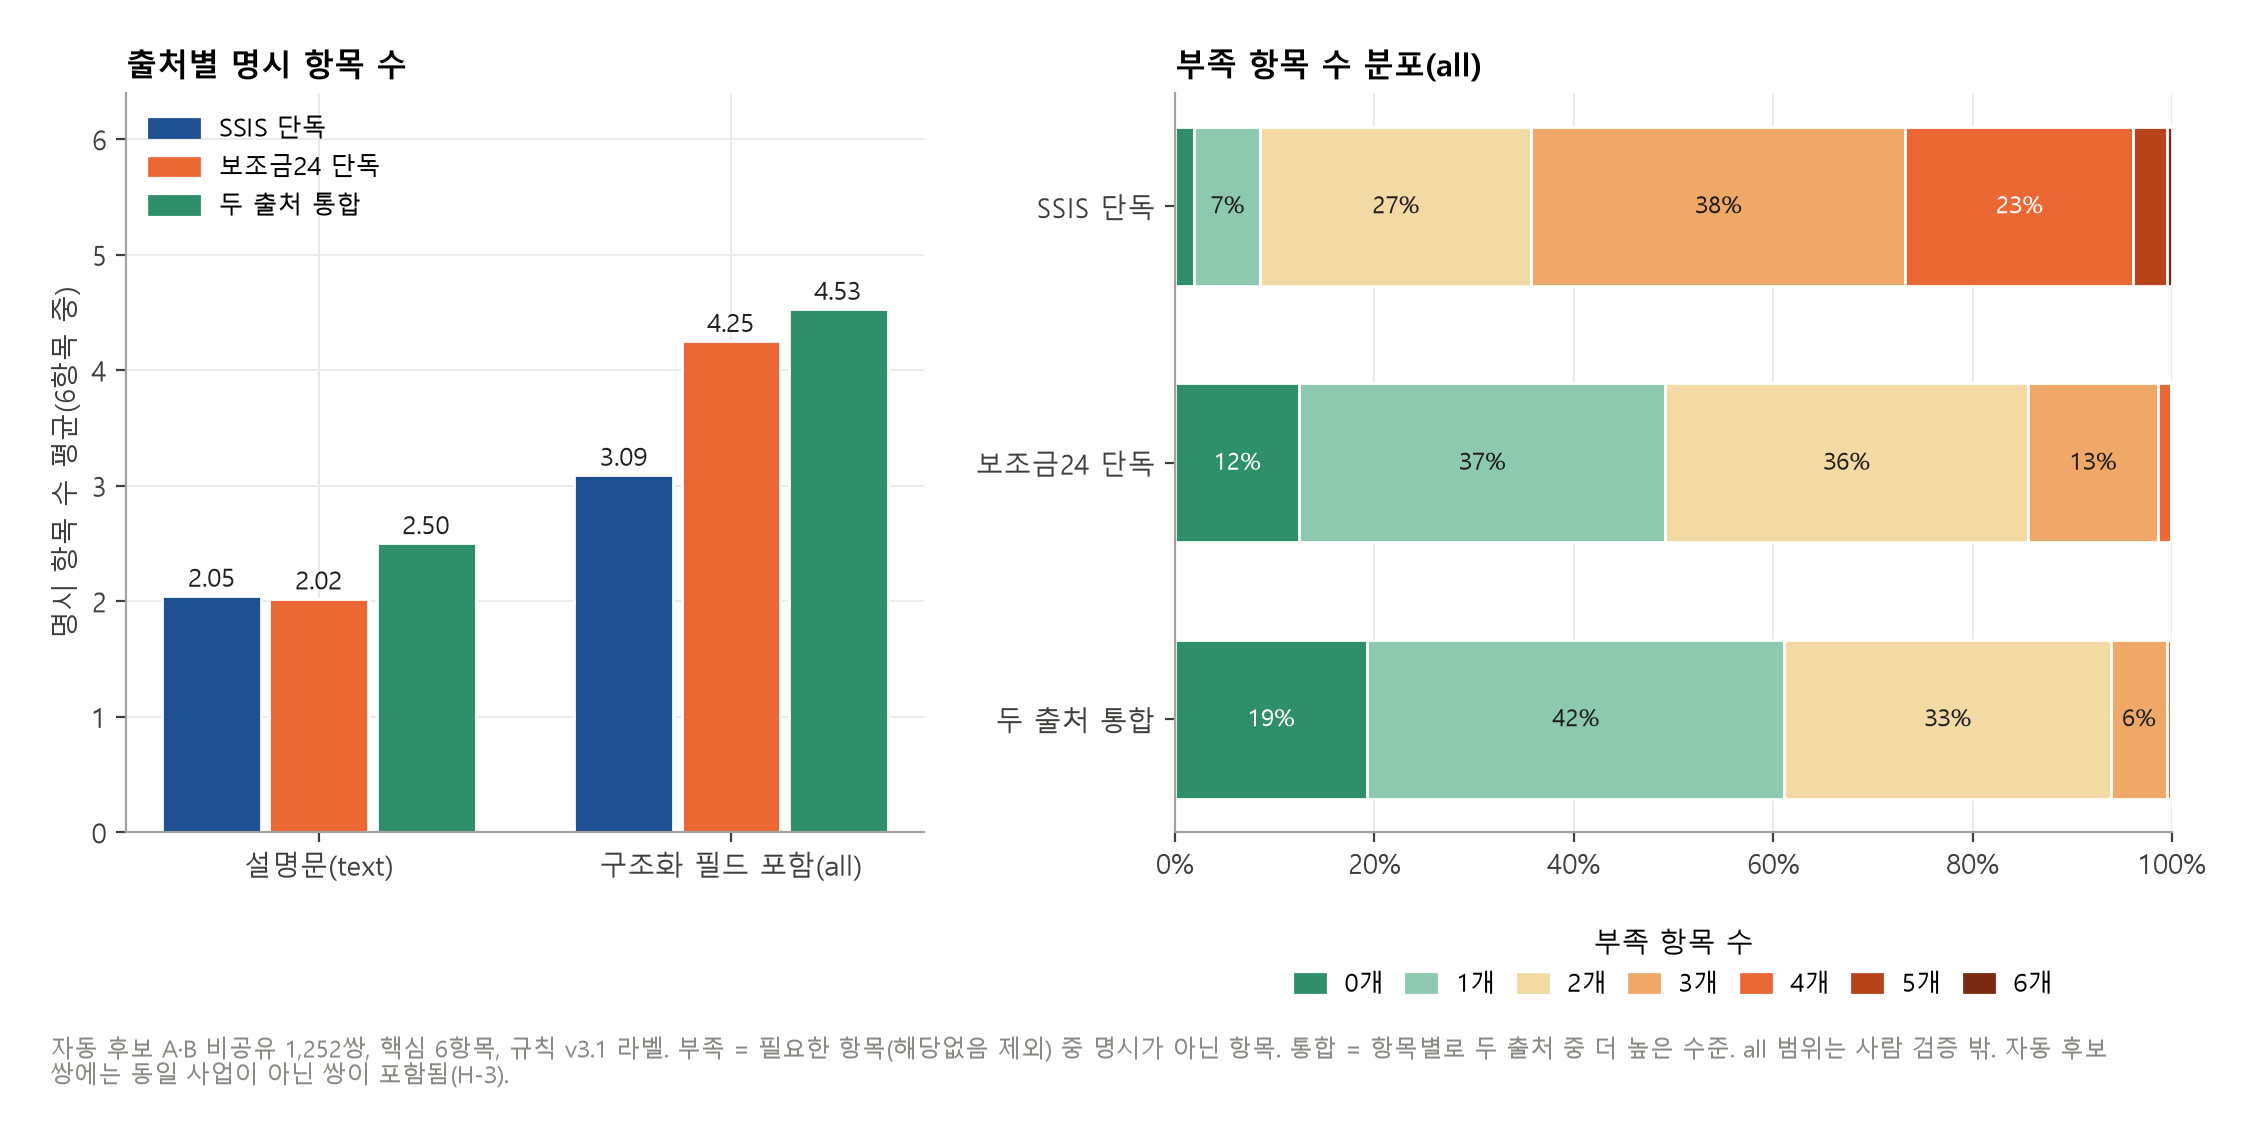

WindowsPath('outputs/04_q2/figures/final/05_service_completeness.png')

In [40]:
t1 = SM[(SM.population == "AB_nonshared") & (SM.variant == "main")]
disp(t1[["scope", "source", "n_pairs", "mean_applicable", "mean_explicit", "mean_short", "n_complete", "share_complete", "complete_ci_low", "complete_ci_high",
         "share_short_ge3", "share_complete_eligibility", "share_complete_application"]],
     "표 I-1. 출처별 완성도 — 자동 후보 A·B 비공유 쌍, 핵심 6항목(규칙 v3.1)",
     note="mean_explicit = 명시 항목 수 평균. share_complete = 필요한 항목이 모두 명시인 쌍 비율(Wilson 95% CI). share_short_ge3 = 부족 3항목 이상.")
dd = CT["svc_short_distribution"]
dd = dd[(dd.population == "AB_nonshared")]
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.28})
ax = axes[0]
for j, scope in enumerate(["text", "all"]):
    for i, s in enumerate(QC.SOURCES):
        r = sm_row("AB_nonshared", scope, s)
        x = j + (i - 1) * 0.26
        ax.bar(x, r.mean_explicit, width=0.24, color=SRC_C[s], edgecolor="white")
        ax.text(x, r.mean_explicit + 0.08, f"{r.mean_explicit:.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["설명문(text)", "구조화 필드 포함(all)"])
ax.set_ylim(0, 6.4); ax.set_ylabel("명시 항목 수 평균(6항목 중)"); ax.set_title("출처별 명시 항목 수")
ax.legend(handles=[Patch(color=SRC_C[s], label=SRC_KO[s]) for s in QC.SOURCES], loc="upper left")
ax = axes[1]
SHADE = ["#2f8f6b", "#8cc9ae", "#f3d9a4", "#f0a868", "#eb6834", "#b8431a", "#7a2a10"]
for i, s in enumerate(QC.SOURCES):
    g = dd[(dd.scope == "all") & (dd.source == s)].sort_values("n_short")
    left = 0.0
    for r in g.itertuples():
        ax.barh(i, r.share, left=left, color=SHADE[int(r.n_short)], edgecolor="white", height=0.62)
        if r.share >= 0.05:
            ax.text(left + r.share / 2, i, f"{100 * r.share:.0f}%", ha="center", va="center", fontsize=8.5, color="white" if r.n_short in (0, 4, 5, 6) else INK)
        left += r.share
ax.set_yticks(range(3)); ax.set_yticklabels([SRC_KO[s] for s in QC.SOURCES]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
ax.set_title("부족 항목 수 분포(all)")
ax.legend(handles=[Patch(color=SHADE[k], label=f"{k}개") for k in range(7)], ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.1), title="부족 항목 수", columnspacing=0.9, handlelength=1.2)
save_fig(fig, "05_service_completeness", f"자동 후보 A·B 비공유 {int(POPN['AB_nonshared']):,}쌍, 핵심 6항목, 규칙 v3.1 라벨. 부족 = 필요한 항목(해당없음 제외) 중 명시가 아닌 항목. "
         "통합 = 항목별로 두 출처 중 더 높은 수준. all 범위는 사람 검증 밖. 자동 후보 쌍에는 동일 사업이 아닌 쌍이 포함됨(H-3).", folder=FFIG)

In [41]:
A = {s: sm_row("AB_nonshared", "all", s) for s in QC.SOURCES}
Tx = {s: sm_row("AB_nonshared", "text", s) for s in QC.SOURCES}
assert A["union"].mean_explicit >= max(A["ssis"].mean_explicit, A["gov"].mean_explicit)
OBS["svc"] = "\n".join([
    f"- all 범위 명시 항목 수 평균: SSIS {A['ssis'].mean_explicit:.2f}, 보조금24 {A['gov'].mean_explicit:.2f}, 통합 {A['union'].mean_explicit:.2f}(6항목 중)",
    f"- 6항목 모두 명시: SSIS {kn(A['ssis'].n_complete, A['ssis'].n_pairs)}({PCT(A['ssis'].share_complete)}), 보조금24 {PCT(A['gov'].share_complete)}, 통합 {PCT(A['union'].share_complete)}(95% CI {ci2(A['union'].complete_ci_low, A['union'].complete_ci_high)})",
    f"- 부족 3항목 이상: SSIS {PCT(A['ssis'].share_short_ge3)}, 보조금24 {PCT(A['gov'].share_short_ge3)}, 통합 {PCT(A['union'].share_short_ge3)}",
    f"- 신청 4항목 모두 확인: SSIS {PCT(A['ssis'].share_complete_application)}, 보조금24 {PCT(A['gov'].share_complete_application)}, 통합 {PCT(A['union'].share_complete_application)}",
    f"- 자격 2항목 모두 확인: SSIS {PCT(A['ssis'].share_complete_eligibility)}, 보조금24 {PCT(A['gov'].share_complete_eligibility)}, 통합 {PCT(A['union'].share_complete_eligibility)}",
    f"- text 범위 명시 항목 수 평균: SSIS {Tx['ssis'].mean_explicit:.2f}, 보조금24 {Tx['gov'].mean_explicit:.2f}, 통합 {Tx['union'].mean_explicit:.2f}"])
INT["svc"] = "\n".join([
    "- 한 출처만으로 6항목이 모두 명시된 서비스는 소수",
    "- 통합 후에도 6항목 완비는 5쌍 중 1쌍 수준",
    "- 통합 후 남는 부족은 자격 정보(연령, 소득)에 집중"])
LIM["svc"] = "\n".join([
    "- 규칙 v3.1 라벨 기반 추정. 사람 금표준 대비 규칙 정확도는 H-4",
    "- 연령, 소득 미명시는 조건 자체가 없는 서비스를 포함할 수 있음(정보 누락과 구분 불가)",
    "- all 범위는 사람 검증 밖. '상시신청' 기본값 후보 포함(I-3에서 제외 민감도)"])
md("**관찰**\n" + OBS["svc"] + "\n\n**해석**\n" + INT["svc"] + "\n\n**한계**\n" + LIM["svc"])

**관찰**
- all 범위 명시 항목 수 평균: SSIS 3.09, 보조금24 4.25, 통합 4.53(6항목 중)
- 6항목 모두 명시: SSIS 24/1252(1.9%), 보조금24 12.5%, 통합 19.2%(95% CI 17.2~21.5%)
- 부족 3항목 이상: SSIS 64.3%, 보조금24 14.5%, 통합 6.2%
- 신청 4항목 모두 확인: SSIS 8.9%, 보조금24 69.3%, 통합 79.8%
- 자격 2항목 모두 확인: SSIS 22.2%, 보조금24 19.0%, 통합 25.5%
- text 범위 명시 항목 수 평균: SSIS 2.05, 보조금24 2.02, 통합 2.50

**해석**
- 한 출처만으로 6항목이 모두 명시된 서비스는 소수
- 통합 후에도 6항목 완비는 5쌍 중 1쌍 수준
- 통합 후 남는 부족은 자격 정보(연령, 소득)에 집중

**한계**
- 규칙 v3.1 라벨 기반 추정. 사람 금표준 대비 규칙 정확도는 H-4
- 연령, 소득 미명시는 조건 자체가 없는 서비스를 포함할 수 있음(정보 누락과 구분 불가)
- all 범위는 사람 검증 밖. '상시신청' 기본값 후보 포함(I-3에서 제외 민감도)

## I-2. 통합으로 추가 확보되는 정보
- 항목별: 한쪽만 명시한 쌍(상대 출처 사용자에게 추가되는 정보), 양쪽 모두 비명시인 쌍(통합해도 남는 부족)
- 서비스별: 통합 명시 수 − 단독 명시 수
- 분모: 통합 기준 필요한 쌍(해당없음 제외)

**표 I-2a. 항목별 통합 이득 — 자동 후보 A·B 비공유 쌍**

scope,item,n_needed,n_both,n_ssis_only,n_gov_only,n_neither,share_union,gain_for_ssis_user,gain_for_gov_user,share_neither
text,age,1252,511,95,51,595,0.525,0.041,0.076,0.475
text,income,1252,401,100,38,713,0.431,0.030,0.080,0.569
text,channel,1252,966,17,258,11,0.991,0.206,0.014,0.009
text,period,1127,18,134,68,907,0.195,0.060,0.119,0.805
text,documents,1131,59,247,123,702,0.379,0.109,0.218,0.621
text,contact,1252,7,6,32,1207,0.036,0.026,0.005,0.964
all,age,1252,511,95,51,595,0.525,0.041,0.076,0.475
all,income,1252,401,100,38,713,0.431,0.030,0.080,0.569
all,channel,1252,1099,4,149,0,1.000,0.119,0.003,0.000
all,period,1125,147,5,897,76,0.932,0.797,0.004,0.068


<span style='color:#8a8984;font-size:90%'>gain_for_ssis_user = SSIS 비명시이고 보조금24 명시인 쌍 비율. share_neither = 통합해도 명시가 아닌 쌍 비율.</span>

**표 I-2b. 서비스별 통합 이득(핵심 6항목)**

scope,reference,n_pairs,mean_gain_items,n_gain_ge1,share_gain_ge1,gain_ci_low,gain_ci_high,share_gain_ge2
text,vs_ssis,1252,0.455,485,0.387,0.361,0.415,0.060
text,vs_gov,1252,0.478,461,0.368,0.342,0.395,0.100
text,vs_better_single,1252,0.101,126,0.101,0.085,0.119,0.001
all,vs_ssis,1252,1.437,1098,0.877,0.858,0.894,0.491
all,vs_gov,1252,0.278,305,0.244,0.221,0.268,0.033
all,vs_better_single,1252,0.210,253,0.202,0.181,0.225,0.008


<span style='color:#8a8984;font-size:90%'>vs_ssis = SSIS만 볼 때 대비, vs_gov = 보조금24만 볼 때 대비, vs_better_single = 두 출처 중 명시가 더 많은 쪽 대비.</span>

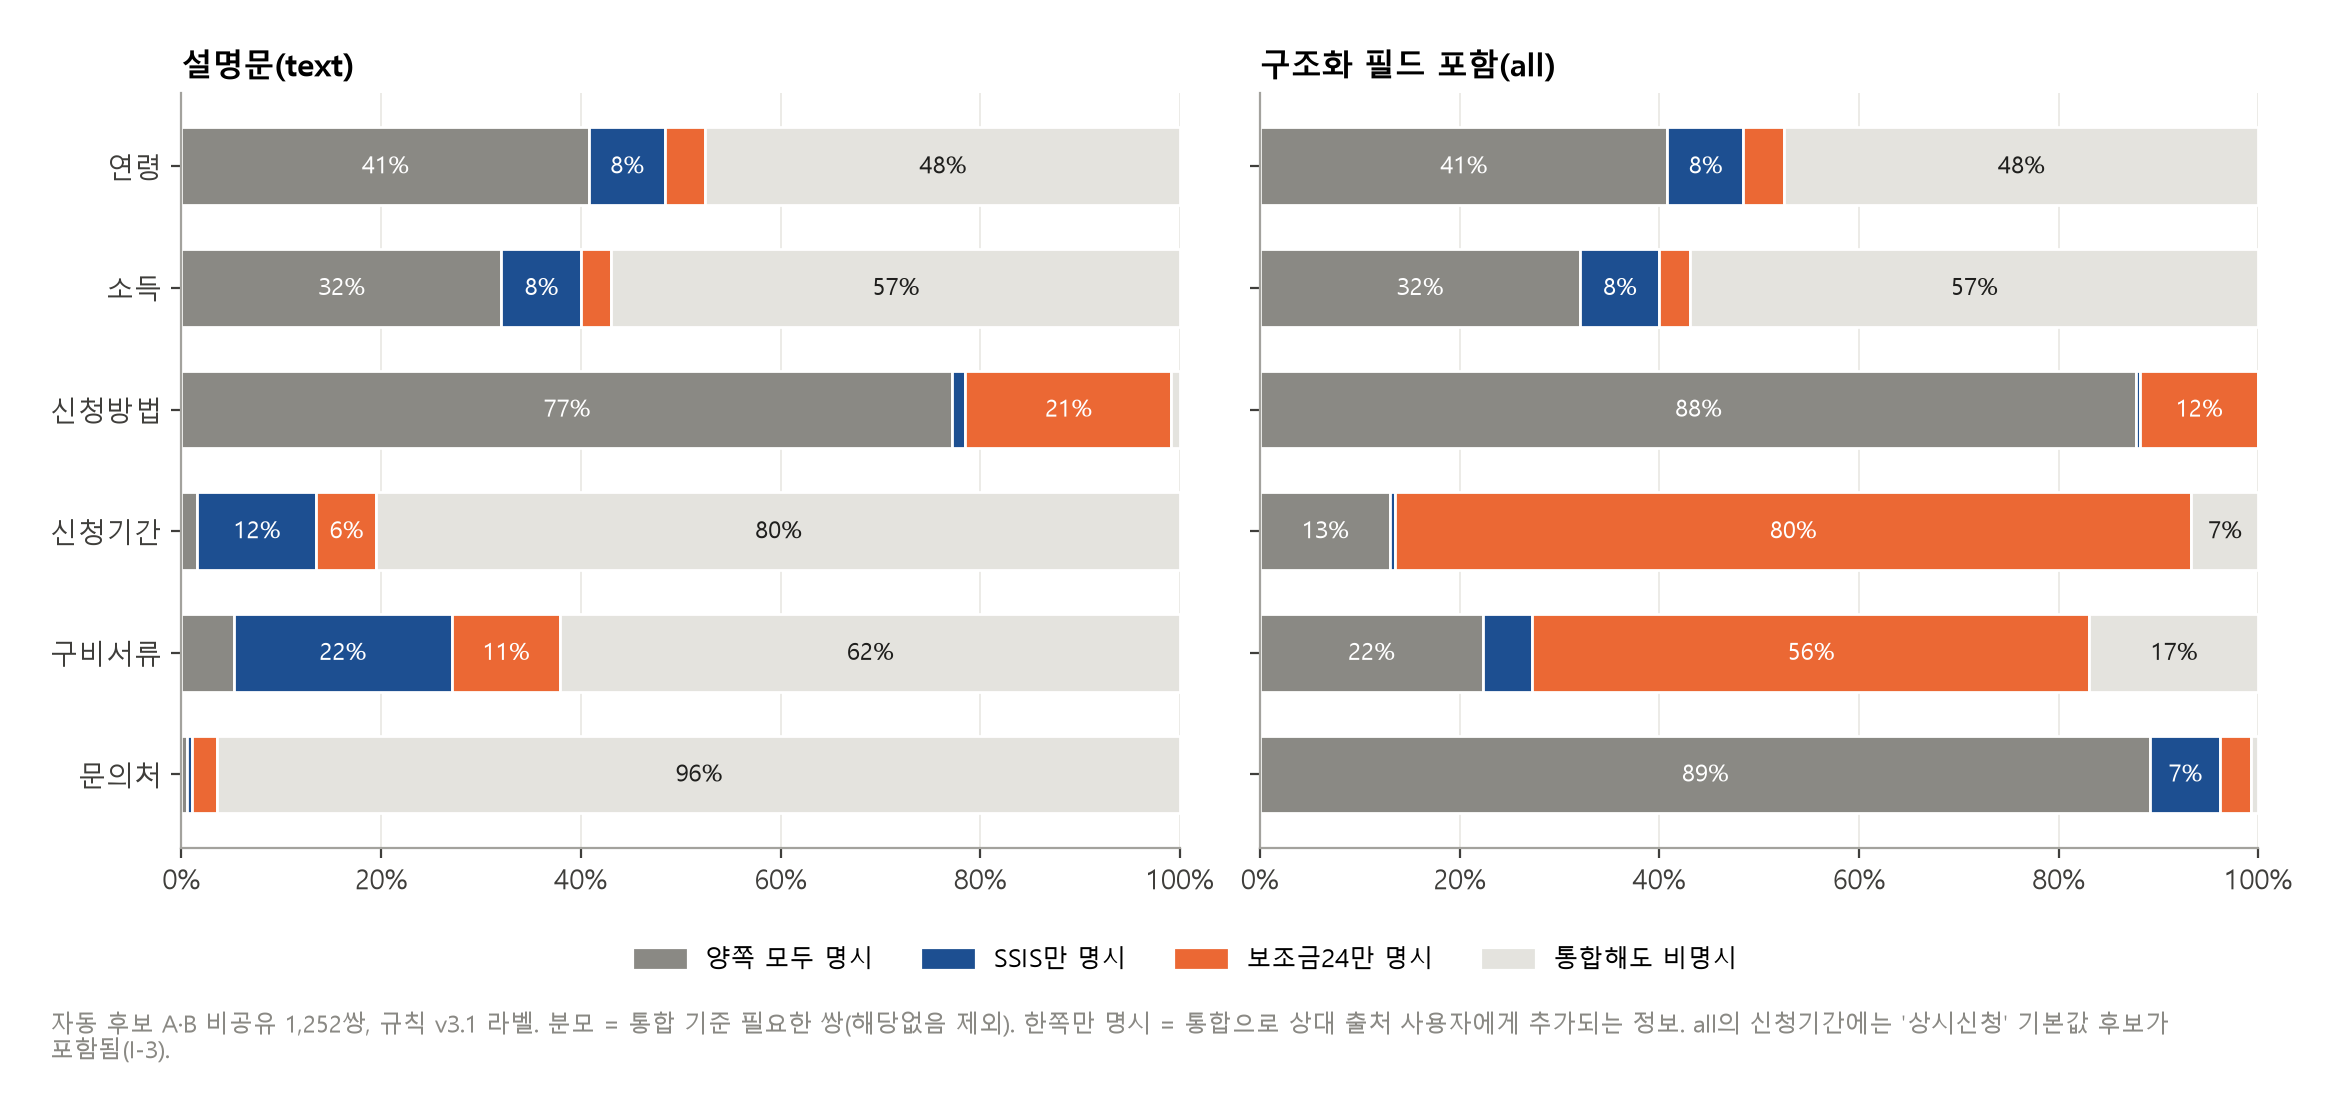

WindowsPath('outputs/04_q2/figures/final/06_integration_gain_by_item.png')

In [42]:
gi, gs = CT["svc_gain_by_item"], CT["svc_gain_by_service"]
g1 = gi[(gi.population == "AB_nonshared") & gi.core_metric & (gi.variant == "main")]
disp(g1[["scope", "item", "n_needed", "n_both", "n_ssis_only", "n_gov_only", "n_neither", "share_union", "gain_for_ssis_user", "gain_for_gov_user", "share_neither"]],
     "표 I-2a. 항목별 통합 이득 — 자동 후보 A·B 비공유 쌍", note="gain_for_ssis_user = SSIS 비명시이고 보조금24 명시인 쌍 비율. share_neither = 통합해도 명시가 아닌 쌍 비율.")
g2 = gs[(gs.population == "AB_nonshared") & (gs.variant == "main")]
disp(g2[["scope", "reference", "n_pairs", "mean_gain_items", "n_gain_ge1", "share_gain_ge1", "gain_ci_low", "gain_ci_high", "share_gain_ge2"]],
     "표 I-2b. 서비스별 통합 이득(핵심 6항목)", note="vs_ssis = SSIS만 볼 때 대비, vs_gov = 보조금24만 볼 때 대비, vs_better_single = 두 출처 중 명시가 더 많은 쪽 대비.")
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.9), sharey=True, gridspec_kw={"wspace": 0.08})
PARTS = [("n_both", "양쪽 모두 명시", "#8a8984"), ("n_ssis_only", "SSIS만 명시", C_DARK), ("n_gov_only", "보조금24만 명시", C_ORANGE), ("n_neither", "통합해도 비명시", "#e4e3de")]
for ax, scope, ttl in zip(axes, ["text", "all"], ["설명문(text)", "구조화 필드 포함(all)"]):
    for k, it in enumerate(ORDER_I):
        r = g1[(g1.scope == scope) & (g1["item"] == it)].iloc[0]
        left = 0.0
        for col, _, color in PARTS:
            v = r[col] / r.n_needed
            ax.barh(k, v, left=left, color=color, edgecolor="white", height=0.64)
            if v >= 0.06:
                ax.text(left + v / 2, k, f"{100 * v:.0f}%", ha="center", va="center", fontsize=8.5, color=INK if col == "n_neither" else "white")
            left += v
    ax.set_yticks(range(6)); ax.set_yticklabels([KO_I[i] for i in ORDER_I]); ax.set_xlim(0, 1); ax.set_title(ttl)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.legend(handles=[Patch(color=c, label=l) for _, l, c in PARTS], ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.04))
save_fig(fig, "06_integration_gain_by_item", f"자동 후보 A·B 비공유 {int(POPN['AB_nonshared']):,}쌍, 규칙 v3.1 라벨. 분모 = 통합 기준 필요한 쌍(해당없음 제외). "
         "한쪽만 명시 = 통합으로 상대 출처 사용자에게 추가되는 정보. all의 신청기간에는 '상시신청' 기본값 후보가 포함됨(I-3).", folder=FFIG)

In [43]:
ga = g1[g1.scope == "all"].set_index("item"); gt = g1[g1.scope == "text"].set_index("item")
sv = g2.set_index(["scope", "reference"])
assert (ga.n_both + ga.n_ssis_only + ga.n_gov_only + ga.n_neither == ga.n_needed).all()
OBS["gain"] = "\n".join([
    f"- SSIS만 보는 사용자가 통합으로 얻는 항목(all): 평균 {sv.loc[('all','vs_ssis'),'mean_gain_items']:.2f}개, 1개 이상 얻는 쌍 {PCT(sv.loc[('all','vs_ssis'),'share_gain_ge1'])}",
    f"  - 신청기간 {PCT(ga.loc['period','gain_for_ssis_user'])}, 구비서류 {PCT(ga.loc['documents','gain_for_ssis_user'])}, 신청방법 {PCT(ga.loc['channel','gain_for_ssis_user'])}",
    f"- 보조금24만 보는 사용자가 얻는 항목(all): 평균 {sv.loc[('all','vs_gov'),'mean_gain_items']:.2f}개, 1개 이상 얻는 쌍 {PCT(sv.loc[('all','vs_gov'),'share_gain_ge1'])}",
    f"  - 소득 {PCT(ga.loc['income','gain_for_gov_user'])}, 연령 {PCT(ga.loc['age','gain_for_gov_user'])}, 문의처 {PCT(ga.loc['contact','gain_for_gov_user'])}",
    f"- 더 나은 한 출처 대비 통합 이득(all): 1개 이상 {PCT(sv.loc[('all','vs_better_single'),'share_gain_ge1'])}(95% CI {ci2(sv.loc[('all','vs_better_single'),'gain_ci_low'], sv.loc[('all','vs_better_single'),'gain_ci_high'])})",
    f"- 통합해도 비명시(all): 소득 {PCT(ga.loc['income','share_neither'])}, 연령 {PCT(ga.loc['age','share_neither'])}, 구비서류 {PCT(ga.loc['documents','share_neither'])}, 신청기간 {PCT(ga.loc['period','share_neither'])}",
    f"- text 범위에서는 신청기간 {PCT(gt.loc['period','share_neither'])}, 문의처 {PCT(gt.loc['contact','share_neither'])}가 통합해도 비명시"])
INT["gain"] = "\n".join([
    "- 정보가 출처별로 나뉘어 있음: 신청 절차 정보는 보조금24 구조화 필드, 자격 정보와 문의처는 SSIS 쪽이 조금 더 많음",
    "- 이득은 비대칭: SSIS 사용자 쪽이 큼. 보조금24 사용자는 4쌍 중 1쌍에서 1항목 추가",
    "- 연령, 소득은 통합해도 절반가량 비명시 → 통합만으로 해결되지 않는 영역"])
LIM["gain"] = "\n".join([
    "- 한쪽만 명시한 쌍의 이득은 두 서비스가 동일 사업일 때만 성립(I-3 사람 확정 쌍 비교)",
    "- 보조금24 구조화 필드(all)의 화면 표시 여부와 정확성은 화면 점검 45건 범위에서만 확인(H-8-S3)",
    "- SSIS에는 신청기한, 구비서류 전용 필드가 없어 all 범위 차이 일부는 구조적"])
md("**관찰**\n" + OBS["gain"] + "\n\n**해석**\n" + INT["gain"] + "\n\n**한계**\n" + LIM["gain"])

**관찰**
- SSIS만 보는 사용자가 통합으로 얻는 항목(all): 평균 1.44개, 1개 이상 얻는 쌍 87.7%
  - 신청기간 79.7%, 구비서류 55.8%, 신청방법 11.9%
- 보조금24만 보는 사용자가 얻는 항목(all): 평균 0.28개, 1개 이상 얻는 쌍 24.4%
  - 소득 8.0%, 연령 7.6%, 문의처 7.0%
- 더 나은 한 출처 대비 통합 이득(all): 1개 이상 20.2%(95% CI 18.1~22.5%)
- 통합해도 비명시(all): 소득 56.9%, 연령 47.5%, 구비서류 16.9%, 신청기간 6.8%
- text 범위에서는 신청기간 80.5%, 문의처 96.4%가 통합해도 비명시

**해석**
- 정보가 출처별로 나뉘어 있음: 신청 절차 정보는 보조금24 구조화 필드, 자격 정보와 문의처는 SSIS 쪽이 조금 더 많음
- 이득은 비대칭: SSIS 사용자 쪽이 큼. 보조금24 사용자는 4쌍 중 1쌍에서 1항목 추가
- 연령, 소득은 통합해도 절반가량 비명시 → 통합만으로 해결되지 않는 영역

**한계**
- 한쪽만 명시한 쌍의 이득은 두 서비스가 동일 사업일 때만 성립(I-3 사람 확정 쌍 비교)
- 보조금24 구조화 필드(all)의 화면 표시 여부와 정확성은 화면 점검 45건 범위에서만 확인(H-8-S3)
- SSIS에는 신청기한, 구비서류 전용 필드가 없어 all 범위 차이 일부는 구조적

## I-3. 민감도 — 동일 사업 확인, A 등급, 기본값 제외, 부분 인정
- 사람 확정 동일 쌍: 자동 후보가 아닌 확인된 동일 사업에서 같은 방향인지
- A 등급: 쌍 집합을 A로 제한
- 기본값 제외: 보조금24 신청기한 '상시신청'(rule `gov_deadline_default`)을 비명시로 처리
- 부분 인정: 부분도 확인으로 계산

In [44]:
rows = []
for pop in ["AB_nonshared", "A_nonshared", "human_same", "human_same_AB"]:
    for var in (["main", "default_excluded", "partial_counted", "with_residence"] if pop == "AB_nonshared" else ["main", "default_excluded"]):
        r = {s: sm_row(pop, "all", s, var) for s in QC.SOURCES}
        gg = gs[(gs.population == pop) & (gs.scope == "all") & (gs.variant == (var if var == "default_excluded" else "main")) & (gs.reference == "vs_better_single")].iloc[0]
        rows.append({"population": QC.POP_KO[pop], "variant": QC.VAR_KO[var], "n_pairs": int(r["union"].n_pairs),
                     "mean_explicit_ssis": r["ssis"].mean_explicit, "mean_explicit_gov": r["gov"].mean_explicit, "mean_explicit_union": r["union"].mean_explicit,
                     "share_complete_ssis": r["ssis"].share_complete, "share_complete_gov": r["gov"].share_complete, "share_complete_union": r["union"].share_complete,
                     "union_ci_low": r["union"].complete_ci_low, "union_ci_high": r["union"].complete_ci_high,
                     "share_gain_vs_better_single": gg.share_gain_ge1 if var in ("main", "default_excluded") else np.nan})
t3s = save_final(pd.DataFrame(rows), "svc_sensitivity")
disp(t3s, "표 I-3. 완성도 민감도 — all 범위", note="share_gain_vs_better_single = 더 나은 한 출처 대비 통합으로 1항목 이상 늘어나는 쌍 비율. 부분 인정, 거주 포함 변형은 이득 열 생략.")
S3 = t3s.set_index(["population", "variant"])
order_ok = (t3s.mean_explicit_union >= t3s[["mean_explicit_ssis", "mean_explicit_gov"]].max(axis=1)).all() and (t3s.mean_explicit_gov > t3s.mean_explicit_ssis).all()
hs, de, a_ = S3.loc[(QC.POP_KO["human_same"], QC.VAR_KO["main"])], S3.loc[(QC.POP_KO["AB_nonshared"], QC.VAR_KO["default_excluded"])], S3.loc[(QC.POP_KO["A_nonshared"], QC.VAR_KO["main"])]
pc_ = S3.loc[(QC.POP_KO["AB_nonshared"], QC.VAR_KO["partial_counted"])]
dg = gi[(gi.population == "AB_nonshared") & (gi.scope == "all") & (gi.variant == "default_excluded")].set_index("item")
OBS["sens"] = "\n".join([
    f"- 모든 행에서 순서 동일: SSIS < 보조금24 ≤ 통합({'확인' if order_ok else '불일치 있음'})",
    f"- A 등급 {int(a_.n_pairs):,}쌍: 통합 6항목 완비 {PCT(a_.share_complete_union)}, 명시 평균 {a_.mean_explicit_union:.2f}(A·B {PCT(A['union'].share_complete)}, {A['union'].mean_explicit:.2f})",
    f"- 사람 확정 동일 {int(hs.n_pairs)}쌍: 명시 평균 SSIS {hs.mean_explicit_ssis:.2f}, 보조금24 {hs.mean_explicit_gov:.2f}, 통합 {hs.mean_explicit_union:.2f}, 통합 완비 {PCT(hs.share_complete_union)}(95% CI {ci2(hs.union_ci_low, hs.union_ci_high)})",
    f"- 기본값 제외: 보조금24 명시 평균 {A['gov'].mean_explicit:.2f} → {de.mean_explicit_gov:.2f}, 통합 완비 {PCT(A['union'].share_complete)} → {PCT(de.share_complete_union)}",
    f"  - 신청기간 통합 명시 {PCT(ga.loc['period','share_union'])} → {PCT(dg.loc['period','share_union'])}, 통합해도 비명시 {PCT(dg.loc['period','share_neither'])}",
    f"- 부분 인정: 통합 완비 {PCT(pc_.share_complete_union)}, 명시 평균 {pc_.mean_explicit_union:.2f}"])
INT["sens"] = "\n".join([
    "- 통합 우위의 방향은 등급, 동일 사업 확인, 기본값 처리, 부분 인정과 무관하게 유지",
    "- 크기는 '상시신청' 처리에 민감: 기본값이라면 신청기간은 통합 후에도 절반 이상 비명시",
    "- 사람 확정 쌍의 수치는 자동 후보와 비슷한 수준이나 표본이 작아 구간이 넓음"])
LIM["sens"] = "\n".join([
    f"- 사람 확정 동일 쌍 {int(hs.n_pairs)}쌍(A·B·C 혼합), 등급 안 무작위 표본이라 전체 대표성 없음",
    "- '상시신청'이 실제 상시 접수인 서비스도 있음(화면 점검은 규칙 가지별 15건)",
    "- 기본값 제외는 하한에 가까운 가정"])
md("**관찰**\n" + OBS["sens"] + "\n\n**해석**\n" + INT["sens"] + "\n\n**한계**\n" + LIM["sens"])

**표 I-3. 완성도 민감도 — all 범위**

population,variant,n_pairs,mean_explicit_ssis,mean_explicit_gov,mean_explicit_union,share_complete_ssis,share_complete_gov,share_complete_union,union_ci_low,union_ci_high,share_gain_vs_better_single
자동 후보 A·B 비공유(주),"기준(명시만, 핵심 6항목)",1252,3.093,4.252,4.530,0.019,0.125,0.192,0.172,0.215,0.202
자동 후보 A·B 비공유(주),'상시신청' 기본값 후보 제외,1252,3.093,3.728,4.081,0.019,0.073,0.123,0.106,0.142,0.174
자동 후보 A·B 비공유(주),부분도 확인으로 인정,1252,3.375,4.620,4.812,0.028,0.209,0.276,0.252,0.301,—
자동 후보 A·B 비공유(주),거주 포함 7항목(보조),1252,3.637,4.731,5.131,0.006,0.054,0.102,0.087,0.120,—
자동 후보 A 비공유(민감도),"기준(명시만, 핵심 6항목)",1026,3.099,4.263,4.539,0.019,0.121,0.184,0.162,0.209,0.202
자동 후보 A 비공유(민감도),'상시신청' 기본값 후보 제외,1026,3.099,3.740,4.091,0.019,0.068,0.112,0.094,0.133,0.177
사람 확정 동일(A·B·C),"기준(명시만, 핵심 6항목)",38,3.211,3.816,4.368,0.026,0.079,0.263,0.150,0.420,0.289
사람 확정 동일(A·B·C),'상시신청' 기본값 후보 제외,38,3.211,3.447,4.026,0.026,0.053,0.211,0.111,0.363,0.211
사람 확정 동일(A·B 비공유),"기준(명시만, 핵심 6항목)",22,3.091,3.818,4.409,0.000,0.045,0.273,0.132,0.482,0.318
사람 확정 동일(A·B 비공유),'상시신청' 기본값 후보 제외,22,3.091,3.455,4.045,0.000,0.045,0.227,0.101,0.434,0.227


<span style='color:#8a8984;font-size:90%'>share_gain_vs_better_single = 더 나은 한 출처 대비 통합으로 1항목 이상 늘어나는 쌍 비율. 부분 인정, 거주 포함 변형은 이득 열 생략.</span>

**관찰**
- 모든 행에서 순서 동일: SSIS < 보조금24 ≤ 통합(확인)
- A 등급 1,026쌍: 통합 6항목 완비 18.4%, 명시 평균 4.54(A·B 19.2%, 4.53)
- 사람 확정 동일 38쌍: 명시 평균 SSIS 3.21, 보조금24 3.82, 통합 4.37, 통합 완비 26.3%(95% CI 15.0~42.0%)
- 기본값 제외: 보조금24 명시 평균 4.25 → 3.73, 통합 완비 19.2% → 12.3%
  - 신청기간 통합 명시 93.2% → 43.8%, 통합해도 비명시 56.2%
- 부분 인정: 통합 완비 27.6%, 명시 평균 4.81

**해석**
- 통합 우위의 방향은 등급, 동일 사업 확인, 기본값 처리, 부분 인정과 무관하게 유지
- 크기는 '상시신청' 처리에 민감: 기본값이라면 신청기간은 통합 후에도 절반 이상 비명시
- 사람 확정 쌍의 수치는 자동 후보와 비슷한 수준이나 표본이 작아 구간이 넓음

**한계**
- 사람 확정 동일 쌍 38쌍(A·B·C 혼합), 등급 안 무작위 표본이라 전체 대표성 없음
- '상시신청'이 실제 상시 접수인 서비스도 있음(화면 점검은 규칙 가지별 15건)
- 기본값 제외는 하한에 가까운 가정

## I-4. 청년 대상 서비스(Q1 엄격 S2)
- 연결: Q1 엄격 S2 676건과 Q2 자동 후보를 `servId`로 결합
- 비교: 엄격 S2 대 그 외, Q21 수요 영역별
- 영역: 한 서비스가 여러 영역에 속할 수 있음. 20쌍 미만 영역은 참고만

**표 I-4a. 자동 후보 등급 분포 — 전체 대 엄격 S2**

group,n_services,n_tier_A,n_tier_B,n_tier_C,n_tier_U,n_AB_nonshared,share_AB_nonshared,ci_low,ci_high,share_tier_U
all_ssis,5288,1094,245,876,3073,1252,0.237,0.225,0.248,0.581
youth_S2_strict,676,152,39,94,391,184,0.272,0.240,0.307,0.578
other,4612,942,206,782,2682,1068,0.232,0.220,0.244,0.582


<span style='color:#8a8984;font-size:90%'>등급은 자동 후보 기준. U = 자동 후보 없음(보조금24에 없다는 뜻 아님).</span>

**표 I-4b. 영역별 완성도 — 엄격 S2 ∩ A·B 비공유 쌍, all**

area_label,n_supply_S2,n_pairs,small_n,mean_explicit_ssis,mean_explicit_gov,mean_explicit_union,share_complete_ssis,share_complete_gov,share_complete_union,share_eligibility_union,share_application_union,gain_vs_better_single
② 일상생활 회복,3,1,True,3.000,2.000,3.000,0.000,0.000,0.000,0.000,0.000,0.000
③ 혼자 하는 활동,46,15,True,3.800,5.067,5.267,0.133,0.333,0.467,0.600,0.733,0.133
⑤ 전문 상담·치료,19,10,True,3.100,3.100,3.700,0.000,0.000,0.000,0.200,0.100,0.200
⑥ 또래·멘토 상담,4,0,True,—,—,—,—,—,—,—,—,—
⑦ 교육·학습,81,31,False,3.581,4.806,5.032,0.000,0.194,0.290,0.452,0.710,0.129
⑧ 취업·일 경험,203,50,False,3.480,4.880,5.120,0.000,0.160,0.300,0.480,0.680,0.220
⑩ 경제적 지원,50,21,False,3.619,4.619,5.095,0.048,0.095,0.429,0.571,0.762,0.333
⑪ 주거,147,51,False,4.020,5.196,5.549,0.000,0.392,0.627,0.824,0.745,0.314
⑤+⑥ 상담(합산),21,10,True,3.100,3.100,3.700,0.000,0.000,0.000,0.200,0.100,0.200
엄격 S2 전체,676,184,False,3.679,4.886,5.179,0.033,0.288,0.429,0.576,0.717,0.245


<span style='color:#8a8984;font-size:90%'>n_supply_S2 = Q1 엄격 S2 공급 후보 수, n_pairs = 그중 A·B 비공유 후보가 있는 쌍. gain_vs_better_single = 통합 명시 평균 − 더 나은 한 출처 명시 평균.</span>

**표 I-4c. 영역별 통합 후 부족 비율(항목별, all)**

area_label,연령,소득,신청방법,신청기간,구비서류,문의처
② 일상생활 회복,0.000,1.000,0.000,1.000,1.000,0.000
③ 혼자 하는 활동,0.000,0.400,0.000,0.133,0.200,0.000
⑤ 전문 상담·치료,0.000,0.800,0.000,0.800,0.700,0.000
⑤+⑥ 상담(합산),0.000,0.800,0.000,0.800,0.700,0.000
⑦ 교육·학습,0.000,0.548,0.000,0.233,0.133,0.000
⑧ 취업·일 경험,0.000,0.520,0.000,0.200,0.160,0.000
⑩ 경제적 지원,0.000,0.429,0.000,0.211,0.105,0.000
⑪ 주거,0.000,0.176,0.000,0.157,0.118,0.000
엄격 S2 전체,0.000,0.424,0.000,0.152,0.185,0.005


<span style='color:#8a8984;font-size:90%'>값 = 통합해도 명시가 아닌 쌍 / 필요한 쌍.</span>

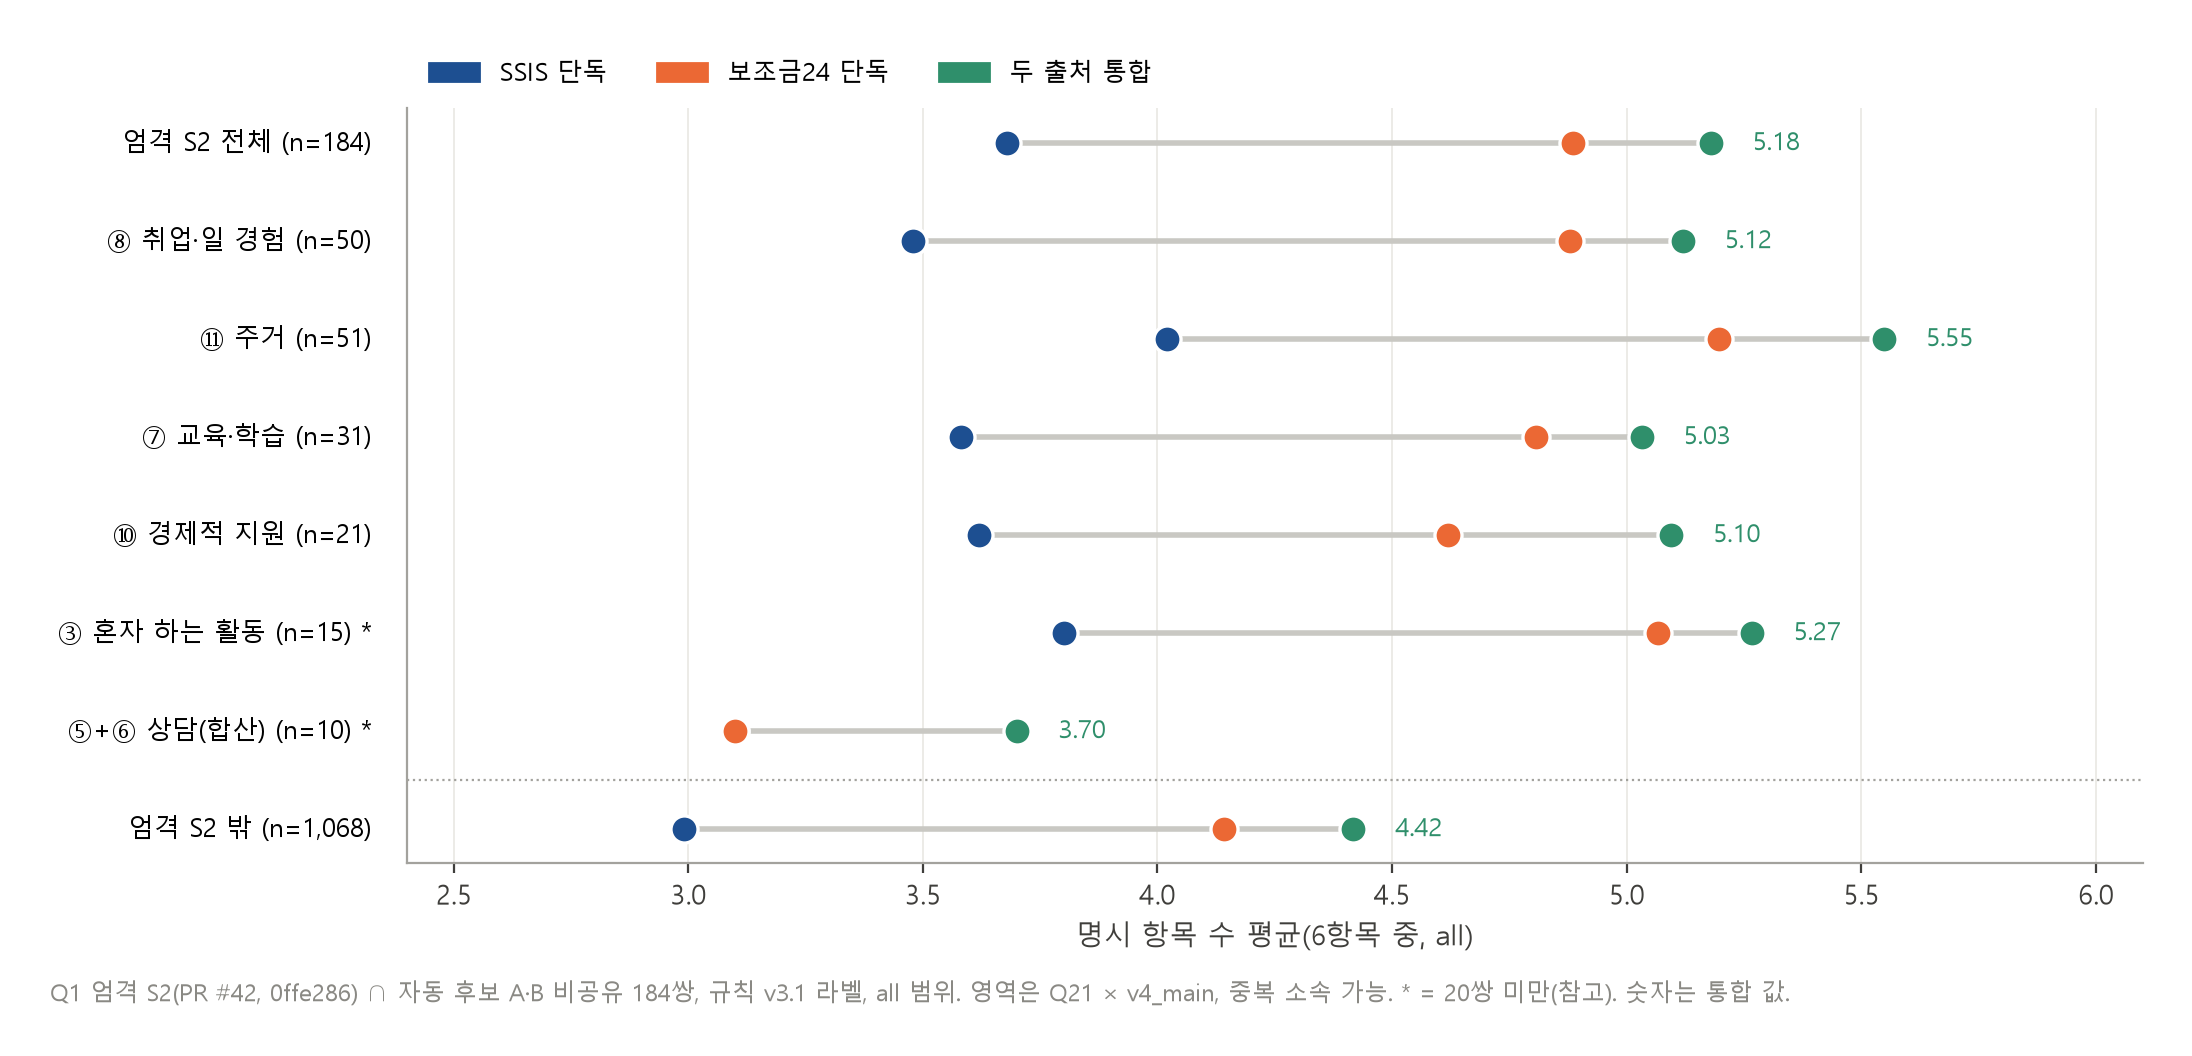

WindowsPath('outputs/04_q2/figures/final/07_youth_area_completeness.png')

In [45]:
cov, ya, yi = CT["youth_match_coverage"], CT["youth_area_completeness"], CT["youth_area_item_short"]
disp(cov, "표 I-4a. 자동 후보 등급 분포 — 전체 대 엄격 S2", drop=["note"], note="등급은 자동 후보 기준. U = 자동 후보 없음(보조금24에 없다는 뜻 아님).")
ya_all = ya[(ya.scope == "all")]
disp(ya_all[ya_all.variant.eq("main")][["area_label", "n_supply_S2", "n_pairs", "small_n", "mean_explicit_ssis", "mean_explicit_gov", "mean_explicit_union", "share_complete_ssis",
             "share_complete_gov", "share_complete_union", "share_eligibility_union", "share_application_union", "gain_vs_better_single"]],
     "표 I-4b. 영역별 완성도 — 엄격 S2 ∩ A·B 비공유 쌍, all", note="n_supply_S2 = Q1 엄격 S2 공급 후보 수, n_pairs = 그중 A·B 비공유 후보가 있는 쌍. gain_vs_better_single = 통합 명시 평균 − 더 나은 한 출처 명시 평균.")
yi_all = yi[(yi.scope == "all") & yi.n_pairs.gt(0)].pivot(index="area_label", columns="item", values="share_short_union")[ORDER_I].rename(columns=KO_I).reset_index()
disp(yi_all, "표 I-4c. 영역별 통합 후 부족 비율(항목별, all)", note="값 = 통합해도 명시가 아닌 쌍 / 필요한 쌍.")
AREAS_FIG = ["youth_S2_AB", "q21_08", "q21_11", "q21_07", "q21_10", "q21_03", "counsel_05_06"]
ym = ya_all[ya_all.variant.eq("main")].set_index("area")
fig, ax = plt.subplots(figsize=(11.2, 4.9))
NY = sm_row("nonyouth_AB", "all", "union")
for k, a in enumerate(AREAS_FIG + ["nonyouth"]):
    if a == "nonyouth":
        v = {s: sm_row("nonyouth_AB", "all", s).mean_explicit for s in QC.SOURCES}; lab = f"엄격 S2 밖 (n={int(NY.n_pairs):,})"
    else:
        r = ym.loc[a]; v = {s: r[f"mean_explicit_{s}"] for s in QC.SOURCES}; lab = f"{r.area_label} (n={int(r.n_pairs)})" + (" *" if r.small_n else "")
    ax.plot([min(v.values()), max(v.values())], [k, k], color="#c9c8c3", lw=2, zorder=1)
    for s in QC.SOURCES:
        ax.scatter(v[s], k, s=95, color=SRC_C[s], zorder=3, edgecolor="white", linewidth=1.2)
    ax.text(max(v.values()) + 0.09, k, f"{v['union']:.2f}", va="center", fontsize=9, color=C_UNION)
    ax.text(-0.02, k, lab, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9.5)
ax.set_yticks([]); ax.invert_yaxis(); ax.set_xlim(2.4, 6.1); ax.set_xlabel("명시 항목 수 평균(6항목 중, all)")
ax.axhline(len(AREAS_FIG) - 0.5, color="#a3a29d", lw=0.8, ls=":")
ax.legend(handles=[Patch(color=SRC_C[s], label=SRC_KO[s]) for s in QC.SOURCES], loc="lower left", ncol=3, bbox_to_anchor=(0, 1.0))
save_fig(fig, "07_youth_area_completeness", f"Q1 엄격 S2(PR #42, 0ffe286) ∩ 자동 후보 A·B 비공유 {int(POPN['youth_S2_AB'])}쌍, 규칙 v3.1 라벨, all 범위. 영역은 Q21 × v4_main, 중복 소속 가능. "
         "* = 20쌍 미만(참고). 숫자는 통합 값.", folder=FFIG)

In [46]:
cv = cov.set_index("group")
Y = {s: sm_row("youth_S2_AB", "all", s) for s in QC.SOURCES}; N = {s: sm_row("nonyouth_AB", "all", s) for s in QC.SOURCES}
YD = sm_row("youth_S2_AB", "all", "union", "default_excluded"); YA = sm_row("youth_S2_A", "all", "union")
yg = gs[(gs.population == "youth_S2_AB") & (gs.scope == "all") & (gs.variant == "main")].set_index("reference")
big = ym.loc[[a for a in AREAS_FIG[1:] if not ym.loc[a, "small_n"]]].sort_values("gain_vs_better_single", ascending=False)
yis = yi[(yi.scope == "all") & (yi.area == "youth_S2_AB")].set_index("item")
co = ym.loc["counsel_05_06"]
Y5, N5 = sm_row("youth_S2_AB", "all", "union", "without_age"), sm_row("nonyouth_AB", "all", "union", "without_age")
OBS["youth"] = "\n".join([
    f"- 엄격 S2 {int(cv.loc['youth_S2_strict','n_services'])}건 중 A·B 비공유 후보 {int(cv.loc['youth_S2_strict','n_AB_nonshared'])}건({PCT(cv.loc['youth_S2_strict','share_AB_nonshared'])}), 자동 후보 없음(U) {PCT(cv.loc['youth_S2_strict','share_tier_U'])}. 그 외 서비스는 {PCT(cv.loc['other','share_AB_nonshared'])}, {PCT(cv.loc['other','share_tier_U'])}",
    f"- 명시 항목 수 평균(all): 엄격 S2 SSIS {Y['ssis'].mean_explicit:.2f}, 보조금24 {Y['gov'].mean_explicit:.2f}, 통합 {Y['union'].mean_explicit:.2f}. 그 외 {N['ssis'].mean_explicit:.2f}, {N['gov'].mean_explicit:.2f}, {N['union'].mean_explicit:.2f}",
    f"- 통합 6항목 완비: 엄격 S2 {PCT(Y['union'].share_complete)}(95% CI {ci2(Y['union'].complete_ci_low, Y['union'].complete_ci_high)}), 그 외 {PCT(N['union'].share_complete)}",
    f"- 자격 2항목 확인(통합): 엄격 S2 {PCT(Y['union'].share_complete_eligibility)}, 그 외 {PCT(N['union'].share_complete_eligibility)}",
    f"- 연령 제외 5항목(통합): 명시 평균 엄격 S2 {Y5.mean_explicit:.2f}, 그 외 {N5.mean_explicit:.2f}. 5항목 완비 {PCT(Y5.share_complete)} 대 {PCT(N5.share_complete)}",
    f"- SSIS만 볼 때 대비 1항목 이상 이득 {PCT(yg.loc['vs_ssis','share_gain_ge1'])}, 더 나은 한 출처 대비 {PCT(yg.loc['vs_better_single','share_gain_ge1'])}",
    f"- 통합 후 부족(엄격 S2): 소득 {PCT(yis.loc['income','share_short_union'])}, 구비서류 {PCT(yis.loc['documents','share_short_union'])}, 신청기간 {PCT(yis.loc['period','share_short_union'])}, 연령 {PCT(yis.loc['age','share_short_union'])}",
    "- 영역별 통합 이득(더 나은 한 출처 대비 명시 평균 증가): " + ", ".join(f"{r.area_label} +{r.gain_vs_better_single:.2f}(n={int(r.n_pairs)})" for r in big.itertuples()),
    f"- 상담(⑤+⑥) {int(co.n_pairs)}쌍: 통합 명시 평균 {co.mean_explicit_union:.2f}, 6항목 완비 {int(co.n_complete_union)}쌍(참고, 표본 작음)",
    f"- 민감도: A 등급 통합 완비 {PCT(YA.share_complete)}, 기본값 제외 {PCT(YD.share_complete)}"])
INT["youth"] = "\n".join([
    "- 청년 대상 서비스에서도 출처별 분산과 통합 이득이 같은 방향으로 나타남",
    "- 완성도 수준이 전체보다 높은 것은 대부분 연령 항목 때문(엄격 S2는 연령 근거로 정의). 연령을 빼면 차이가 크게 줄어듦",
    "- 통합 후에도 절반 이상은 6항목 미완비, 남는 부족은 소득 기준에 집중",
    "- 경제적 지원, 주거 영역에서 통합 이득이 상대적으로 큼"])
LIM["youth"] = "\n".join([
    f"- 엄격 S2의 {PCT(1 - cv.loc['youth_S2_strict','share_AB_nonshared'])}는 A·B 후보가 없어 이 분석 밖(통합 효과 미측정)",
    "- 영역별 쌍 수 10~51, 구간 넓음. 상담, 일상 회복 영역은 판단 불가 수준",
    "- 엄격 S2는 연령 근거로 정의되어 연령 명시율이 구조적으로 높음. 수준 비교는 연령 제외 5항목 값 기준으로 해석",
    "- Q1 PR #42 미병합, 사람 검수 반영은 S2 676건 중 39건"])
md("**관찰**\n" + OBS["youth"] + "\n\n**해석**\n" + INT["youth"] + "\n\n**한계**\n" + LIM["youth"])

**관찰**
- 엄격 S2 676건 중 A·B 비공유 후보 184건(27.2%), 자동 후보 없음(U) 57.8%. 그 외 서비스는 23.2%, 58.2%
- 명시 항목 수 평균(all): 엄격 S2 SSIS 3.68, 보조금24 4.89, 통합 5.18. 그 외 2.99, 4.14, 4.42
- 통합 6항목 완비: 엄격 S2 42.9%(95% CI 36.0~50.2%), 그 외 15.2%
- 자격 2항목 확인(통합): 엄격 S2 57.6%, 그 외 19.9%
- 연령 제외 5항목(통합): 명시 평균 엄격 S2 4.18, 그 외 3.97. 5항목 완비 42.9% 대 32.6%
- SSIS만 볼 때 대비 1항목 이상 이득 89.7%, 더 나은 한 출처 대비 24.5%
- 통합 후 부족(엄격 S2): 소득 42.4%, 구비서류 18.5%, 신청기간 15.2%, 연령 0.0%
- 영역별 통합 이득(더 나은 한 출처 대비 명시 평균 증가): ⑩ 경제적 지원 +0.33(n=21), ⑪ 주거 +0.31(n=51), ⑧ 취업·일 경험 +0.22(n=50), ⑦ 교육·학습 +0.13(n=31)
- 상담(⑤+⑥) 10쌍: 통합 명시 평균 3.70, 6항목 완비 0쌍(참고, 표본 작음)
- 민감도: A 등급 통합 완비 43.9%, 기본값 제외 27.2%

**해석**
- 청년 대상 서비스에서도 출처별 분산과 통합 이득이 같은 방향으로 나타남
- 완성도 수준이 전체보다 높은 것은 대부분 연령 항목 때문(엄격 S2는 연령 근거로 정의). 연령을 빼면 차이가 크게 줄어듦
- 통합 후에도 절반 이상은 6항목 미완비, 남는 부족은 소득 기준에 집중
- 경제적 지원, 주거 영역에서 통합 이득이 상대적으로 큼

**한계**
- 엄격 S2의 72.8%는 A·B 후보가 없어 이 분석 밖(통합 효과 미측정)
- 영역별 쌍 수 10~51, 구간 넓음. 상담, 일상 회복 영역은 판단 불가 수준
- 엄격 S2는 연령 근거로 정의되어 연령 명시율이 구조적으로 높음. 수준 비교는 연령 제외 5항목 값 기준으로 해석
- Q1 PR #42 미병합, 사람 검수 반영은 S2 676건 중 39건

## I-5. 양쪽 내용의 일치, 보완, 충돌
- 추출값 비교(규칙): 연령 경계, 소득 기준, 신청 경로, 신청 기한, 전화번호
- 분류: 일치, 보완(한쪽 값이 다른 쪽을 포함), 상이 후보, 한쪽만 값
- 자동 후보 쌍의 상이 후보는 충돌 확정 아님(동일 사업 미확인)
- 사람 확정 동일 쌍: 보완, 상이 후보로 표시된 38행을 원문 대조 후 사람 검수로 확정(`content_conflict_review.csv`)
- 기록 구분: 수집 당시 플랫폼 간 차이(`platform_diff`), 공식 기준 확인(`official_*`), 최종 판정(`final_verdict`)
- 전화번호 차이는 충돌로 보지 않음. 공식 자료로 확인되지 않은 추가 신청 경로는 확인 불가

### Decision Box 17 — 사후 매칭 정정
- **문제:** 내용 대조에서 사람 확정 동일 쌍 1건이 지역 범위가 다른 사업으로 확인됨
- **선택:** 검수 원본과 조정 판정표는 그대로 두고 `match_post_review.csv`로 이 분석 층에서만 '다름' 처리
- **근거:** 보조금24 쪽은 구 광주 권역, 중위소득 120%, 장애인정책과. 같은 조건의 SSIS 서비스가 따로 있고 A 등급으로 연결됨
- **영향:** 사람 확정 동일 39쌍 → 38쌍, B 등급 동일 11/15 → 10/15. H-3 표는 검수 판정 그대로의 기록으로 유지

**표 I-5a. 사후 정정 반영 매칭 정확도**

tier,n_confirmed,n_same,n_same_before,n_post_review,acc,acc_ci_low,acc_ci_high,acc_before
A,15,13,13,0,0.867,0.621,0.963,0.867
B,15,10,11,1,0.667,0.417,0.848,0.733
C,27,15,15,0,0.556,0.373,0.724,0.556
U,15,1,1,0,0.067,0.012,0.298,0.067
AB_weighted,30,23,24,1,0.820,0.637,0.924,0.832


<span style='color:#8a8984;font-size:90%'>acc_before = 검수 판정 그대로(H-3, H-8-S5). AB_weighted = 층별 Jeffreys 사후 MC 중앙값과 95% 구간.</span>

**표 I-5b. 추출값 비교 — 모집단 × 항목**

population_label,item,n_pairs,n_일치,n_보완(포함 관계),n_상이 후보,n_한쪽만 값,n_기본값 후보만,n_양쪽 값 없음,n_both_valued,share_differ_of_both,identity_checked
자동 후보 A·B 비공유(주),age,1252,295,0,54,123,0,780,349,0.155,False
자동 후보 A·B 비공유(주),income,1252,208,72,13,124,0,835,293,0.044,False
자동 후보 A·B 비공유(주),channel,1252,708,313,72,158,0,1,1093,0.066,False
자동 후보 A·B 비공유(주),period,1252,26,7,10,357,645,207,43,0.233,False
자동 후보 A·B 비공유(주),contact,1252,667,136,362,70,0,17,1165,0.311,False
자동 후보 A 비공유(민감도),age,1026,238,0,46,91,0,651,284,0.162,False
자동 후보 A 비공유(민감도),income,1026,162,63,10,98,0,693,235,0.043,False
자동 후보 A 비공유(민감도),channel,1026,594,260,55,117,0,0,909,0.061,False
자동 후보 A 비공유(민감도),period,1026,24,6,9,302,525,160,39,0.231,False
자동 후보 A 비공유(민감도),contact,1026,552,109,289,59,0,17,950,0.304,False


<span style='color:#8a8984;font-size:90%'>share_differ_of_both = 상이 후보 / 양쪽 모두 값이 뽑힌 쌍. identity_checked=False는 동일 사업 여부 미확인.</span>

... (4 outputs left out)

item,final_verdict,ssis_name,ssis_value,gov_value,official_finding,official_checked_at
연령,실제 충돌,아동수당 지급,NA ~ 8,NA ~ 7,"2026년 최신 기준은 만 9세 미만. SSIS와 일치, 보조금24의 만 8세 미만은 이전 기준",2026-11-12
신청방법,확인 불가,산림복지서비스이용권,방문,"온라인, 우편","2026년 공식 모집 공고 기준 온라인, 우편 신청 가능(보조금24와 일치). SSIS의 주민센터, 진흥원 신청은 확인되지 않음",2026-11-12
신청방법,확인 불가,장수수당 지급,방문,신청불필요,방문 신청 안내와 신규 신청 불가 안내가 상충. 확인 불가,2026-11-12
소득,확인 불가,저소득한부모가족지원사업(명절위문금),"기초수급, 중위52%, 중위65%",중위63%,"소득 기준 52%, 63%, 65% 혼재. 해당 사업의 최신 기준 확인 불가",2026-11-12
신청기간,실제 충돌,출산축하금 및 장려금 지원,90일이내,"6개월이내, 상시(필드 기본값 후보)","최신 조례 기준 출생, 입양신고일부터 6개월 이내 신청. 보조금24 본문과 일치, SSIS의 90일 이내는 이전 기준",2026-11-12


<span style='color:#8a8984;font-size:90%'>양쪽 원문과 출처 URL은 content_cases_human_same.csv(ssis_text, gov_text, ssis_url, gov_url).</span>

**연령 — 아동수당 지급**
- 수집 당시 차이: 연령 상한 상이: SSIS 만 9세 미만, 보조금24 만 8세 미만
- 공식 기준 확인(2026-11-12): 2026년 최신 기준은 만 9세 미만. SSIS와 일치, 보조금24의 만 8세 미만은 이전 기준
- SSIS `WLF00001171`: [target] 만 9세미만 아동에게 지급합니다. / [criteria] 대한민국 국적을 보유한 아동에게 지급합니다. 「국적법」에 따른 복수국적자 포함 「난민법」에 따른 난민인정자 포함 * 단, 난민인정 신청에 대한 심사진행 중인 경우 등은 제외 「재한외국인처우기본법」에 따른 특별기여자 「주민등록법」에 따른 주민등록번호가 정상적으로 부여된 아동에게 지원합니다. 사회복지 전산관리번호(의료급여 전산관리번호) 부여 대상자 포함 「주민등록법」에 따른 거주불명자 중 실제
  - 출처: https://www.bokjiro.go.kr/ssis-tbu/twataa/wlfareInfo/moveTWAT52011M.do?wlfareInfoId=WLF00001171&wlfareInfoReldBztpCd=01
- 보조금24 `135200000120`: [target] ○ 만 8세 미만 모든 아동에게 아동수당을 지급 - 대한민국 국적을 보유한 아동 ᆞ 부모가 외국인이어도 아동이 한국 국적이면 요건 충족 ᆞ 국적법에 따른 복수국적자 포함 ᆞ 난민법에 따른 난민 인정 아동 포함 ᆞ 「재한외국인처우기본법」에 따른 특별기여자 - 주민등록법에 의한 주민등록번호가 정상적으로 부여된 아동 ᆞ 사회복지 전산관리번호(의료급여 전산관리번호) 부여 대상자 포함 ᆞ 주민등록법에 따른 거주 불명자 중 실제 거주지가 확인되는 자 포함 
  - 출처: https://plus.gov.kr/portal/benefitV2/benefitTotalSrvcList/benefitSrvcDtl?svcSeq=700023&bnefType=all&svcId=135200000120

**신청기간 — 출산축하금 및 장려금 지원**
- 수집 당시 차이: 신청 기한 상이: SSIS 출생신고 후 90일 이내, 보조금24 6개월 이내(기한 필드는 상시신청)
- 공식 기준 확인(2026-11-12): 최신 조례 기준 출생, 입양신고일부터 6개월 이내 신청. 보조금24 본문과 일치, SSIS의 90일 이내는 이전 기준
- SSIS `WLF00002874`: [apply] 출생신고시 및 출생신고 후 90일 이내 읍면동 행정복지센터에서 출산서비스 통합처리신청서 또는 정부24 행복출산원스톱서비스로 출산축하금 및 출산장려금 신청
  - 출처: https://www.bokjiro.go.kr/ssis-tbu/twataa/wlfareInfo/moveTWAT52011M.do?wlfareInfoId=WLF00002874&wlfareInfoReldBztpCd=02
- 보조금24 `513000000113`: [apply] ○ 방문 신청 - 읍면동행정복지센터에서 출생신고 시 행복출산원스톱 신청 또는 출생신고 한 날로부터 6개월 이내 개인별 신청 ○ 온라인 신청 - 정부24의 원스톱서비스 행복출산 신청 링크 : https://www.gov.kr/mw/AA020InfoCappView.do?CappBizCD=17410000001&tp_seq=01 / [deadline] 상시신청
  - 출처: https://plus.gov.kr/portal/benefitV2/benefitTotalSrvcList/benefitSrvcDtl?svcSeq=1005470&bnefType=all&svcId=513000000113

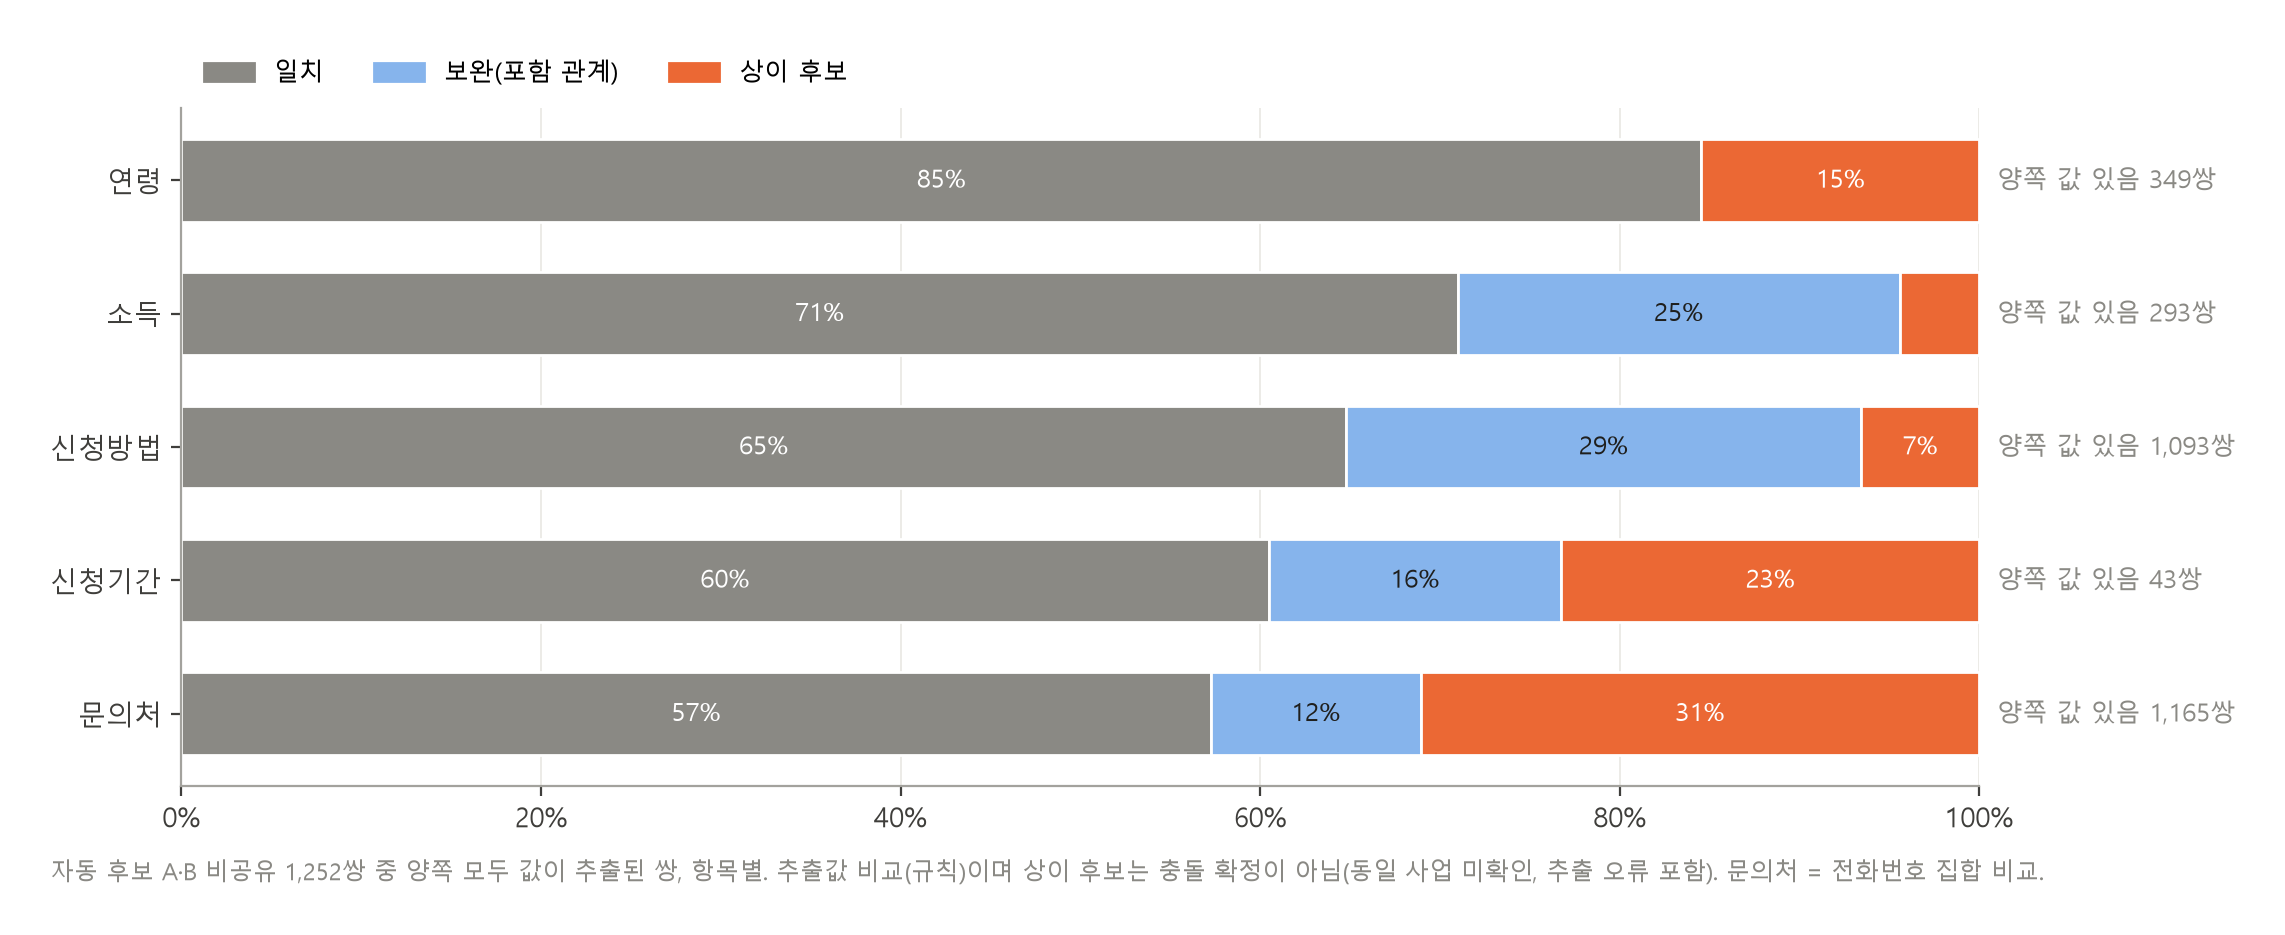

WindowsPath('outputs/04_q2/figures/final/08_content_compare.png')

In [47]:
cs, cz = CT["content_compare_summary"], CT["content_cases_human_same"]
mp = CT["match_accuracy_post_review"]
disp(mp, "표 I-5a. 사후 정정 반영 매칭 정확도", drop=["note", "method"], note="acc_before = 검수 판정 그대로(H-3, H-8-S5). AB_weighted = 층별 Jeffreys 사후 MC 중앙값과 95% 구간.")
disp(cs[cs.population.isin(["AB_nonshared", "A_nonshared", "human_same"])], "표 I-5b. 추출값 비교 — 모집단 × 항목", drop=["note", "population", "differ_ci_low", "differ_ci_high"],
     note="share_differ_of_both = 상이 후보 / 양쪽 모두 값이 뽑힌 쌍. identity_checked=False는 동일 사업 여부 미확인.")
vs = CT["content_verdict_summary"]
disp(vs, "표 I-5c. 검수 판정 — 사람 확정 동일 쌍", drop=["note", "value_diff_ci_low", "value_diff_ci_high"],
     note="diff_* = 수집 당시 플랫폼 간 차이 유형, n_* = 최종 판정. any = 쌍 단위. 규칙이 표시한 행만 검수해 건수는 하한.")
assert cz.final_verdict.notna().all() and set(cz.final_verdict) <= set(QC.VERDICTS) and cz.judged_by.eq(QC.JUDGED_BY).all()
show = cz[cz.platform_diff.eq("값 상이")][["item", "final_verdict", "ssis_name", "ssis_value", "gov_value", "official_finding", "official_checked_at"]]
disp(show.assign(item=show["item"].map(KO_I)), "표 I-5d. 수집 당시 양쪽 값이 다른 사례와 공식 기준 확인 결과", note="양쪽 원문과 출처 URL은 content_cases_human_same.csv(ssis_text, gov_text, ssis_url, gov_url).")
for r in cz[cz.final_verdict.eq("실제 충돌")].itertuples():
    md(f"**{KO_I[r.item]} — {r.ssis_name}**\n- 수집 당시 차이: {r.platform_diff_note}\n- 공식 기준 확인({r.official_checked_at}): {r.official_finding}\n"
       f"- SSIS `{r.servId}`: {r.ssis_text[:260]}\n  - 출처: {r.ssis_url}\n- 보조금24 `{r.gov_id}`: {r.gov_text[:260]}\n  - 출처: {r.gov_url}")
fig, ax = plt.subplots(figsize=(11.6, 4.4))
CLS_C = {"일치": "#8a8984", "보완(포함 관계)": C_LIGHT, "상이 후보": C_ORANGE}
ca = cs[cs.population == "AB_nonshared"].set_index("item")
for k, it in enumerate(QC.CONTENT_ITEMS):
    r = ca.loc[it]; left = 0.0
    for c, col in CLS_C.items():
        v = r[f"n_{c}"] / r.n_both_valued
        ax.barh(k, v, left=left, color=col, edgecolor="white", height=0.62)
        if v >= 0.05:
            ax.text(left + v / 2, k, f"{100 * v:.0f}%", ha="center", va="center", fontsize=9, color="white" if c != "보완(포함 관계)" else INK)
        left += v
    ax.text(1.01, k, f"양쪽 값 있음 {int(r.n_both_valued):,}쌍", va="center", fontsize=9, color=MUTED)
ax.set_yticks(range(len(QC.CONTENT_ITEMS))); ax.set_yticklabels([KO_I[i] for i in QC.CONTENT_ITEMS]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=l) for l, c in CLS_C.items()], ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
save_fig(fig, "08_content_compare", f"자동 후보 A·B 비공유 {int(POPN['AB_nonshared']):,}쌍 중 양쪽 모두 값이 추출된 쌍, 항목별. 추출값 비교(규칙)이며 상이 후보는 충돌 확정이 아님"
         "(동일 사업 미확인, 추출 오류 포함). 문의처 = 전화번호 집합 비교.", folder=FFIG)

In [48]:
ch = cs[cs.population == "human_same"].set_index("item"); va = vs.set_index("item")
n_same = int(va.loc["any", "n_human_same_pairs"])
mpI = mp.set_index("tier"); abw = mpI.loc["AB_weighted"]
vd = cz[cz.platform_diff.eq("값 상이")]
OBS["content"] = "\n".join([
    f"- 사후 매칭 정정 {int(mpI.n_post_review.loc[list('ABCU')].sum())}건: B 등급 동일 {kn(mpI.loc['B','n_same_before'], mpI.loc['B','n_confirmed'])} → {kn(mpI.loc['B','n_same'], mpI.loc['B','n_confirmed'])}, A·B 층 가중 정확도 {abw.acc_before:.2f} → {abw.acc:.2f}(95% 구간 {abw.acc_ci_low:.2f}~{abw.acc_ci_high:.2f})",
    "- 자동 후보 A·B 비공유 쌍, 양쪽 값이 있는 쌍 중 상이 후보: " + ", ".join(f"{KO_I[i]} {kn(ca.loc[i,'n_상이 후보'], ca.loc[i,'n_both_valued'])}({PCT(ca.loc[i,'share_differ_of_both'])})" for i in QC.CONTENT_ITEMS),
    f"- 신청 기한은 양쪽 값이 모두 있는 쌍이 {int(ca.loc['period','n_both_valued'])}쌍뿐, 보조금24 '상시신청'만 있는 쌍 {int(ca.loc['period','n_기본값 후보만'])}쌍",
    f"- 사람 확정 동일 {n_same}쌍 중 수집 당시 양쪽 값이 다른 쌍 {int(va.loc['any','diff_값 상이'])}쌍({PCT(va.loc['any','share_value_diff_of_same'])}, 95% CI {ci2(va.loc['any','value_diff_ci_low'], va.loc['any','value_diff_ci_high'])})",
    "  - " + ", ".join(f"{KO_I[i]} {int(va.loc[i,'diff_값 상이'])}건" for i in QC.CONTENT_ITEMS if va.loc[i, "diff_값 상이"] > 0),
    f"- 공식 기준 확인 결과: 실제 충돌 {int(va.loc['any','n_실제 충돌'])}쌍(최신 기준과 다른 쪽 확인), 나머지 {int((vd.final_verdict == '확인 불가').sum())}쌍은 확인 불가",
    "  - " + "; ".join(f"{r.ssis_name}: {r.official_finding}" for r in cz[cz.final_verdict.eq("실제 충돌")].itertuples()),
    f"- 한쪽에만 적힌 추가 신청 경로 {int(va.loc['channel','diff_한쪽 추가 기재'])}건은 공식 확인이 안 되어 확인 불가",
    f"- 전화번호가 하나도 겹치지 않는 쌍 {int(va.loc['contact','diff_번호 상이'])}/{int(ch.loc['contact','n_both_valued'])}(충돌로 판정하지 않음)",
    "- 최종 판정(행 기준): " + ", ".join(f"{v} {int((cz.final_verdict == v).sum())}" for v in QC.VERDICTS)])
INT["content"] = "\n".join([
    "- 동일 사업으로 확인된 쌍에서도 연령 상한, 소득 기준, 신청 기한, 신청 가능 여부가 다르게 적힌 사례 존재",
    "- 확인된 충돌 2건은 이전 기준이 남은 쪽이 서로 다름(보조금24 1건, SSIS 1건) → 어느 한 플랫폼이 항상 최신이라고 볼 수 없음",
    "- 값이 다른 쌍의 다수는 공개 자료만으로 어느 쪽이 맞는지 가릴 수 없음 → 통합 시 차이 표시와 문의처 안내 필요"])
LIM["content"] = "\n".join([
    f"- 표본 {n_same}쌍, 구간 넓음. 전체 비율로 일반화하지 않음",
    "- 규칙이 보완 또는 상이 후보로 표시한 행만 검수해 값 상이 건수는 하한",
    "- 자동 후보 쌍의 상이 후보에는 다른 사업, 추출 오류(자녀 연령, 예외 조항) 포함",
    "- 공식 기준 확인은 검수 시점(2026-11-12) 기준, 수집 시점(SSIS 2026-10-30, 보조금24 2026-10-31)과 다름",
    "- 확인 불가는 충돌 없음이 아님. 전화 문의 등 추가 확인이 필요한 상태",
    "- 전화번호 불일치는 번호 유효성 미확인(담당자, 안내 창구 차이 가능)"])
md("**관찰**\n" + OBS["content"] + "\n\n**해석**\n" + INT["content"] + "\n\n**한계**\n" + LIM["content"])

**관찰**
- 사후 매칭 정정 1건: B 등급 동일 11/15 → 10/15, A·B 층 가중 정확도 0.83 → 0.82(95% 구간 0.64~0.92)
- 자동 후보 A·B 비공유 쌍, 양쪽 값이 있는 쌍 중 상이 후보: 연령 54/349(15.5%), 소득 13/293(4.4%), 신청방법 72/1093(6.6%), 신청기간 10/43(23.3%), 문의처 362/1165(31.1%)
- 신청 기한은 양쪽 값이 모두 있는 쌍이 43쌍뿐, 보조금24 '상시신청'만 있는 쌍 645쌍
- 사람 확정 동일 38쌍 중 수집 당시 양쪽 값이 다른 쌍 5쌍(13.2%, 95% CI 5.8~27.3%)
  - 연령 1건, 소득 1건, 신청방법 2건, 신청기간 1건
- 공식 기준 확인 결과: 실제 충돌 2쌍(최신 기준과 다른 쪽 확인), 나머지 3쌍은 확인 불가
  - 아동수당 지급: 2026년 최신 기준은 만 9세 미만. SSIS와 일치, 보조금24의 만 8세 미만은 이전 기준; 출산축하금 및 장려금 지원: 최신 조례 기준 출생, 입양신고일부터 6개월 이내 신청. 보조금24 본문과 일치, SSIS의 90일 이내는 이전 기준
- 한쪽에만 적힌 추가 신청 경로 8건은 공식 확인이 안 되어 확인 불가
- 전화번호가 하나도 겹치지 않는 쌍 15/38(충돌로 판정하지 않음)
- 최종 판정(행 기준): 실제 충돌 2, 확인 불가 12, 상호 보완 3, 표현 차이 4, 번호 상이(충돌 아님) 15

**해석**
- 동일 사업으로 확인된 쌍에서도 연령 상한, 소득 기준, 신청 기한, 신청 가능 여부가 다르게 적힌 사례 존재
- 확인된 충돌 2건은 이전 기준이 남은 쪽이 서로 다름(보조금24 1건, SSIS 1건) → 어느 한 플랫폼이 항상 최신이라고 볼 수 없음
- 값이 다른 쌍의 다수는 공개 자료만으로 어느 쪽이 맞는지 가릴 수 없음 → 통합 시 차이 표시와 문의처 안내 필요

**한계**
- 표본 38쌍, 구간 넓음. 전체 비율로 일반화하지 않음
- 규칙이 보완 또는 상이 후보로 표시한 행만 검수해 값 상이 건수는 하한
- 자동 후보 쌍의 상이 후보에는 다른 사업, 추출 오류(자녀 연령, 예외 조항) 포함
- 공식 기준 확인은 검수 시점(2026-11-12) 기준, 수집 시점(SSIS 2026-10-30, 보조금24 2026-10-31)과 다름
- 확인 불가는 충돌 없음이 아님. 전화 문의 등 추가 확인이 필요한 상태
- 전화번호 불일치는 번호 유효성 미확인(담당자, 안내 창구 차이 가능)

## I-6. 종합 — Q2 결론과 서비스 필요성
- 아래 문구는 I-1 ~ I-5 수치에서 생성

In [49]:
STORY = [
    ("1. 정보가 어디에 분산되어 있는가", [
        f"한 출처만으로 핵심 6항목이 모두 명시된 서비스: SSIS {PCT(A['ssis'].share_complete)}, 보조금24 {PCT(A['gov'].share_complete)}(A·B 비공유 {int(POPN['AB_nonshared']):,}쌍, all)",
        f"신청 절차 정보는 보조금24 구조화 필드에 집중(신청 4항목 확인 {PCT(A['gov'].share_complete_application)} 대 SSIS {PCT(A['ssis'].share_complete_application)})",
        f"자격 정보는 SSIS 쪽이 조금 더 많음(자격 2항목 확인 {PCT(A['ssis'].share_complete_eligibility)} 대 {PCT(A['gov'].share_complete_eligibility)})"]),
    ("2. 통합하면 무엇이 개선되는가", [
        f"명시 항목 수 평균 SSIS {A['ssis'].mean_explicit:.2f} → 통합 {A['union'].mean_explicit:.2f}, 부족 3항목 이상 {PCT(A['ssis'].share_short_ge3)} → {PCT(A['union'].share_short_ge3)}",
        f"SSIS만 보는 사용자의 {PCT(sv.loc[('all','vs_ssis'),'share_gain_ge1'])}가 1항목 이상 추가 확인(신청기간, 구비서류 중심)",
        f"더 나은 한 출처와 비교해도 {PCT(sv.loc[('all','vs_better_single'),'share_gain_ge1'])}에서 추가 확인",
        "방향은 A 등급, 사람 확정 동일 쌍, 기본값 제외, 부분 인정에서 모두 유지"]),
    ("3. 청년 대상 서비스에서도 같은 문제가 나타나는가", [
        f"엄격 S2 {int(POPN['youth_S2_AB'])}쌍에서도 같은 방향: 명시 평균 SSIS {Y['ssis'].mean_explicit:.2f}, 보조금24 {Y['gov'].mean_explicit:.2f}, 통합 {Y['union'].mean_explicit:.2f}",
        f"통합 후에도 6항목 완비는 {PCT(Y['union'].share_complete)}. 전체보다 높은 수준은 연령 항목 영향(연령 제외 5항목 평균 {Y5.mean_explicit:.2f} 대 {N5.mean_explicit:.2f})",
        f"남는 부족은 소득 기준({PCT(yis.loc['income','share_short_union'])})에 집중, 통합 이득은 경제적 지원과 주거 영역에서 상대적으로 큼"]),
    ("4. 통합해도 남는 불확실성은 무엇인가", [
        f"통합해도 비명시: 소득 {PCT(ga.loc['income','share_neither'])}, 연령 {PCT(ga.loc['age','share_neither'])}(조건이 없는 서비스 포함 가능)",
        f"'상시신청'이 기본값이면 신청기간은 통합 후에도 {PCT(dg.loc['period','share_neither'])} 비명시, 통합 완비 {PCT(de.share_complete_union)}",
        f"동일 사업 {n_same}쌍 중 {int(va.loc['any','diff_값 상이'])}쌍에서 양쪽 값이 다름. 공식 기준으로 가려진 것은 {int(va.loc['any','n_실제 충돌'])}쌍, 나머지는 확인 불가",
        f"자동 연결 자체의 오류(A·B 층 가중 정확도 {abw.acc:.2f}, 사람 확정 쌍에서도 사후 정정 1건), 엄격 S2의 {PCT(cv.loc['youth_S2_strict','share_tier_U'])}는 자동 후보 없음"]),
    ("5. 왜 「반 걸음」이 필요한가", [
        "두 출처를 함께 보여주는 것만으로 신청 정보 공백이 줄어듦(데이터가 뒷받침)",
        "통합만으로는 부족: 비어 있는 항목과 양쪽 값이 다른 항목을 '확인 필요'로 표시하고 문의처로 연결하는 단계 필요",
        "이 분석은 설명문의 정보 명시 여부를 본 것, 사용자의 실제 탐색 부담이나 신청 성과를 측정한 것은 아님"])]
save_final(pd.DataFrame([{"step": t, "order": k + 1, "statement": s} for t, ss in STORY for k, s in enumerate(ss)]), "storyline")
md("\n\n".join(f"**{t}**\n" + "\n".join(f"- {s}" for s in ss) for t, ss in STORY))

**1. 정보가 어디에 분산되어 있는가**
- 한 출처만으로 핵심 6항목이 모두 명시된 서비스: SSIS 1.9%, 보조금24 12.5%(A·B 비공유 1,252쌍, all)
- 신청 절차 정보는 보조금24 구조화 필드에 집중(신청 4항목 확인 69.3% 대 SSIS 8.9%)
- 자격 정보는 SSIS 쪽이 조금 더 많음(자격 2항목 확인 22.2% 대 19.0%)

**2. 통합하면 무엇이 개선되는가**
- 명시 항목 수 평균 SSIS 3.09 → 통합 4.53, 부족 3항목 이상 64.3% → 6.2%
- SSIS만 보는 사용자의 87.7%가 1항목 이상 추가 확인(신청기간, 구비서류 중심)
- 더 나은 한 출처와 비교해도 20.2%에서 추가 확인
- 방향은 A 등급, 사람 확정 동일 쌍, 기본값 제외, 부분 인정에서 모두 유지

**3. 청년 대상 서비스에서도 같은 문제가 나타나는가**
- 엄격 S2 184쌍에서도 같은 방향: 명시 평균 SSIS 3.68, 보조금24 4.89, 통합 5.18
- 통합 후에도 6항목 완비는 42.9%. 전체보다 높은 수준은 연령 항목 영향(연령 제외 5항목 평균 4.18 대 3.97)
- 남는 부족은 소득 기준(42.4%)에 집중, 통합 이득은 경제적 지원과 주거 영역에서 상대적으로 큼

**4. 통합해도 남는 불확실성은 무엇인가**
- 통합해도 비명시: 소득 56.9%, 연령 47.5%(조건이 없는 서비스 포함 가능)
- '상시신청'이 기본값이면 신청기간은 통합 후에도 56.2% 비명시, 통합 완비 12.3%
- 동일 사업 38쌍 중 5쌍에서 양쪽 값이 다름. 공식 기준으로 가려진 것은 2쌍, 나머지는 확인 불가
- 자동 연결 자체의 오류(A·B 층 가중 정확도 0.82, 사람 확정 쌍에서도 사후 정정 1건), 엄격 S2의 57.8%는 자동 후보 없음

**5. 왜 「반 걸음」이 필요한가**
- 두 출처를 함께 보여주는 것만으로 신청 정보 공백이 줄어듦(데이터가 뒷받침)
- 통합만으로는 부족: 비어 있는 항목과 양쪽 값이 다른 항목을 '확인 필요'로 표시하고 문의처로 연결하는 단계 필요
- 이 분석은 설명문의 정보 명시 여부를 본 것, 사용자의 실제 탐색 부담이나 신청 성과를 측정한 것은 아님

# 부록 A. 사람 기준 보정 명시율
- 팀 결정에 따라 본문에서 분리한 보조 분석
- 작은 표본과 넓은 구간 → 확정 추정치로 쓰지 않음

## A-1. 보정 명시율 세부
- 대상: 자동 후보 A·B 비공유 쌍, text, 항목×side
- 보정: 규칙 라벨 층 안 사람 확정 라벨의 명시 비율을 층 N_h로 가중
- 분모: 사람 수준 라벨(명시, 부분, 미명시), 사람 메타 라벨 제외
- 점추정: 같은 MC 추출의 사후 중앙값(구간 안), 단순 층 가중값은 `p_plugin`
- 구간: 층별 Jeffreys 사후 MC 결합(근사)
- 비교: 같은 층의 규칙 라벨 명시율(`p_rule`, 규칙 메타 층 제외)

In [50]:
c1 = ST["supp_calibrated_explicitness"]
disp(c1, "표 H-8a. 보정 명시율(참고 추정) — 규칙 명시율 대 사람 기준 보정", drop=["note", "strata_detail", "ci_method", "dropped_strata", "N_total", "estimate_definition"],
     note="p_cal = 층별 Jeffreys 사후 MC 중앙값, p_plugin = 단순 층 N_h 가중 사람 명시 비율. 구간 = 층별 Jeffreys 사후 MC 결합(근사). 플랫폼 간 검정은 표본 부족으로 하지 않음.")
core1 = c1[c1.core_metric].copy()
inside = core1[(core1.p_rule >= core1.p_cal_ci_low) & (core1.p_rule <= core1.p_cal_ci_high)]
assert (c1.status == "참고 추정(표본 부족)").all()
OBS["s1"] = "\n".join(
    ["- 핵심 6항목×2side, 규칙 명시율 → 보정 명시율(사후 중앙값, 95% 구간)"]
    + [f"  - {KO[r['item']]} {SL[r.side]}: {PCT(r.p_rule)} → {PCT(r.p_cal)}({ci2(r.p_cal_ci_low, r.p_cal_ci_high)})" for _, r in core1.iterrows()]
    + [f"- 규칙 명시율이 사람 기준 95% 구간 안: {len(inside)}/{len(core1)}개",
       f"- 층별 사람 수준 라벨 수 m_h 최소 {int(c1.min_m_h.min())}~{int(c1.min_m_h.max())}건, 모든 행 `참고 추정(표본 부족)`"])
INT["s1"] = "\n".join([
    "- 사람 기준 구간이 넓어 규칙 명시율과의 차이 판단 불가",
    "- 규칙 명시율이 사람 기준과 크게 어긋난다는 근거 없음, 일치한다는 근거도 약함",
    "- 중앙값과 규칙값의 차이는 사전분포 영향이 커서 방향 해석에 쓰지 않음"])
LIM["s1"] = "\n".join([
    "- 층당 사람 수준 라벨 1~3건, 점추정 불안정",
    "- 단순 층 가중값은 표에 별도 열(p_plugin)",
    "- 사후 중앙값은 Jeffreys 사전 때문에 0.5 쪽으로 이동, 낮은 비율 항목에서 단순 층 가중값보다 커짐",
    "- p_rule은 규칙 수준 층(명시, 부분, 미명시)만 분모로 사용, 규칙 메타 층 제외",
    "- 금표준 = A·B 비공유 쌍의 text 범위, all 범위와 C 등급 쌍은 사람 검증 없음",
    "- 플랫폼 간 검정은 표본 부족으로 하지 않음"])
TEAM["s1"] = "\n".join([
    "- 결정: 부록 배치, 본문은 보정 전후 방향 유지 여부만 요약",
    "- 결정: 부분 경계 사례는 v3.2 예시로 추가, 별도 표본 검증"])
md("**결과 수치**\n" + OBS["s1"] + "\n\n**해석**\n" + INT["s1"] + "\n\n**한계**\n" + LIM["s1"] + "\n\n**결정**\n" + TEAM["s1"])

**표 H-8a. 보정 명시율(참고 추정) — 규칙 명시율 대 사람 기준 보정**

item,side,core_metric,N_used,n_strata_used,n_strata_dropped,n_confirmed,m_total,k_total,min_m_h,p_rule,p_cal,p_plugin,p_cal_ci_low,p_cal_ci_high,diff_cal_minus_rule,status
age,ssis,True,863,3,0,9,9,6,3,0.482,0.639,0.670,0.413,0.792,0.157,참고 추정(표본 부족)
age,gov,True,863,3,0,9,9,2,3,0.443,0.353,0.295,0.125,0.565,-0.090,참고 추정(표본 부족)
income,ssis,True,863,3,0,9,9,5,3,0.382,0.555,0.588,0.315,0.844,0.172,참고 추정(표본 부족)
income,gov,True,863,3,0,9,9,6,3,0.333,0.536,0.566,0.299,0.847,0.203,참고 추정(표본 부족)
residence,ssis,False,863,3,0,9,9,5,3,0.565,0.597,0.611,0.343,0.768,0.031,참고 추정(표본 부족)
residence,gov,False,863,3,0,9,9,4,3,0.509,0.411,0.372,0.152,0.648,-0.098,참고 추정(표본 부족)
channel,ssis,True,863,3,0,9,9,4,3,0.797,0.778,0.816,0.415,0.871,-0.019,참고 추정(표본 부족)
channel,gov,True,863,3,0,9,9,6,3,0.984,0.923,0.992,0.474,0.993,-0.061,참고 추정(표본 부족)
period,ssis,True,863,3,0,9,7,3,1,0.122,0.170,0.119,0.086,0.573,0.048,참고 추정(표본 부족)
period,gov,True,863,3,0,9,8,2,2,0.070,0.114,0.043,0.032,0.514,0.044,참고 추정(표본 부족)


<span style='color:#8a8984;font-size:90%'>p_cal = 층별 Jeffreys 사후 MC 중앙값, p_plugin = 단순 층 N_h 가중 사람 명시 비율. 구간 = 층별 Jeffreys 사후 MC 결합(근사). 플랫폼 간 검정은 표본 부족으로 하지 않음.</span>

**결과 수치**
- 핵심 6항목×2side, 규칙 명시율 → 보정 명시율(사후 중앙값, 95% 구간)
  - 연령 SSIS: 48.2% → 63.9%(41.3~79.2%)
  - 연령 보조금24: 44.3% → 35.3%(12.5~56.5%)
  - 소득 SSIS: 38.2% → 55.5%(31.5~84.4%)
  - 소득 보조금24: 33.3% → 53.6%(29.9~84.7%)
  - 신청방법 SSIS: 79.7% → 77.8%(41.5~87.1%)
  - 신청방법 보조금24: 98.4% → 92.3%(47.4~99.3%)
  - 신청기간 SSIS: 12.2% → 17.0%(8.6~57.3%)
  - 신청기간 보조금24: 7.0% → 11.4%(3.2~51.4%)
  - 구비서류 SSIS: 25.7% → 22.8%(5.3~63.0%)
  - 구비서류 보조금24: 14.6% → 15.5%(4.3~51.5%)
  - 문의처 SSIS: 0.3% → 6.9%(0.3~52.6%)
  - 문의처 보조금24: 2.2% → 8.5%(1.8~53.3%)
- 규칙 명시율이 사람 기준 95% 구간 안: 12/12개
- 층별 사람 수준 라벨 수 m_h 최소 1~3건, 모든 행 `참고 추정(표본 부족)`

**해석**
- 사람 기준 구간이 넓어 규칙 명시율과의 차이 판단 불가
- 규칙 명시율이 사람 기준과 크게 어긋난다는 근거 없음, 일치한다는 근거도 약함
- 중앙값과 규칙값의 차이는 사전분포 영향이 커서 방향 해석에 쓰지 않음

**한계**
- 층당 사람 수준 라벨 1~3건, 점추정 불안정
- 단순 층 가중값은 표에 별도 열(p_plugin)
- 사후 중앙값은 Jeffreys 사전 때문에 0.5 쪽으로 이동, 낮은 비율 항목에서 단순 층 가중값보다 커짐
- p_rule은 규칙 수준 층(명시, 부분, 미명시)만 분모로 사용, 규칙 메타 층 제외
- 금표준 = A·B 비공유 쌍의 text 범위, all 범위와 C 등급 쌍은 사람 검증 없음
- 플랫폼 간 검정은 표본 부족으로 하지 않음

**결정**
- 결정: 부록 배치, 본문은 보정 전후 방향 유지 여부만 요약
- 결정: 부분 경계 사례는 v3.2 예시로 추가, 별도 표본 검증